# Function 6

<b> Description of the Sample Application:</b> You’re optimising a cake recipe using a black-box function with five ingredient inputs, for example flour, sugar, eggs, butter and milk. Each recipe is evaluated with a combined score based on flavour, consistency, calories, waste and cost, where each factor contributes negative points as judged by an expert taster. This means the total score is negative by design. 
To frame this as a maximisation problem, your goal is to bring that score as close to zero as possible or, equivalently, to maximise the negative of the total sums# Final Status (After Round 13)

| Item | Value |
|---|---|
| Final best observed output | **-0.213554** at (0.397963, 0.353972, 0.655982, 0.839288, 0.023550) (Week 13) |
| Improvement over the previous best (Week 12, -0.362411) | +0.1489 (penalty ~41% smaller) |
| Improvement over the best of the initial 20 points (-0.7143) | +0.5007 (penalty ~70% smaller) |
| Versus the reference best for Function 6 (-0.068174) | ~0.145 below it (penalty ~3.1x larger) |
| Queries used | 13 consecutive weekly submissions |
| Data points | 20 initial + 13 weekly = **33** |

**Dependent Files:**
- `initial_inputs.npy`
- `initial_outputs.npy`
- `plotting_utils.py`

**Libraries Used:**
`numpy`, `pandas`, `matplotlib`, `seaborn`, `scipy`, `scikit-learn`



# Change Log

| Date | Week | Changes Made |
|---|---|---|
| 22/07/2026 | Week 1 | 1. Initial Version with 10 Data Point |
| 22/07/2026 | Week 2 | 1. Added Change Log and Progress Log.<br>2. Added new data point. |
| 05/08/2026 | Week 3 | 1. Appended Week 2's input and output to the dataset.<br>2. Reused the Week 2 consolidated bayesian_optimization_step() function with β lowered to 1.5 (balanced explore/exploit).<br>3. Added kernel/length-scale diagnostics.<br>4. Added Week 3 convergence, parallel-coordinates and UCB-slice visualisations.<br>5. Added Week 3 portal submission string. |
| 13/08/2026 | Week 4 | 1. Appended Week 3's input and output.<br>2. Midpoint check-in after 3 underperforming corner-style queries.<br>3. Reused suggest_next_bo_point() with β lowered to 1.0. |
| 20/08/2026 | Week 5 | 1. Appended Week 4's input and output.<br>2. **Strategy change**: pivoted from global UCB search to a local/trust-region search (radius=0.15) centred on the current best point, β=0.75. |
| 02/09/2026 | Week 6 | 1. Appended Week 5's input and output to the dataset.<br>2. **Strategy review**: Week 5's trust-region search *also* underperformed, and landed on the exact same corner of the trust region as Week 4's query, showing the box-boundary-seeking pathology persists even locally.<br>3. Extended suggest_next_bo_point_local() to accept a **per-dimension radius** and tested a widened box specifically along sugar/milk. The automated search still collapsed to the same corner, since our own data has never covered a genuinely high-sugar/high-milk combination.<br>4. Given the automated recommendation offered no new information, this week uses a **deliberate, manually-chosen hypothesis-driven query**: keep flour/eggs/butter near Week 1's successful profile, but raise sugar and milk into a region our data has never actually tested.<br>5. Reported the GP's own (honest, high-uncertainty) prediction at this manual point for transparency, alongside updated diagnostics, visualisations and portal submission. |
| 09/09/2026 | Week 7 | 1. Appended Week 6's input/output to the dataset. Week 6's manual hypothesis paid off resulting in a **new best, -0.465434, a large jump from -0.710675.**<br>2. **Hyperparameter tuning**: widened the RBF kernel's length_scale_bounds upper limit from 10 to 50, since several dimensions had been pinned at the old bound in earlier week, implying that the bound itself was constraining the fit, not just the data.<br>3. Re-centred the trust-region search on the **new** best point (Week 6's), radius=0.15, β lowered to 0.5 (near-exploitation, since this region is now genuinely confirmed as promising.<br>4. Updated kernel diagnostics. |
| 16/09/2026 | Week 8 | 1. Appended Week 7's input/output.<br>2. Shrunk the trust region(radius 0.15 -> 0.07) around it and switched the local acquisition from UCB (mean + β·σ) to facilitate pure mean-exploitation over a dense interior grid, specifically to stop the acquisition optimiser from repeatedly landing on trust-region edges. |
| 23/09/2026 | Week 9 | 1. Appended Week 8's input/output to the dataset.<br>2. Week 8's more conservative, closer-in exploitation (distance 0.113 from Week 6) still underperformed Week 7's more exploratory point (distance 0.262), even though Week 8's own GP predicted a better mean than the current best. Meanwhile, re-testing gradient-based UCB with a widened radius reproduced the exact same edge-of-box behaviour Week 8 was built to avoid.<br>3. **Strategy Change**: Kept Week 8's edge-avoiding random-candidate mean-exploitation approach (since it structurally fixes the boundary bias that plain UCB re-introduces), but widened the trust-region radius from 0.07 to **0.12**, enough to reach territory not yet sampled by Weeks 6, 7 or 8, while stopping well short of Week 7's box-edge leap, which also underperformed. |
| 30/09/2026 | Week 10 | 1. Appended Week 9's input/output to the dataset. Week 9's widened radius (0.12) scored **-0.551631**. Worse than Week 6 but better than both Week 7 (-0.628456) and Week 8 (-0.640971), continuing a monotonic improvement as the trust-region radius widened (0.07 → 0.12).<br>2. **Strategy change**: Swept the trust-region radius from 0.07 to 0.30 and computed the actual **Expected Improvement (EI)** at the best candidate in each box (not just predicted mean), since pure mean-exploitation alone gave no principled way to pick a radius and has previously been overconfident (Week 8). EI peaks at **radius = 0.20** and is essentially flat out to 0.30, indicating a genuine local mode rather than an artifact of a bigger search box.<br>3. At radius 0.20 the EI-maximising candidate sits in a **new region** - sugar and eggs raised further, milk pushed close to 0, butter kept high, rather than just a bigger step in the Week 7-9 direction. This is the first candidate whose GP-predicted mean (-0.456913) exceeds the current best (-0.465434). Verified stable across 5 random seeds (predicted means all within -0.446 to -0.466 of each other, same region).<br>4. Flagged a genuine risk for transparency: Milk and sugar both show a strong *negative* correlation with Y across 29-point dataset, which looks like it argues against this move. But that correlation is confounded by the early corner-search points (which combined low sugar/milk with extreme butter/eggs and scored badly for other reasons). Addressed explicitly in the Week 10 reflection. |
| 05/10/2026 | Week 11 | 1. Appended Week 10's input/output to the dataset (30 points total). Week 10 scored **-0.401802** - a **new best**, beating Week 6's -0.465434 by a wide margin, and confirming the EI-radius-sweep strategy introduced last week.<br>2. **Clustering analysis**: ran KMeans on the 10 weekly query points to directly test for recurring promising/unpromising regions. Weeks 6-10 cluster together distinctly (mean y=-0.538, includes both of our two best results), separate from Weeks 3-4 (mean y=-1.228, the worst cluster) and Weeks 1-2-5 (mean y=-0.955). On the full 30-point dataset, all 10 of our own queries land in a single cluster distinct from the two initial-data clusters, whose best member is still worse than our worst post-Week-6 query — confirming our own local search has outperformed the broader initial coverage.<br>3. **Strategy continuation, re-centred**: re-ran the same Expected Improvement radius-sweep approach that found Week 10, but centred on **Week 10's point** (the new best) instead of Week 6. EI now peaks at a much **tighter radius (0.05)**, essentially flat across 0.03-0.06, suggesting we are now refining within a genuine local optimum rather than searching for a new one.<br>4. ξ was lowered from 0.01 to 0.005 for a slightly more exploitative EI, while still keeping a small margin. |
| 14/10/2026 | Week 12 | 1. Appended Week 11's input/output to the dataset (31 points total). Week 11 scored **-0.520103** — **worse than both Week 10 (-0.401802) and Week 6 (-0.465434)**, despite being the EI-recommended point. This is direct, numeric evidence of the 'edge-seeking' pathology we have been tracking all project: even EI/mean-based exploitation pushed butter to 0.999604 (right at the global bound) on the strength of the GP's smooth-extrapolation assumption alone, with no real nearby evidence -- and it did not pay off.<br>2. **Strategy change (WEEK 12 STRATEGY)**: re-ran the standard EI-sweep (same method, now on 31 points, re-centred on Week 10) and found it **still points back toward the same risky near-edge butter region (~0.996-0.998)** - i.e. the GP has not 'learned its lesson' on its own; its length-scales are long enough that one bad edge result barely dents its optimism there. Rather than follow EI blindly into a region that already underperformed once, we introduce a **capped-EI** variant: the same Expected-Improvement search, but with butter's candidate range explicitly capped below the level that just failed, forcing the search to recommend something genuinely new rather than a near-repeat of Week 11.<br>3. Swept the cap from 0.90 up to 0.99: EI and predicted mean both rise monotonically as the cap is relaxed back toward Week 10's own already-validated butter level (0.9806), confirming the GP's optimism really is concentrated at the edge. We deliberately did **not** take the edge-most option. We chose **butter_cap = 0.94, radius = 0.08**, which lands at butter approx 0.938 -- a point between Week 9's level (0.971878) and the lower end of our post-Week-6 cluster, genuinely untested by any prior query, and stable across 5 random seeds.<br>4. **Endgame**: only 1 query remains after this (Week 13, now the true final submission). Kept ξ=0.005 (unchanged from Week 11) -- still slightly exploitative, but Week 12 is being used deliberately to buy **new information** about the mid-butter region before the final committed query, rather than to chase the highest raw EI value.<br>5. Added a genuine **PCA analysis** of the full 31-point input dataset (reflecting this week's module theme): PC1 explains ~43% of input-space variance and is dominated by butter/milk/sugar, matching the GP's own ARD length-scales (flour and sugar have the shortest length-scales -> output is most sensitive to them; milk has by far the longest length-scale -> least sensitive/most 'redundant' dimension). Extended the best-of-breed dashboard with a PCA-variance panel and an EI-potential-by-cap panel, directly inspired by the uploaded sample.jpg layout (current-best-vs-predicted, weekly trajectory, model-error/length-scale diagnostics, EI-potential bars) but adapted to Function 6's single running optimisation rather than a multi-model comparison. |
| 27/10/2026 | Week 13 (FINAL) | 1. Appended Week 11 (corrected) and Week 12 results; dataset is now 32 points. Week 12 scored **-0.362411**, a **new best** (previous best Week 10, -0.401802).<br>2. **Data-integrity fix (important)**: the Week 11 entry in the data cell was a copy of Week 1's point/output (0.409594-0.023713-0.771229-0.966490-0.130973 / -0.710675) instead of the real Week 11 result (0.413163-0.457770-0.571463-0.999604-0.002310 / -0.520103). Consequently the point actually submitted for Week 12 (0.416510-0.439928-0.601021-0.939311-0.000363) was computed on a dataset with that wrong row; the Week 12 section below is frozen to the data as of that decision and re-run on the corrected data for transparency (corrected-data Week 12 point: 0.426671-0.450813-0.612640-0.938186-0.000465).<br>3. **Strategy review**: refitting the usual RBF-GP on the corrected 32 points and searching around the new best still pushes butter back to ~0.997 (the same edge that gave -0.520 in Week 11), and the GP under-predicts the new best (its fit at Week 12's point is -0.44 where -0.362 was observed). Local evidence points the other way: across Weeks 11, 10 and 12, butter 0.9996 / 0.981 / 0.939 gave -0.520 / -0.402 / -0.362, i.e. lower butter has been better.<br>4. **Strategy change**: replaced the surrogate by a **standardised-output Matérn-2.5 ARD GP** (leave-one-out RMSE 0.227 vs 0.324 for the previous RBF-GP and mean forward error over Weeks 7-12 0.128 vs 0.202, but its stated uncertainty is too narrow (forward z up to -4.0), so it is used inside a **30-member bootstrap ensemble**). Replaces quadratic+GP / pure-exploitation draft. <br>5. Added a **second-maximum analysis** (mode search, line scan, bootstrap maxima) and a 6-panel dashboard plus a butter-vs-milk surface. |
| 31/10/2026 | Final | 1. Added the Week 13 result (input 0.397963-0.353972-0.655982-0.839288-0.023550, output **-0.213554**): a **new best** (previous best Week 12, -0.362411); the dataset is now 33 points.<br> 2. No new query is submitted this week; this is the full and final file for the repo.<br> 3. The Week 13 analysis cells are frozen to the 32 points known at the Week 13 decision, so they still show what the model predicted and why that point was chosen.<br> 4. Data-integrity guard extended to 13 weekly rows / 33 points. Added a **final dashboard** comparing the Week 13 prediction with the actual result and a 33-point refit. |


# Progress Log

| Week | Query Point (x) | Output (y) | Acquisition / β | Notes |
|---|---|---|---|---|
|  |  |  |  |  |
| Week 1 | 0.409594-0.023713-0.771229-0.966490-0.130973 | **-0.710675** | UCB, β = 2.5 (high exploration) | Slight improvement over the initial best (-0.714265); high β used deliberately since only 20 points were available in 5D |
| Week 2 | 0.408768-0.000000-0.999999-0.999999-0.000000 | -1.048677 | UCB, β = 2.0 | Worse than the current best, and worse than the GP's own predicted mean (-0.296). The corner-point extrapolation (eggs-butter maxed, sugar-milk minimised) did not pay off — a useful signal that the RBF surrogate's smoothness assumption may not hold well at the boundary. Current best remains Week 1's point. |
| Week 3 | 0.000000-0.000000-0.392984-0.999999-0.000000 | -1.359780 | UCB, β = 1.5 | Worse again |
| Week 4 | 0.535575-0.000000-0.368390-0.999999-0.000000 | -1.095880 | UCB, β = 1.0 | Fourth underperforming query in the same corner region |
| Week 5 | 0.259594-0.000000-0.921229-0.999999-0.000000 | -1.104114 | Local UCB, β = 0.75, radius = 0.15 | Even the trust-region/local search underperformed, and landed on the exact same point Week 4 already tried, confirming the boundary-seeking pathology persists locally, not just globally |
| Week 6 | 0.410000-0.250000-0.770000-0.970000-0.200000 | **-0.465434** | Manual, hypothesis-driven | **New best result** confirms the hypothesis that higher sugar/milk (alongside Week 1's flour/eggs/butter profile) genuinely helps, a large jump from -0.710675 |
| Week 7 |0.403491-0.400000-0.920000-0.999999-0.050000- |-0.628456 | Local UCB, β=0.5, trust region radius=0.15 around Week 6's new best | Refining around the newly confirmed good region; kernel hyperparameters re-tuned this roun.) 
| Week 8 | 0.447072-0.302740-0.826230-0.998456-0.267531 | -0.640971 | Mean-exploitation, dense interior grid, radius=0.07 around Week 6's point | Since Week 7's larger, edge-seeking step failed, this round shrinks the search radius substantially and removes the uncertainty term entirely, directly querying only the GP's most-trusted, best-predicted point in a tight neighbourhood |
| Week 9 |  0.466591-0.364801-0.886231-0.971878-0.091743 | -0.551631 | Pure mean-exploitation, radius widened to 0.12 around Week 6 | Keeps the edge-avoiding candidate-based search (re-tested gradient UCB at a wider radius and it reproduced the same box-edge pathology), but reaches further than Week 8's overly conservative 0.07 without repeating Week 7's full leap to the box edge. |
| Week 10 | 0.392380-0.427447-0.598043-0.980637-0.009115 | **-0.401802** | Expected Improvement (EI, ξ=0.01), radius swept 0.07-0.30, best at radius=0.20 | **Strategy change**: EI-driven radius selection instead of manual widening. Lands in a new region (very low milk, higher eggs) whose predicted mean (-0.456913) is the first to exceed the current best. |
| Week 11 | 0.413163-0.457770-0.571463-0.999604-0.002310 | -0.520103 | Expected Improvement (EI, ξ=0.005), radius swept around **Week 10**, best at radius=0.05 | **Underperformed** (worse than Weeks 10 and 6): EI pushed butter to 0.999604, the global edge, on extrapolation alone. |
| Week 12 | 0.416510-0.439928-0.601021-0.939311-0.000363 | **-0.362411** | **Capped-EI** (ξ=0.005): butter candidate range capped at 0.94, radius=0.08, re-centred on Week 10 | **New best** (previous -0.401802). Lowering butter from the edge helped. Note: the submitted point was computed while the Week 11 data row was wrongly a copy of Week 1; corrected in Week 13 (see Change Log). |
| Week 13 (final) | 0.397963-0.353972-0.655982-0.839288-0.023550 | **-0.213554** | **Bag-averaged Expected Improvement** (30 bootstrap + full-data standardised Matérn-2.5 GPs) over the best observed value; centre of top-300 candidates, stable across independent ensembles | **Strategy change (v2).** Standardised Matérn has lower LOO and forward error but is overconfident, so the ensemble hedges between the surrogate's mode and the Week 12 region instead of trusting one fit. <<new_final>> **New best** (previous -0.362411): the hedge between the surrogate's mode and Week 12's region beat Week 12 and beat the ensemble's predicted mean (-0.342); the single standardised Matern fit had predicted -0.212. No further submission. |

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from scipy.spatial.distance import pdist
from scipy.optimize import minimize

from plotting_utils import plot_convergence, plot_parallel_coordinates

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

import warnings                                                    
from sklearn.exceptions import ConvergenceWarning                 
warnings.filterwarnings('ignore', category=ConvergenceWarning)

# Load and Analyse the Data

In [12]:
# File Names
input_file  = "initial_inputs.npy"
output_file = "initial_outputs.npy"

# Load the Files
X0      = np.load(input_file)
Y0      = np.load(output_file)

In [14]:
# New data from the first submission (example inputs and outputs)
X_w1_new_point = np.array([0.409594, 0.023713, 0.771229, 0.96649 , 0.130973 ]   , dtype = np.float64)    # from input.txt
Y_w1_new_point = np.array([-0.710675183457194]                                  , dtype = np.float64)    # from output.txt

# New data from Week 2 submission
X_w2_new_point = np.array([0.408768, 0.      , 0.999999, 0.999999, 0.       ]   , dtype=np.float64)    # from input.txt
Y_w2_new_point = np.array([-1.048676669557473]                                  , dtype=np.float64)    # from output.txt

# New data from Week 3 submission
X_w3_new_point = np.array([0.000000, 0.000000, 0.392984, 0.999999, 0.000000]    , dtype=np.float64)   # from input.txt
Y_w3_new_point = np.array([-1.359780271551876]                                  , dtype=np.float64)   # from output.txt

# New data from Week 4 submission
X_w4_new_point = np.array([0.535575, 0.000000, 0.368390, 0.999999, 0.000000]    , dtype=np.float64)   # from input.txt
Y_w4_new_point = np.array([-1.0958803718671517]                                 , dtype=np.float64)   # from output.txt

# New data from Week 5 submission
X_w5_new_point = np.array([0.259594, 0.000000, 0.921229, 0.999999, 0.000000]    , dtype=np.float64)  # from input.txt
Y_w5_new_point = np.array([-1.104114064436456]                                  , dtype=np.float64)  # from output.txt

# New data from Week 6 submission
X_w6_new_point = np.array([0.410000, 0.250000, 0.770000, 0.970000, 0.200000]    , dtype=np.float64)  # from input.txt
Y_w6_new_point = np.array([-0.46543419541105996]                                , dtype=np.float64)  # from output.txt 

# New data from Week 7 submission
X_w7_new_point = np.array([0.403491, 0.400000, 0.920000, 0.999999, 0.050000]    , dtype=np.float64)  # from input.txt
Y_w7_new_point = np.array([-0.6284558118853516]                                 , dtype=np.float64)  # from output.txt

# New data from Week 8 submission
X_w8_new_point = np.array([0.447072, 0.302740, 0.826230, 0.998456, 0.267531]    , dtype=np.float64)   # from input.txt
Y_w8_new_point = np.array([-0.6409714294291585]                                 , dtype=np.float64)   # from output.txt

# New data from Week 9 submission
X_w9_new_point = np.array([0.466591, 0.364801, 0.886231, 0.971878, 0.091743]    , dtype=np.float64)   # from input.txt
Y_w9_new_point = np.array([-0.5516311139016169]                                 , dtype=np.float64)   # from output.txt

# New data from Week 10 submission
X_w10_new_point = np.array([0.39238 , 0.427447, 0.598043, 0.980637, 0.009115]    , dtype=np.float64)   # from input.txt
Y_w10_new_point = np.array([-0.4018017971874759]                                 , dtype=np.float64)   # from output.txt

# New data from Week 11 submission
#---- Bug Fix 
#X_w11_new_point = np.array([0.409594, 0.023713, 0.771229, 0.96649 , 0.130973]    , dtype=np.float64)   # from input.txt
#Y_w11_new_point = np.array([-0.710675183457194]                                  , dtype=np.float64)   # from output.txt
X_w11_new_point = np.array([0.413163, 0.45777 , 0.571463, 0.999604, 0.00231 ]    , dtype=np.float64)   # from input.txt
Y_w11_new_point = np.array([-0.5201028979308556]                                 , dtype=np.float64)   # from output.txt

# New data from Week 12 submission 
X_w12_new_point = np.array([0.41651 , 0.439928, 0.601021, 0.939311, 0.000363]    , dtype=np.float64)   # from input.txt
Y_w12_new_point = np.array([-0.3624114014717784]                                 , dtype=np.float64)   # from output.txt

# New data from Week 13 submission
X_w13_new_point = np.array([0.397963, 0.353972, 0.655982, 0.839288, 0.02355 ]    , dtype=np.float64)   # from input.txt
Y_w13_new_point = np.array([-0.21355384462410984]                                , dtype=np.float64)   # from output.txt

In [16]:
# Append the new data points
X_updated      = np.vstack((X0, X_w1_new_point
                              , X_w2_new_point
                              , X_w3_new_point
                              , X_w4_new_point
                              , X_w5_new_point
                              , X_w6_new_point
                              , X_w7_new_point
                              , X_w8_new_point
                              , X_w9_new_point
                              , X_w10_new_point
                              , X_w11_new_point
                              , X_w12_new_point
                              , X_w13_new_point
                           ))
Y_updated      = np.append(Y0, [Y_w1_new_point
                             , Y_w2_new_point
                             , Y_w3_new_point
                             , Y_w4_new_point
                             , Y_w5_new_point
                             , Y_w6_new_point
                             , Y_w7_new_point
                             , Y_w8_new_point
                             , Y_w9_new_point
                             , Y_w10_new_point
                             , Y_w11_new_point
                             , Y_w12_new_point
                             , Y_w13_new_point
                              ])

In [18]:
print(X_updated)
print(Y_updated)

# Save the updated arrays
np.save(r"initial_inputs.npy", X_updated)
np.save(r"initial_outputs.npy", Y_updated)

[[7.28186105e-01 1.54692570e-01 7.32551669e-01 6.93996509e-01
  5.64013105e-02]
 [2.42384347e-01 8.44099972e-01 5.77809099e-01 6.79021284e-01
  5.01952888e-01]
 [7.29522610e-01 7.48106200e-01 6.79774641e-01 3.56552279e-01
  6.71053683e-01]
 [7.70620242e-01 1.14403744e-01 4.67799319e-02 6.48324285e-01
  2.73549053e-01]
 [6.18812299e-01 3.31802137e-01 1.87287868e-01 7.56238474e-01
  3.28834798e-01]
 [7.84958094e-01 9.10682349e-01 7.08120104e-01 9.59225429e-01
  4.91149586e-03]
 [1.45110786e-01 8.96684598e-01 8.96322235e-01 7.26271537e-01
  2.36271991e-01]
 [9.45069068e-01 2.88459051e-01 9.78805764e-01 9.61655587e-01
  5.98015936e-01]
 [1.25720155e-01 8.62724692e-01 2.85443322e-02 2.46605272e-01
  7.51206241e-01]
 [7.57594355e-01 3.55831415e-01 1.65228997e-02 4.34207205e-01
  1.12433044e-01]
 [5.36796903e-01 3.08780907e-01 4.11879285e-01 3.88225177e-01
  5.22528304e-01]
 [9.57739669e-01 2.35668572e-01 9.91458496e-02 1.56805934e-01
  7.13173731e-02]
 [6.29307895e-01 8.03483678e-01 8.114084

In [20]:
# Assign X = X_updated and Y = Y_updated
X          = X_updated
Y          = Y_updated

# Analyse the Input Data
print("Input  Shape:", X.shape)
print("Inputs:\n", X)
print()

# Analyse the Output Data
print("Output Shape:", Y.shape)
print("Outputs:\n", Y)
print()

print(f"Y Range: [: {Y.min()}, {Y.max()}]")
best_idx        = np.argmax(Y)
print(f"Best point: x = {X[best_idx]}, Y = {Y[best_idx]}")
print()

# Converting the Input and Output into a DataFram
ingredient_names = ["flour", "sugar", "eggs", "butter", "milk"]
df               = pd.DataFrame(X, columns = ingredient_names)
df['Y']          = Y
print("Data Frame:\n", df)

Input  Shape: (33, 5)
Inputs:
 [[7.28186105e-01 1.54692570e-01 7.32551669e-01 6.93996509e-01
  5.64013105e-02]
 [2.42384347e-01 8.44099972e-01 5.77809099e-01 6.79021284e-01
  5.01952888e-01]
 [7.29522610e-01 7.48106200e-01 6.79774641e-01 3.56552279e-01
  6.71053683e-01]
 [7.70620242e-01 1.14403744e-01 4.67799319e-02 6.48324285e-01
  2.73549053e-01]
 [6.18812299e-01 3.31802137e-01 1.87287868e-01 7.56238474e-01
  3.28834798e-01]
 [7.84958094e-01 9.10682349e-01 7.08120104e-01 9.59225429e-01
  4.91149586e-03]
 [1.45110786e-01 8.96684598e-01 8.96322235e-01 7.26271537e-01
  2.36271991e-01]
 [9.45069068e-01 2.88459051e-01 9.78805764e-01 9.61655587e-01
  5.98015936e-01]
 [1.25720155e-01 8.62724692e-01 2.85443322e-02 2.46605272e-01
  7.51206241e-01]
 [7.57594355e-01 3.55831415e-01 1.65228997e-02 4.34207205e-01
  1.12433044e-01]
 [5.36796903e-01 3.08780907e-01 4.11879285e-01 3.88225177e-01
  5.22528304e-01]
 [9.57739669e-01 2.35668572e-01 9.91458496e-02 1.56805934e-01
  7.13173731e-02]
 [6.29307

In [23]:
# --- WEEK 13 DATA-INTEGRITY GUARD -------------------------------------------------------------
# Last week a Week-1 row was accidentally pasted into the Week 11 slot and silently changed every
# downstream model. These checks fail loudly if a weekly row is duplicated or does not match the log.
weekly_X = [globals()[f"X_w{i}_new_point"] for i in range(1, 14)]
weekly_Y = [globals()[f"Y_w{i}_new_point"][0] for i in range(1, 14)]
assert len({tuple(np.round(x, 6)) for x in weekly_X}) == 13, "a weekly query row is duplicated!"
assert np.allclose(X_w11_new_point, [0.413163, 0.45777, 0.571463, 0.999604, 0.00231]), "Week 11 input mismatch"
assert np.isclose(Y_w11_new_point[0], -0.5201028979308556), "Week 11 output mismatch"
assert np.allclose(X_w12_new_point, [0.41651, 0.439928, 0.601021, 0.939311, 0.000363]), "Week 12 input mismatch"
assert np.isclose(Y_w12_new_point[0], -0.3624114014717784), "Week 12 output mismatch"
assert np.allclose(X_w13_new_point, [0.397963, 0.353972, 0.655982, 0.839288, 0.02355]), "Week 13 input mismatch"   
assert np.isclose(Y_w13_new_point[0], -0.21355384462410984), "Week 13 output mismatch"   
assert X_updated.shape == (33, 5) and Y_updated.shape == (33,), "expected 20 initial + 13 weekly points"   
print("Data-integrity checks passed: 13 distinct weekly rows, Weeks 11-13 match the log, 33 points total.")

Data-integrity checks passed: 13 distinct weekly rows, Weeks 11-13 match the log, 33 points total.


# Data Exploration

In [26]:
# Basic Staistics
print("Display Basic Statistics for the Dataset\n",df.describe())

Display Basic Statistics for the Dataset
            flour      sugar       eggs     butter       milk          Y
count  33.000000  33.000000  33.000000  33.000000  33.000000  33.000000
mean    0.482303   0.432478   0.564459   0.707706   0.280318  -1.182160
std     0.260002   0.298156   0.298804   0.308259   0.296681   0.571393
min     0.000000   0.000000   0.016523   0.045613   0.000000  -2.571170
25%     0.392380   0.250000   0.392984   0.489489   0.010326  -1.622839
50%     0.432166   0.364801   0.601021   0.756238   0.130973  -1.209955
75%     0.728186   0.715618   0.811408   0.971878   0.522528  -0.710675
max     0.957740   0.931871   0.999999   0.999999   0.892819  -0.213554


In [28]:
# Check for Missing Values in the Data Set
print("Missing Values in the Dataset\n",df.isnull().sum())

Missing Values in the Dataset
 flour     0
sugar     0
eggs      0
butter    0
milk      0
Y         0
dtype: int64


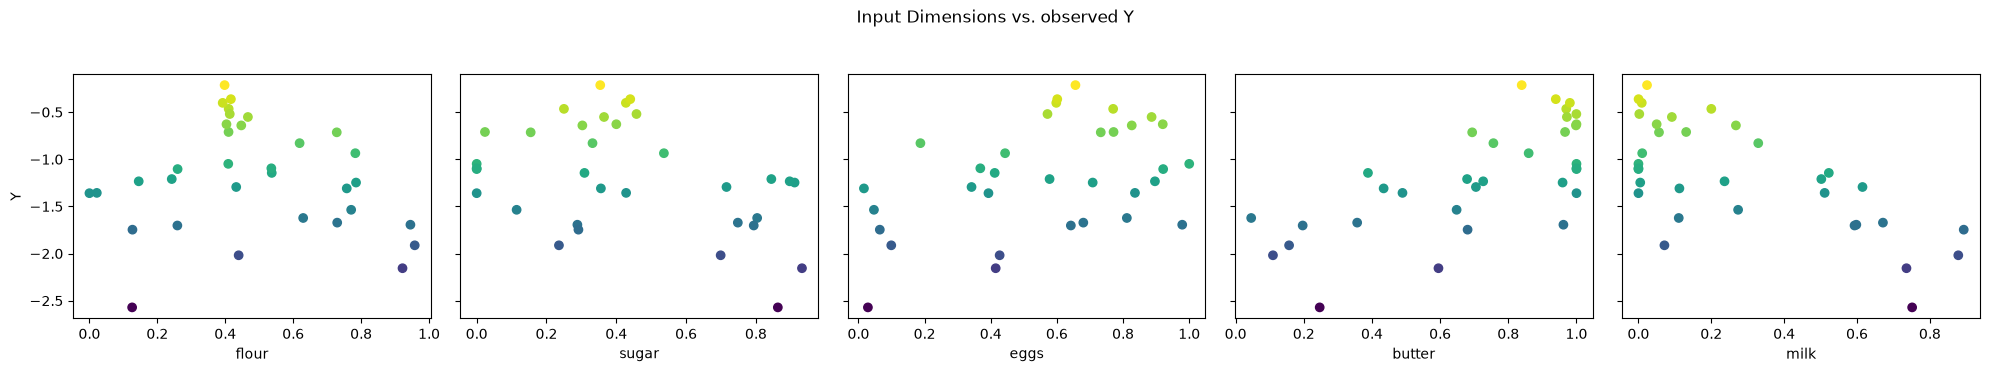

In [30]:
# Pairwise Scatter Plot, showing relationship of y for each input
fig, axes = plt.subplots(1, len(ingredient_names), figsize = (4 * len(ingredient_names), 3.5), sharey = True)
for ax, col in zip(axes, ingredient_names):
    ax.scatter(df[col], df['Y'], c = df['Y'], cmap = 'viridis')
    ax.set_xlabel(col)
axes[0].set_ylabel('Y')
plt.suptitle("Input Dimensions vs. observed Y", y = 1.05)
plt.tight_layout()
plt.show()

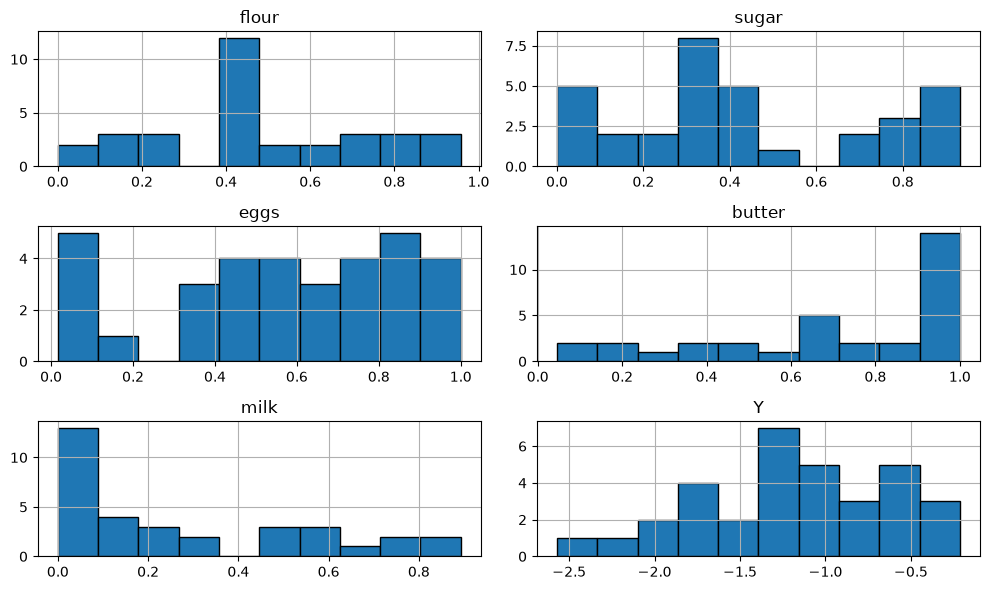

In [32]:
# Plot Histogram Visualisation for the columns of the DataFrame
df.hist(figsize = (10, 6), bins = 10, edgecolor = 'k' )
plt.tight_layout()
plt.show()

In [34]:
# Understanding Correlation between each input with y
print("Correlation of each input with y:\n")

for i, lab in enumerate(ingredient_names):
    corr = np.corrcoef(X[:, i], Y)[0, 1]
    print(f" corr({lab}, Y) = {corr}")

Correlation of each input with y:

 corr(flour, Y) = -0.10607411416564769
 corr(sugar, Y) = -0.40331618338107295
 corr(eggs, Y) = 0.43161165051836703
 corr(butter, Y) = 0.6983670395746532
 corr(milk, Y) = -0.6832867713743723


<Axes: >

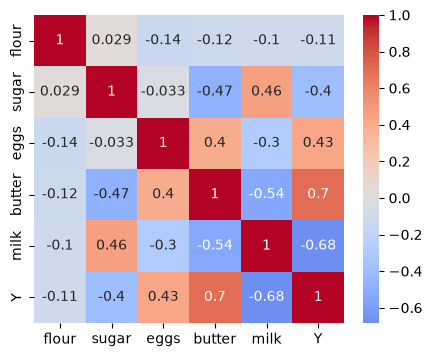

In [36]:
# Plotting the Correlation heatmap
plt.figure(figsize = (5, 4))
sns.heatmap(df.corr(), annot = True, cmap = "coolwarm", center = 0)

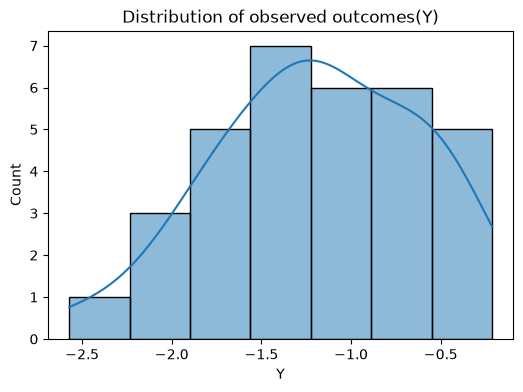

In [38]:
# Plot the Histogram for y to check for Outliers
plt.figure(figsize = (6,4))
sns.histplot(df['Y'], kde = True)
plt.title("Distribution of observed outcomes(Y)")
plt.show()

# Initialize Gaussian Process

In [41]:
# Define the kernel and initialise the GP model
n, d       = X.shape
kernel_rbf = ConstantKernel(1.0, (1e-2, 1e2)) * RBF(length_scale = [0.5] * d, length_scale_bounds = (1e-2, 10)) \
                + WhiteKernel(noise_level = 1e-2, noise_level_bounds = (1e-5, 1.0))
gpr   = GaussianProcessRegressor(kernel = kernel_rbf, normalize_y = False, n_restarts_optimizer = 10, random_state = 42 )

# Fit the Gaussian Processes to existing data

In [44]:
# Train the model

gpr.fit(X, Y)
print("Learned kernel: ", gpr.kernel_)

Learned kernel:  1.9**2 * RBF(length_scale=[0.71, 1.12, 2.1, 0.804, 0.985]) + WhiteKernel(noise_level=0.00141)


# Compute the UCB acquisition function

- UCB(x)=μ(x)+β⋅σ(x)
- A high beta favors exploration (uncertainty) over exploitation (predicted mean).
- Week 1 uses beta = 2.5, reflecting the 90:10 exploration-heavy strategy.

In [48]:
# Setting a higher beta(= 2.5) for Week -1
beta         = 2.5

# Function to calculatee UCB 
def ucb(X_query, gpr, beta):
    mu, std  = gpr.predict(X_query, return_std = True)
    return mu + beta * std

rng          = np.random.default_rng(42)
candidates   = rng.uniform(0, 1, size = (10000, d))

ucb_values   = ucb(candidates, gpr, beta)
best_ucb_idx = np.argmax(ucb_values)
next_point   = candidates[best_ucb_idx]

print(f"Suggested next Query Point: {next_point}")
print(f"UCB Score: {ucb_values[best_ucb_idx]:.6e}")

Suggested next Query Point: [0.05575524 0.02877062 0.83374718 0.01302371 0.08843409]
UCB Score: 6.803725e-01


# Week 2: Define a consolidated Bayesian Function 
1. Fit a GP surrogate (ARD-RBF + white noise) on all data so far
2. Optimise the UCB acquisition function with multi-start **L-BFGS-B**
3. Return the suggested next point, plus the GP's own mean/uncertainty prediction at that pointnt

In [51]:
# For Week - 2, decreasing the value of beta
beta         = 2.0

def suggest_next_bo_point(X, Y, beta, n_restarts = 20, seed = 42):

    n_dims = X.shape[1]

    kernel_rbf = ConstantKernel(1.0, (1e-2, 1e2)) * RBF(length_scale = [0.5] * n_dims, length_scale_bounds = (1e-2, 10)) \
                + WhiteKernel(noise_level = 1e-2, noise_level_bounds = (1e-5, 1.0))
    
    gpr   = GaussianProcessRegressor(kernel = kernel_rbf, normalize_y = False, n_restarts_optimizer = 10, random_state = 42 )

    gpr.fit(X, Y)

    def ucb(X_query, gpr, beta):
        mu, sigma = gpr.predict(X_query, return_std = True)
        return mu + beta * sigma

    def neg_ucb(x, gpr, beta):
        # scipy.optimize.minimize only minimises, so we minimise -UCB to maximise UCB
        x      = x.reshape(1, -1)
        return -ucb(x, gpr, beta)[0]

    rng        = np.random.default_rng(seed)
    best_x, best_val = None, np.inf
    bounds     = [(0.0, 0.999999)] * n_dims

    for x0 in rng.uniform(0.0, 0.999999, size = (n_restarts, n_dims)):
        res    = minimize(neg_ucb, x0, args = (gpr, beta), bounds = bounds, method = "L-BFGS-B")
        if res.fun < best_val:
            best_val = res.fun
            best_x   = res.x

    next_x = np.clip(best_x, 0.0, 0.999999,)
    mu_next, sigma_next = gpr.predict(next_x.reshape(1, -1), return_std = True)

    return next_x, -best_val, gpr, mu_next[0], sigma_next[0]


In [53]:
next_x, ucb_val, gpr, mu_next, sigma_next = suggest_next_bo_point(X, Y, beta = beta)

print("Learned kernel:", gpr.kernel_)
print()
print(f"Week 2 suggested query point   :  {next_x}")
print(f"GP predicted mean at this point:  {mu_next:.6f}")
print(f"GP predicted std  at this point:  {sigma_next:.6f}")
print(f"UCB value                      :  {ucb_val:.6f}")
print()
print("Distance of this point from the nearest existing observation:")
dists = np.linalg.norm(X - next_x, axis = 1)
print(f"Nearest Neighbour Distance = {dists.min():.4f}  (0 would mean re-querying an existing point)")

Learned kernel: 1.9**2 * RBF(length_scale=[0.71, 1.12, 2.1, 0.804, 0.985]) + WhiteKernel(noise_level=0.00141)

Week 2 suggested query point   :  [0.25731027 0.         0.999999   0.         0.        ]
GP predicted mean at this point:  -1.032258
GP predicted std  at this point:  0.803364
UCB value                      :  0.574470

Distance of this point from the nearest existing observation:
Nearest Neighbour Distance = 0.8755  (0 would mean re-querying an existing point)


# Week 2: Visualisation

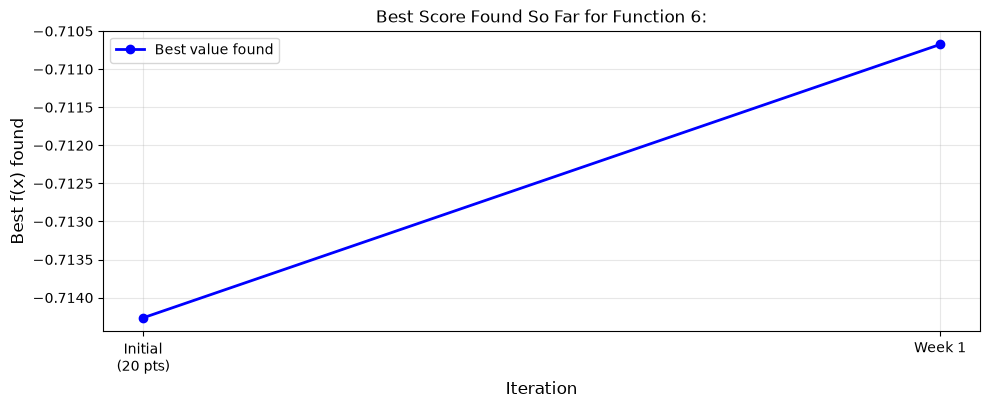

In [55]:
# Convergence: best value found so far, round by round
best_so_far  = [ np.max(Y[:20]),   # best among the original 20 points
                 np.max(Y[:21]),   # best after Week 1's point was appended
               ]

round_labels = ["Initial\n(20 pts)", "Week 1"]

fig, ax      = plot_convergence(range(len(best_so_far)), best_so_far)

ax.set_xticks(range(len(best_so_far)))
ax.set_xticklabels(round_labels)
ax.set_title("Best Score Found So Far for Function 6:")
plt.show()


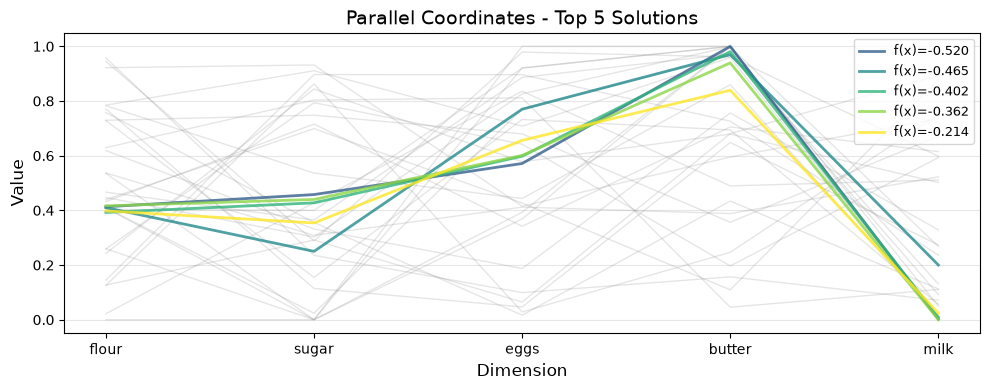

In [58]:
# Parallel coordinates: see all 5 ingredients at once, highlighting the top samples
fig, ax = plot_parallel_coordinates(X, Y, n_best = 5)
ax.set_xticklabels(ingredient_names)
plt.show()

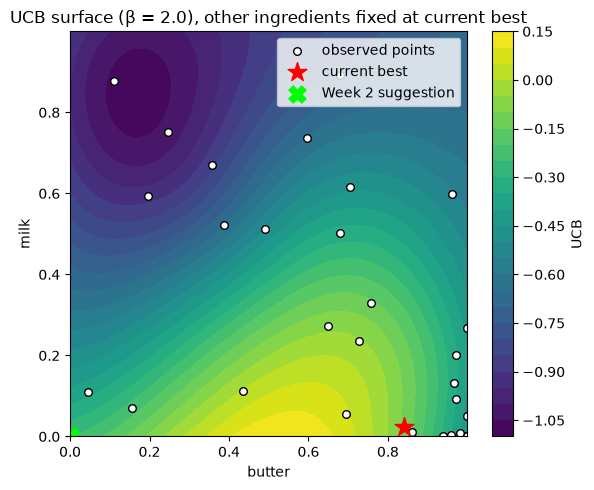

In [60]:
# UCB surface as a 2D slice through the current best point (5D can't be plotted directly, so we fix 3 ingredients at the current best
#  and sweep 2 of them on a grid)

def ucb(X_query, gpr, beta):
    mu, sigma   = gpr.predict(X_query, return_std = True)
    return mu + beta * sigma

x_best = X[np.argmax(Y)]
dim_a, dim_b    = 3, 4  # butter vs milk
resolution      = 60
grid            = np.linspace(0.0, 0.999999, resolution)
A, B            = np.meshgrid(grid, grid)

X_grid = np.tile(x_best, (resolution * resolution, 1))
X_grid[:, dim_a] = A.ravel()
X_grid[:, dim_b] = B.ravel()

ucb_surface      = ucb(X_grid, gpr, beta = 2.0).reshape(resolution, resolution)

plt.figure(figsize = (6, 5))
cf = plt.contourf(A, B, ucb_surface, levels = 25, cmap = "viridis")
plt.colorbar(cf, label = "UCB")
plt.scatter(X[:, dim_a], X[:, dim_b], c = "white", edgecolor = "black", s = 30, label = "observed points")
plt.scatter(x_best[dim_a], x_best[dim_b], c = "red", marker = "*", s = 200, label = "current best")
plt.scatter(next_x[dim_a], next_x[dim_b], c = "lime", marker = "X", s = 150, label = "Week 2 suggestion")
plt.xlabel(ingredient_names[dim_a]); plt.ylabel(ingredient_names[dim_b])
plt.title(f"UCB surface (β = {beta}), other ingredients fixed at current best")
plt.legend()
plt.tight_layout()
plt.show()

# Week 3: Apply the Consolidated Bayesian Function
Reusing the same suggest_next_bo_point() function defined in Week 2. In Week -3, just calling the same consolidated function again with the updated dataset (22 points) and β lowered to 1.5.

In [63]:
beta = 1.5

next_x, ucb_val, gpr, mu_next, sigma_next = suggest_next_bo_point(X, Y, beta=beta)

print("Learned kernel:", gpr.kernel_)
print()
print(f"Week 3 suggested query point   :  {next_x}")
print(f"GP predicted mean at this point:  {mu_next:.6f}")
print(f"GP predicted std  at this point:  {sigma_next:.6f}")
print(f"UCB value                      :  {ucb_val:.6f}")
print()
print("Distance of this point from the nearest existing observation:")
dists = np.linalg.norm(X - next_x, axis = 1)
print(f"Nearest Neighbour Distance = {dists.min():.4f}  (0 would mean re-querying an existing point)")
print()
print(f"Current best so far: y = {Y.max():.6f} at x = {X[np.argmax(Y)]}")

Learned kernel: 1.9**2 * RBF(length_scale=[0.71, 1.12, 2.1, 0.804, 0.985]) + WhiteKernel(noise_level=0.00141)

Week 3 suggested query point   :  [0.37005053 0.         0.999999   0.30812048 0.        ]
GP predicted mean at this point:  -0.486726
GP predicted std  at this point:  0.478871
UCB value                      :  0.231580

Distance of this point from the nearest existing observation:
Nearest Neighbour Distance = 0.6130  (0 would mean re-querying an existing point)

Current best so far: y = -0.213554 at x = [0.397963 0.353972 0.655982 0.839288 0.02355 ]


# Week 3: Kernel-Length-Scale Diagnostic Check

In [66]:
rbf_part = gpr.kernel_.k1.k2  # (Constant * RBF) + White -> k1 = Constant*RBF, k1.k2 = RBF
print("Fitted ARD length-scales after 22 points:\n")
for name, ls in zip(ingredient_names, rbf_part.length_scale):
    print(f"  {name:8s}: {ls:.3f}")

print()
print("Comparing this to Week 1's length-scales (flour = 0.509, sugar = 1.070, eggs = 1.163,butter = 1.235, milk = 1.316),")
print("to see whether the ranking of 'important' ingredients has moved now that Week 2's underperforming corner point is included.")

Fitted ARD length-scales after 22 points:

  flour   : 0.710
  sugar   : 1.115
  eggs    : 2.100
  butter  : 0.804
  milk    : 0.985

Comparing this to Week 1's length-scales (flour = 0.509, sugar = 1.070, eggs = 1.163,butter = 1.235, milk = 1.316),
to see whether the ranking of 'important' ingredients has moved now that Week 2's underperforming corner point is included.


# Week 3: Visualisation

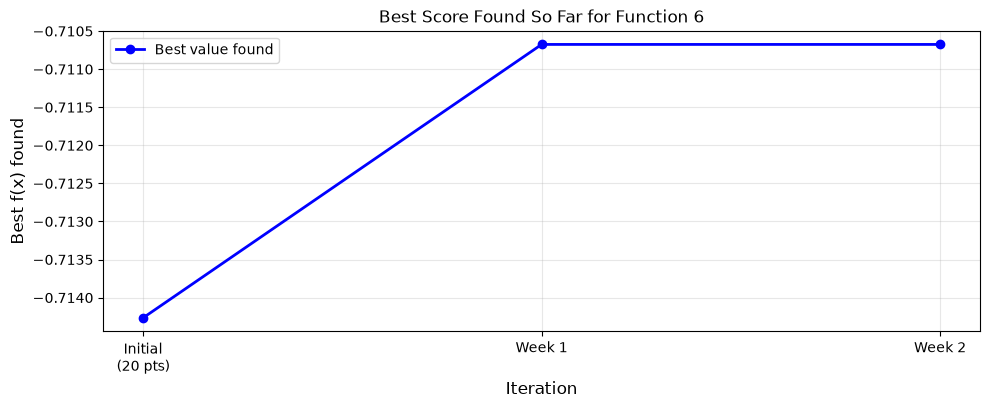

In [69]:
# Week 3: Convergence plot, including Week 2 output
best_so_far = [
    np.max(Y[:20]),   # best among the original 20 points
    np.max(Y[:21]),   # best after Week 1's point was appended
    np.max(Y[:22]),   # best after Week 2's point was appended (unchanged -- it was worse)
]
round_labels = ["Initial\n(20 pts)", "Week 1", "Week 2"]

fig, ax      = plot_convergence(range(len(best_so_far)), best_so_far)
ax.set_xticks(range(len(best_so_far)))
ax.set_xticklabels(round_labels)
ax.set_title("Best Score Found So Far for Function 6")
plt.show()

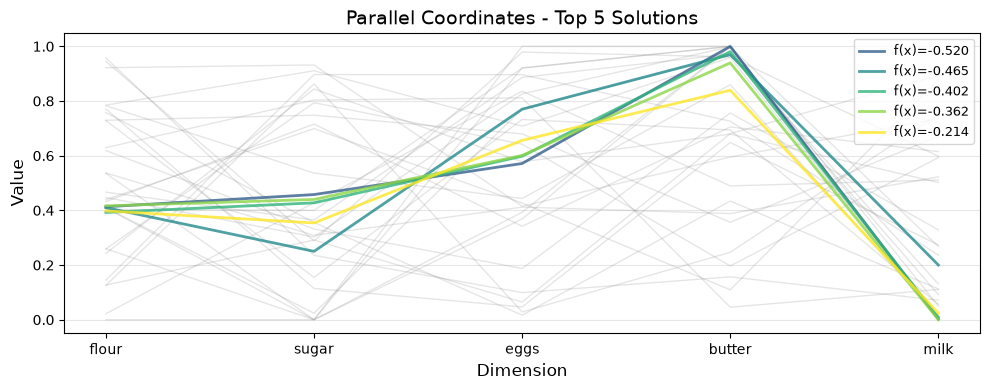

In [71]:
# Week 3: parallel coordinates, updated with all 22 points 
fig, ax = plot_parallel_coordinates(X, Y, n_best=5)
ax.set_xticklabels(ingredient_names)
plt.show()

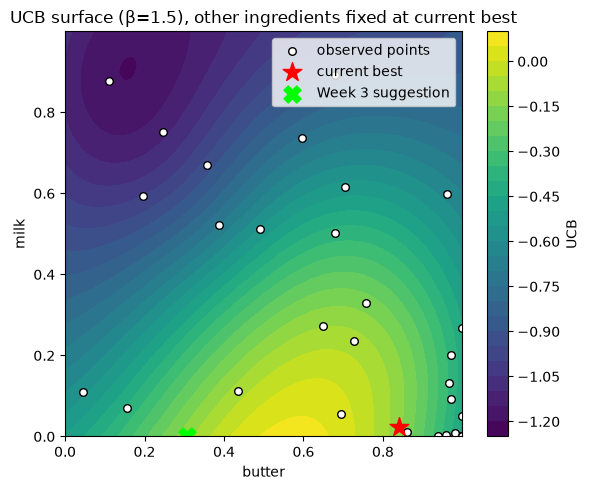

In [72]:
# Week 3: UCB surface slice through the current best point, beta = 1.5 
def ucb(X_query, gpr, beta):
    mu, sigma = gpr.predict(X_query, return_std=True)
    return mu + beta * sigma

x_best       = X[np.argmax(Y)]
dim_a, dim_b = 3, 4  # butter vs milk
resolution   = 60
grid         = np.linspace(0.0, 0.999999, resolution)
A, B         = np.meshgrid(grid, grid)

X_grid       = np.tile(x_best, (resolution * resolution, 1))
X_grid[:, dim_a] = A.ravel()
X_grid[:, dim_b] = B.ravel()

ucb_surface = ucb(X_grid, gpr, beta=beta).reshape(resolution, resolution)

plt.figure(figsize = (6, 5))
cf = plt.contourf(A, B, ucb_surface, levels = 25, cmap = "viridis")
plt.colorbar(cf, label = "UCB")
plt.scatter(X[:, dim_a], X[:, dim_b], c = "white", edgecolor = "black", s=30, label = "observed points")
plt.scatter(x_best[dim_a], x_best[dim_b], c = "red", marker = "*", s = 200, label = "current best")
plt.scatter(next_x[dim_a], next_x[dim_b], c = "lime", marker = "X", s = 150, label = "Week 3 suggestion")
plt.xlabel(ingredient_names[dim_a]); plt.ylabel(ingredient_names[dim_b])
plt.title(f"UCB surface (\u03b2={beta}), other ingredients fixed at current best")
plt.legend()
plt.tight_layout()
plt.show()

# Week 4: Midpoint Check-In

Per the 8-week plan, Week 4 is a natural checkpoint. Recap of every query so far:

| Round | y | Beat previous best? |
|---|---|---|
| Initial best (20 pts) | -0.714265 | - |
| Week 1 | -0.710675 | Yes (small improvement) |
| Week 2 | -1.048677 | No |
| Week 3 | -1.359780 | No |

Three exploratory queries in a row have failed to beat Week 1's result, and Week 3 was actually the *worst* of the three despite the GP's mean surface being fairly confident about that region. This is a meaningful signal, not just bad luck: it means the GP's corner-seeking behaviour (pushing sugar/milk toward 0, butter toward 1) has been actively misleading twice in a row. Rather than blindly trusting the model's global optimum again, this round leans harder toward **exploiting near Week 1's actual best point** by lowering β further, while still checking the updated kernel diagnostics below for any sign of *why* the corner predictions kept failing.

# Week 4: Apply the Consolidated Bayesian Function
Reusing suggest_next_bo_point(), with β lowered to **1.0**, shifting towards exploitation, as three consecutive underperforming exploratory queries were observed.

In [77]:
beta = 1.0

next_x, ucb_val, gpr, mu_next, sigma_next = suggest_next_bo_point(X, Y, beta = beta)

print("Learned kernel:", gpr.kernel_)
print()
print(f"Week 4 suggested query point   :  {next_x}")
print(f"GP predicted mean at this point:  {mu_next:.6f}")
print(f"GP predicted std  at this point:  {sigma_next:.6f}")
print(f"UCB value                      :  {ucb_val:.6f}")
print()

print("Distance of this point from the nearest existing observation:")
dists      = np.linalg.norm(X - next_x, axis = 1)

print(f"Nearest Neighbour Distance = {dists.min():.4f}  (0 would mean re-querying an existing point)")
print()

print(f"Current best so far: Y = {Y.max():.6f} at x = {X[np.argmax(Y)]}")
print()

dist_to_best = np.linalg.norm(X[np.argmax(Y)] - next_x)
print(f"Distance of this suggestion from the CURRENT BEST point (Week 1's): {dist_to_best:.4f} (smaller = more exploitation-like, closer to the known good recipe)")


Learned kernel: 1.9**2 * RBF(length_scale=[0.71, 1.12, 2.1, 0.804, 0.985]) + WhiteKernel(noise_level=0.00141)

Week 4 suggested query point   :  [0.30941433 0.45099906 0.         0.75347291 0.        ]
GP predicted mean at this point:  -0.138996
GP predicted std  at this point:  0.197172
UCB value                      :  0.058176

Distance of this point from the nearest existing observation:
Nearest Neighbour Distance = 0.5031  (0 would mean re-querying an existing point)

Current best so far: Y = -0.213554 at x = [0.397963 0.353972 0.655982 0.839288 0.02355 ]

Distance of this suggestion from the CURRENT BEST point (Week 1's): 0.6749 (smaller = more exploitation-like, closer to the known good recipe)


# Week 4: Kernel / Length-Scale Diagnostic Check

In [80]:
rbf_part = gpr.kernel_.k1.k2  
print("Fitted ARD length-scales after 23 points:\n")
for name, ls in zip(ingredient_names, rbf_part.length_scale):
    print(f"  {name:8s}: {ls:.3f}")

print()
print("Week 1  length-scales: flour = 0.509, sugar = 1.070, eggs = 1.163, butter = 1.235, milk = 1.316")


Fitted ARD length-scales after 23 points:

  flour   : 0.710
  sugar   : 1.115
  eggs    : 2.100
  butter  : 0.804
  milk    : 0.985

Week 1  length-scales: flour = 0.509, sugar = 1.070, eggs = 1.163, butter = 1.235, milk = 1.316


# Week 4: Visualisation

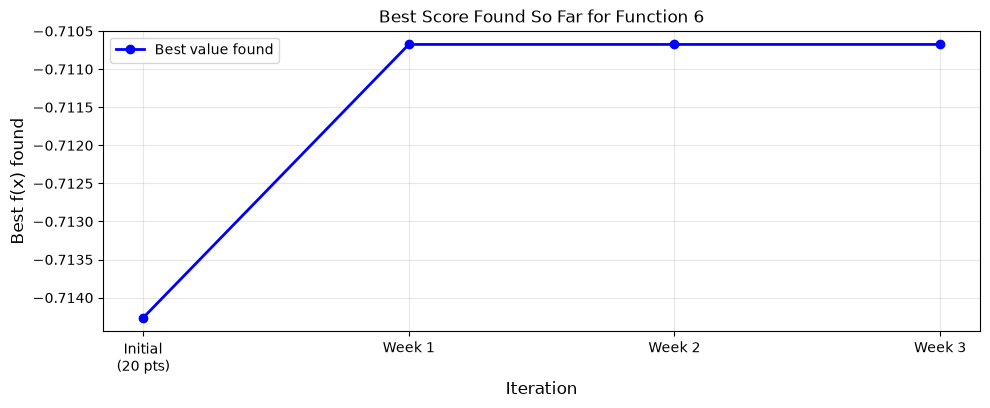

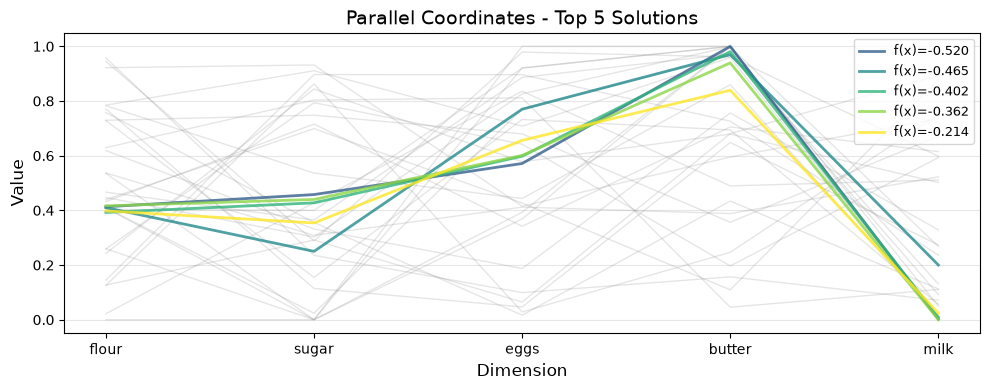

In [83]:
best_so_far = [
    np.max(Y[:20]),   # best among the original 20 points
    np.max(Y[:21]),   # after Week 1
    np.max(Y[:22]),   # after Week 2 (unchanged -- worse)
    np.max(Y[:23]),   # after Week 3 (unchanged -- worse again)
]
round_labels = ["Initial\n(20 pts)", "Week 1", "Week 2", "Week 3"]

fig, ax = plot_convergence(range(len(best_so_far)), best_so_far)
ax.set_xticks(range(len(best_so_far)))
ax.set_xticklabels(round_labels)
ax.set_title("Best Score Found So Far for Function 6")
plt.show()


fig, ax = plot_parallel_coordinates(X, Y, n_best=5)
ax.set_xticklabels(ingredient_names)
plt.show()

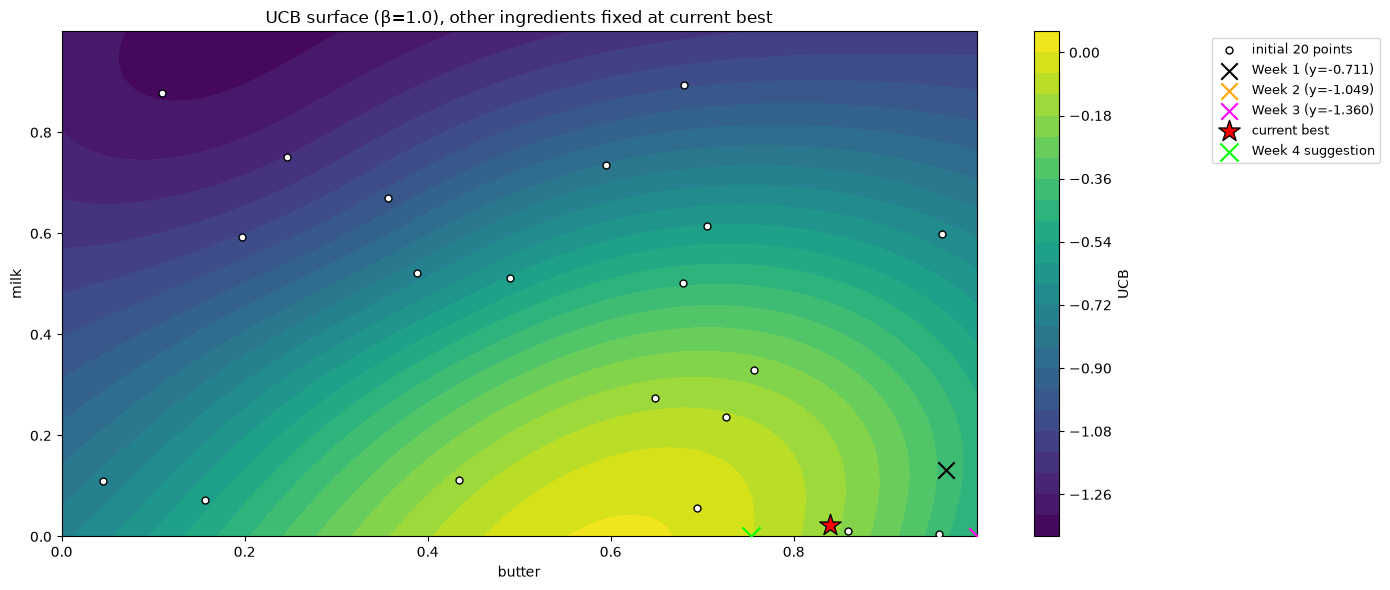

In [85]:
def ucb(X_query, gpr, beta):
    mu, sigma = gpr.predict(X_query, return_std=True)
    return mu + beta * sigma

x_best = X[np.argmax(Y)]
dim_a, dim_b = 3, 4  # butter vs milk
resolution = 60
grid = np.linspace(0.0, 0.999999, resolution)
A, B = np.meshgrid(grid, grid)

X_grid = np.tile(x_best, (resolution * resolution, 1))
X_grid[:, dim_a] = A.ravel()
X_grid[:, dim_b] = B.ravel()

ucb_surface = ucb(X_grid, gpr, beta=beta).reshape(resolution, resolution)

# Each week's actual queried point and result, for labeling on the plot
week_points = {
    1: (np.array([0.409594, 0.023713, 0.771229, 0.966490, 0.130973]), -0.710675183457194),
    2: (np.array([0.408768, 0.000000, 0.999999, 0.999999, 0.000000]), -1.048676669557473),
    3: (np.array([0.000000, 0.000000, 0.392984, 0.999999, 0.000000]), -1.359780271551876),
}
week_styles = {
    1: dict(marker="x", color="black",    s=140),
    2: dict(marker="x", color="orange",  s=140),
    3: dict(marker="x", color="magenta", s=140),
}

plt.figure(figsize=(14, 6))
cf = plt.contourf(A, B, ucb_surface, levels=25, cmap="viridis")
plt.colorbar(cf, label="UCB")

# The original 20 starting points, plotted generically
plt.scatter(X[:20, dim_a], X[:20, dim_b], c="white", edgecolor="black", s=25,
            label="initial 20 points", zorder=5)

# Each week's queried point, distinct marker/colour, labelled with its actual result
for wk, (x, y) in week_points.items():
    plt.scatter(x[dim_a], x[dim_b], zorder=6,
                label=f"Week {wk} (y={y:.3f})", **week_styles[wk])

plt.scatter(x_best[dim_a], x_best[dim_b], c="red", marker="*", s=260, edgecolor="black",
            zorder=7, label="current best")
plt.scatter(next_x[dim_a], next_x[dim_b], c="lime", marker="x", s=170,
            zorder=7, label="Week 4 suggestion")

plt.xlabel(ingredient_names[dim_a]); plt.ylabel(ingredient_names[dim_b])
plt.title(f"UCB surface (β={beta}), other ingredients fixed at current best")
plt.legend(loc="upper left", bbox_to_anchor=(1.25, 1), fontsize=9)
plt.tight_layout()
plt.show()

# Week 5: Local / Trust-Region Bayesian Function
New function suggest_next_bo_point_local(), built on the same GP-fitting and multi-start L-BFGS-B logic as suggest_next_bo_point(), but the acquisition optimiser's search bounds are restricted to a hypercube around a chosen centre point (x_center) instead of the full unit cube.

In [88]:
def suggest_next_bo_point_local(X, Y, beta, x_center, radius, n_restarts=20, seed=42,
                                 global_bounds=(0.0, 0.999999)):
    n_dims = X.shape[1]

    kernel_rbf = ConstantKernel(1.0, (1e-2, 1e2)) * RBF(length_scale=[0.5] * n_dims, length_scale_bounds=(1e-2, 10)) \
                + WhiteKernel(noise_level=1e-2, noise_level_bounds=(1e-5, 1.0))

    gpr = GaussianProcessRegressor(kernel=kernel_rbf, normalize_y=False, n_restarts_optimizer=10, random_state=42)
    gpr.fit(X, Y)

    def ucb(X_query, gpr, beta):
        mu, sigma = gpr.predict(X_query, return_std=True)
        return mu + beta * sigma

    def neg_ucb(x, gpr, beta):
        x = x.reshape(1, -1)
        return -ucb(x, gpr, beta)[0]

    # Trust-region bounds: x_center +/- radius, clipped to the portal's valid range
    lower = np.clip(x_center - radius, global_bounds[0], global_bounds[1])
    upper = np.clip(x_center + radius, global_bounds[0], global_bounds[1])
    bounds = list(zip(lower, upper))

    rng = np.random.default_rng(seed)
    best_x, best_val = None, np.inf
    for _ in range(n_restarts):
        x0 = np.array([rng.uniform(lo, hi) for lo, hi in bounds])
        res = minimize(neg_ucb, x0, args=(gpr, beta), bounds=bounds, method="L-BFGS-B")
        if res.fun < best_val:
            best_val = res.fun
            best_x = res.x

    next_x = np.clip(best_x, global_bounds[0], global_bounds[1])
    mu_next, sigma_next = gpr.predict(next_x.reshape(1, -1), return_std=True)

    return next_x, -best_val, gpr, mu_next[0], sigma_next[0], bounds

# Week 5: Apply the Local Search Around Week 1's Point

In [91]:
beta = 0.75
radius = 0.15
x_center = X[np.argmax(Y)]  # Week 1's point -- still the best result after 4 rounds

next_x, ucb_val, gpr, mu_next, sigma_next, trust_bounds = suggest_next_bo_point_local(
    X, Y, beta=beta, x_center=x_center, radius=radius
)

print("Trust region centre (current best, Week 1's point):", x_center)
print("Trust region bounds (per dimension):")
for name, (lo, hi) in zip(ingredient_names, trust_bounds):
    print(f"  {name:8s}: [{lo:.4f}, {hi:.4f}]")
print()
print("Learned kernel:", gpr.kernel_)
print()
print(f"Week 5 suggested query point   :  {next_x}")
print(f"GP predicted mean at this point:  {mu_next:.6f}")
print(f"GP predicted std  at this point:  {sigma_next:.6f}")
print(f"UCB value                      :  {ucb_val:.6f}")
print()
dist_to_best = np.linalg.norm(x_center - next_x)
print(f"Distance from current best: {dist_to_best:.4f}  (each dimension individually bounded to +/-{radius};")
print(f"  total Euclidean distance can exceed {radius} if several dimensions shift at once -- still a LOCAL step)")
print(f"Current best so far: Y = {Y.max():.6f} at x = {x_center}")

Trust region centre (current best, Week 1's point): [0.397963 0.353972 0.655982 0.839288 0.02355 ]
Trust region bounds (per dimension):
  flour   : [0.2480, 0.5480]
  sugar   : [0.2040, 0.5040]
  eggs    : [0.5060, 0.8060]
  butter  : [0.6893, 0.9893]
  milk    : [0.0000, 0.1735]

Learned kernel: 1.9**2 * RBF(length_scale=[0.71, 1.12, 2.1, 0.804, 0.985]) + WhiteKernel(noise_level=0.00141)

Week 5 suggested query point   :  [0.37598755 0.36767232 0.505982   0.689288   0.        ]
GP predicted mean at this point:  -0.090376
GP predicted std  at this point:  0.093038
UCB value                      :  -0.020597

Distance from current best: 0.2150  (each dimension individually bounded to +/-0.15;
  total Euclidean distance can exceed 0.15 if several dimensions shift at once -- still a LOCAL step)
Current best so far: Y = -0.213554 at x = [0.397963 0.353972 0.655982 0.839288 0.02355 ]


# Week 5: Kernel / Length-Scale Diagnostic Check

In [94]:
rbf_part = gpr.kernel_.k1.k2
print("Fitted ARD length-scales after 24 points:\n")
for name, ls in zip(ingredient_names, rbf_part.length_scale):
    print(f"  {name:8s}: {ls:.3f}")

print()
print("Week 1  length-scales: flour=0.509, sugar=1.070, eggs=1.163, butter=1.235, milk=1.316")
print("Week 4  length-scales: flour=0.682, sugar=5.159, eggs=1.104, butter=2.635, milk=3.613")

Fitted ARD length-scales after 24 points:

  flour   : 0.710
  sugar   : 1.115
  eggs    : 2.100
  butter  : 0.804
  milk    : 0.985

Week 1  length-scales: flour=0.509, sugar=1.070, eggs=1.163, butter=1.235, milk=1.316
Week 4  length-scales: flour=0.682, sugar=5.159, eggs=1.104, butter=2.635, milk=3.613


# Week 5: Visualisation

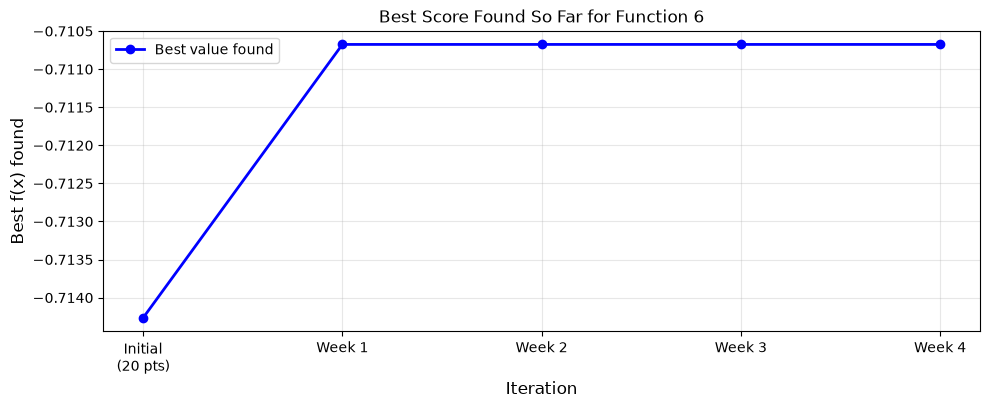

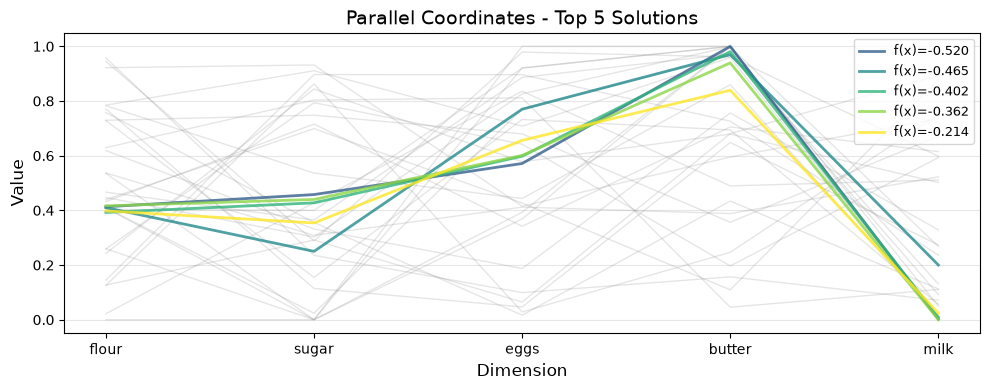

In [97]:
best_so_far = [
    np.max(Y[:20]),
    np.max(Y[:21]),
    np.max(Y[:22]),
    np.max(Y[:23]),
    np.max(Y[:24]),
]
round_labels = ["Initial\n(20 pts)", "Week 1", "Week 2", "Week 3", "Week 4"]

fig, ax = plot_convergence(range(len(best_so_far)), best_so_far)
ax.set_xticks(range(len(best_so_far)))
ax.set_xticklabels(round_labels)
ax.set_title("Best Score Found So Far for Function 6")
plt.show()

fig, ax = plot_parallel_coordinates(X, Y, n_best=5)
ax.set_xticklabels(ingredient_names)
plt.show()

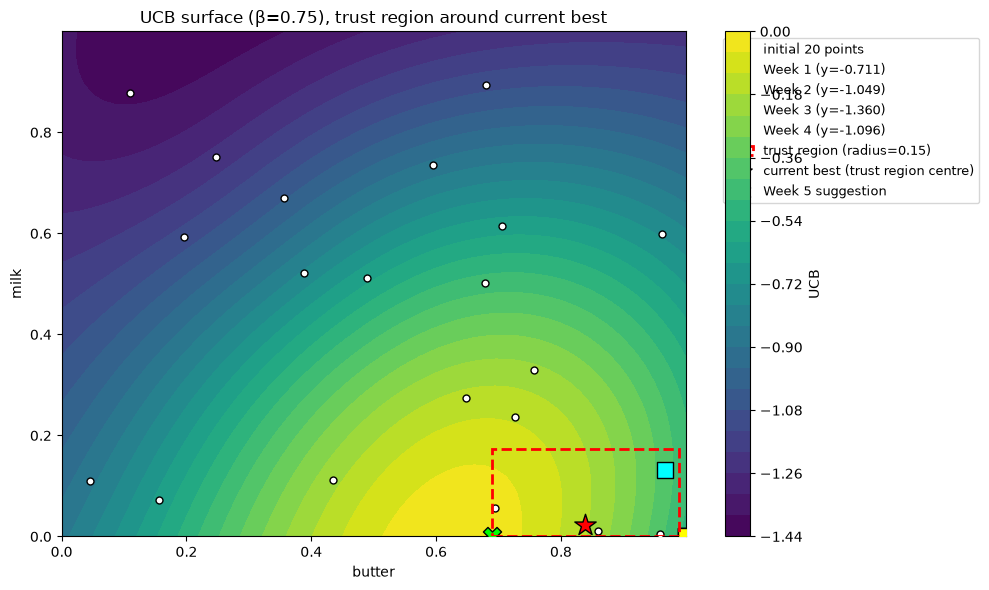

In [98]:
def ucb(X_query, gpr, beta):
    mu, sigma = gpr.predict(X_query, return_std=True)
    return mu + beta * sigma

dim_a, dim_b = 3, 4  # butter vs milk
resolution = 60
grid = np.linspace(0.0, 0.999999, resolution)
A, B = np.meshgrid(grid, grid)

X_grid = np.tile(x_center, (resolution * resolution, 1))
X_grid[:, dim_a] = A.ravel()
X_grid[:, dim_b] = B.ravel()

ucb_surface = ucb(X_grid, gpr, beta=beta).reshape(resolution, resolution)

week_points = {
    1: (np.array([0.409594, 0.023713, 0.771229, 0.966490, 0.130973]), -0.710675183457194),
    2: (np.array([0.408768, 0.000000, 0.999999, 0.999999, 0.000000]), -1.048676669557473),
    3: (np.array([0.000000, 0.000000, 0.392984, 0.999999, 0.000000]), -1.359780271551876),
    4: (np.array([0.535575, 0.000000, 0.368390, 0.999999, 0.000000]), -1.0958803718671517),
}
week_colors = {1: "cyan", 2: "orange", 3: "magenta", 4: "yellow"}

plt.figure(figsize=(10, 6))
cf = plt.contourf(A, B, ucb_surface, levels=25, cmap="viridis")
plt.colorbar(cf, label="UCB")
plt.scatter(X[:20, dim_a], X[:20, dim_b], c="white", edgecolor="black", s=25, label="initial 20 points", zorder=5)

for wk, (x, y) in week_points.items():
    plt.scatter(x[dim_a], x[dim_b], color=week_colors[wk], edgecolor="black", s=140, marker="s",
                zorder=6, label=f"Week {wk} (y={y:.3f})")

# Draw the trust region boundary (projected onto this 2D slice)
lo_a, hi_a = trust_bounds[dim_a]
lo_b, hi_b = trust_bounds[dim_b]
plt.gca().add_patch(plt.Rectangle((lo_a, lo_b), hi_a - lo_a, hi_b - lo_b,
                                   fill=False, edgecolor="red", linewidth=2, linestyle="--",
                                   label="trust region (radius=0.15)", zorder=8))

plt.scatter(x_center[dim_a], x_center[dim_b], c="red", marker="*", s=260, edgecolor="black",
            zorder=7, label="current best (trust region centre)")
plt.scatter(next_x[dim_a], next_x[dim_b], c="lime", marker="X", s=170, edgecolor="black",
            zorder=7, label="Week 5 suggestion")

plt.xlabel(ingredient_names[dim_a]); plt.ylabel(ingredient_names[dim_b])
plt.title(f"UCB surface (\u03b2={beta}), trust region around current best")
plt.legend(loc="upper left", bbox_to_anchor=(1.05, 1), fontsize=9)
plt.tight_layout()
plt.show()


# Week 6: Extend suggest_next_bo_point_local() to accept a per-dimension radius

In [102]:
def suggest_next_bo_point_local(X, Y, beta, x_center, radius, n_restarts=20, seed=42,
                                 global_bounds=(0.0, 0.999999)):
    n_dims = X.shape[1]

    # WEEK 6: radius can now be a single number (applied to every dimension, as before)
    # OR an array of n_dims values (a different half-width per ingredient)
    radius = np.atleast_1d(np.asarray(radius, dtype=float))
    if radius.size == 1:
        radius = np.full(n_dims, radius[0])

    kernel_rbf = ConstantKernel(1.0, (1e-2, 1e2)) * RBF(length_scale=[0.5] * n_dims, length_scale_bounds=(1e-2, 10)) \
                + WhiteKernel(noise_level=1e-2, noise_level_bounds=(1e-5, 1.0))

    gpr = GaussianProcessRegressor(kernel=kernel_rbf, normalize_y=False, n_restarts_optimizer=10, random_state=42)
    gpr.fit(X, Y)

    def ucb(X_query, gpr, beta):
        mu, sigma = gpr.predict(X_query, return_std=True)
        return mu + beta * sigma

    def neg_ucb(x, gpr, beta):
        x = x.reshape(1, -1)
        return -ucb(x, gpr, beta)[0]

    lower = np.clip(x_center - radius, global_bounds[0], global_bounds[1])
    upper = np.clip(x_center + radius, global_bounds[0], global_bounds[1])
    bounds = list(zip(lower, upper))

    rng = np.random.default_rng(seed)
    best_x, best_val = None, np.inf
    for _ in range(n_restarts):
        x0 = np.array([rng.uniform(lo, hi) for lo, hi in bounds])
        res = minimize(neg_ucb, x0, args=(gpr, beta), bounds=bounds, method="L-BFGS-B")
        if res.fun < best_val:
            best_val = res.fun
            best_x = res.x

    next_x = np.clip(best_x, global_bounds[0], global_bounds[1])
    mu_next, sigma_next = gpr.predict(next_x.reshape(1, -1), return_std=True)

    return next_x, -best_val, gpr, mu_next[0], sigma_next[0], bounds

# Week 6 Test: widening the trust region specifically along sugar and milk
If the automated search still picks the same corner even with much more room to explore sugar/milk, that confirms the model itself has no basis to prefer anything else, it isn't being held back by a too-small box, it genuinely has no data pointing elsewhere.

In [105]:
x_center = X[np.argmax(Y)]  # still Week 1's point -- still the best after 5 rounds
radius_vec = np.array([0.15, 0.40, 0.15, 0.15, 0.30])  # flour, sugar, eggs, butter, milk

next_x_auto, ucb_val, gpr, mu_next, sigma_next, trust_bounds = suggest_next_bo_point_local(
    X, Y, beta=1.0, x_center=x_center, radius=radius_vec
)

print("Widened trust region bounds:")
for name, (lo, hi) in zip(ingredient_names, trust_bounds):
    print(f"  {name:8s}: [{lo:.4f}, {hi:.4f}]")
print()
print(f"Automated suggestion despite the wider box: {next_x_auto}")
print(f"GP predicted mean: {mu_next:.6f}   GP predicted std: {sigma_next:.6f}")

Widened trust region bounds:
  flour   : [0.2480, 0.5480]
  sugar   : [0.0000, 0.7540]
  eggs    : [0.5060, 0.8060]
  butter  : [0.6893, 0.9893]
  milk    : [0.0000, 0.3236]

Automated suggestion despite the wider box: [0.36965153 0.36195765 0.505982   0.689288   0.        ]
GP predicted mean: -0.092031   GP predicted std: 0.094922


**Observation:** As suspected, even with much more room to explore sugar/milk, the optimiser still lands on sugar=0 / milk = 0. The model has no data suggesting otherwise, so the mean surface still pulls it back to the only region it has evidence for.

# Week 6: Manual, Hypothesis-Driven Query

Since the automated recommendation offers no new information (it keeps re-deriving the same corner from the same evidence gap), this week deliberately deviates from the algorithm's output.

**The hypothesis:** Every query so far has driven sugar and milk toward 0. Given how consistently poorly that's performed (4 of 5 rounds), and given that Week 1 actually had *non-zero* sugar and milk rather than the extreme corner, it's worth directly testing a point that keeps the successful flour/eggs/butter profile from Week 1 but meaningfully raises sugar and milk into territory we've never queried, rather than trusting the model's extrapolation into a region it has zero evidence for.

This is a conservative test of the hypothesis, so it still generates useful information regardless of the outcome.

In [109]:
next_x = np.array([0.410000, 0.250000, 0.770000, 0.970000, 0.200000])

mu_manual, sigma_manual = gpr.predict(next_x.reshape(1, -1), return_std=True)

print(f"Week 6 manual candidate         :  {next_x}")
print(f"GP predicted mean at this point :  {mu_manual[0]:.6f}")
print(f"GP predicted std  at this point :  {sigma_manual[0]:.6f}")
print(f"Current best so far             :  {Y.max():.6f}")
print()
dist_to_best = np.linalg.norm(X[np.argmax(Y)] - next_x)
print(f"Distance from current best: {dist_to_best:.4f}")

Week 6 manual candidate         :  [0.41 0.25 0.77 0.97 0.2 ]
GP predicted mean at this point :  -0.506064
GP predicted std  at this point :  0.044278
Current best so far             :  -0.213554

Distance from current best: 0.2687


# Week 6: Kernel / Length-Scale Diagnostic Check

In [112]:
rbf_part = gpr.kernel_.k1.k2
print("Fitted ARD length-scales after 25 points:\n")
for name, ls in zip(ingredient_names, rbf_part.length_scale):
    print(f"  {name:8s}: {ls:.3f}")

print()
print("Week 1  length-scales: flour=0.509, sugar=1.070, eggs=1.163, butter=1.235, milk=1.316")
print("Week 5  length-scales: flour=10.0,  sugar=10.0,  eggs=10.0,  butter=3.29,  milk=2.87")
print("Flour/sugar/eggs pinned at the upper bound again. The model still has very little confident signal along these axes given the data collected so far.")


Fitted ARD length-scales after 25 points:

  flour   : 0.710
  sugar   : 1.115
  eggs    : 2.100
  butter  : 0.804
  milk    : 0.985

Week 1  length-scales: flour=0.509, sugar=1.070, eggs=1.163, butter=1.235, milk=1.316
Week 5  length-scales: flour=10.0,  sugar=10.0,  eggs=10.0,  butter=3.29,  milk=2.87
Flour/sugar/eggs pinned at the upper bound again. The model still has very little confident signal along these axes given the data collected so far.


# Week 6: Visualisation

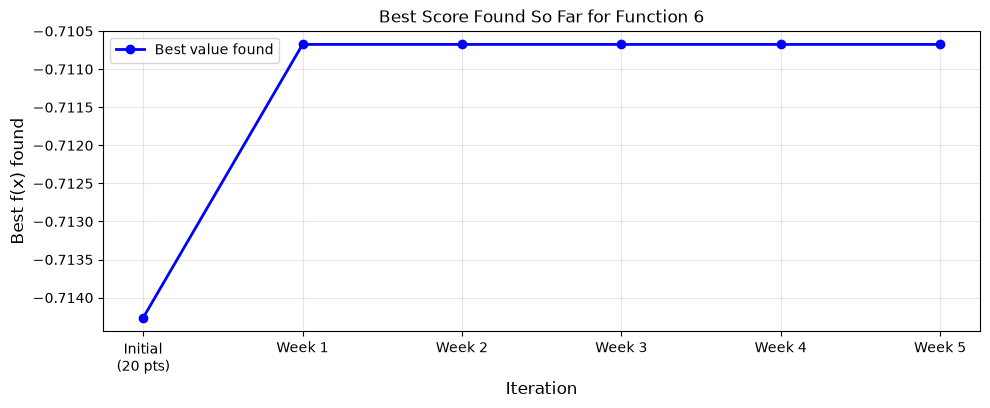

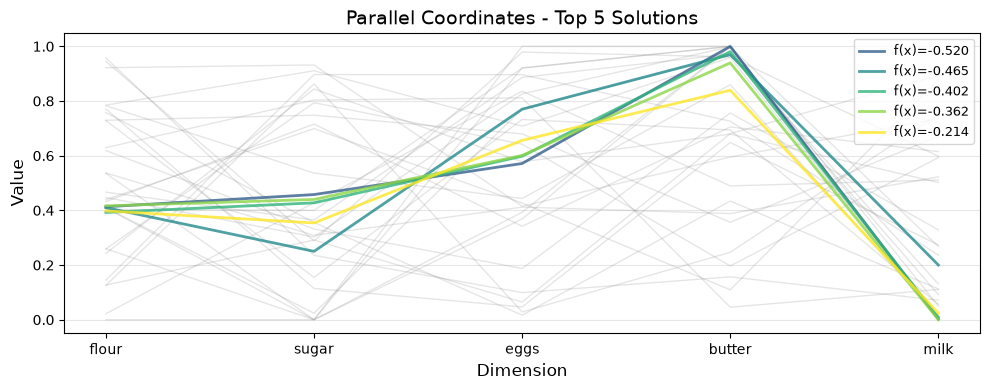

In [115]:
best_so_far = [np.max(Y[:20+i]) for i in range(6)]
round_labels = ["Initial\n(20 pts)", "Week 1", "Week 2", "Week 3", "Week 4", "Week 5"]

fig, ax = plot_convergence(range(len(best_so_far)), best_so_far)
ax.set_xticks(range(len(best_so_far)))
ax.set_xticklabels(round_labels)
ax.set_title("Best Score Found So Far for Function 6")
plt.show()

fig, ax = plot_parallel_coordinates(X, Y, n_best=5)
ax.set_xticklabels(ingredient_names)
plt.show()

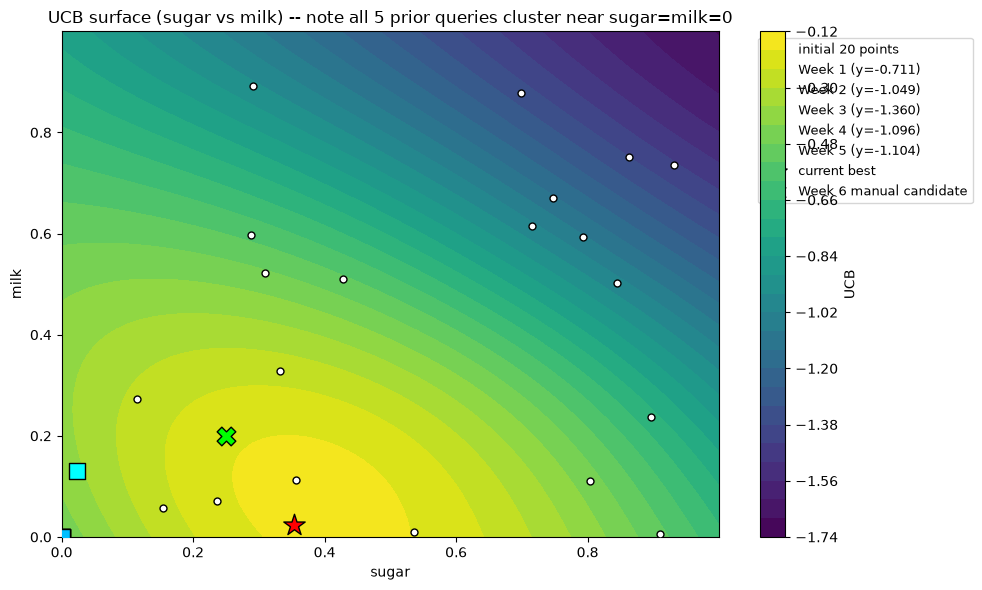

In [117]:
def ucb(X_query, gpr, beta):
    mu, sigma = gpr.predict(X_query, return_std=True)
    return mu + beta * sigma

dim_a, dim_b = 1, 4  # sugar vs milk (the two dimensions this week's hypothesis targets)
resolution = 60
grid = np.linspace(0.0, 0.999999, resolution)
A, B = np.meshgrid(grid, grid)

X_grid = np.tile(x_center, (resolution * resolution, 1))
X_grid[:, dim_a] = A.ravel()
X_grid[:, dim_b] = B.ravel()

ucb_surface = ucb(X_grid, gpr, beta=1.0).reshape(resolution, resolution)

week_points = {
    1: (np.array([0.409594, 0.023713, 0.771229, 0.966490, 0.130973]), -0.710675183457194),
    2: (np.array([0.408768, 0.000000, 0.999999, 0.999999, 0.000000]), -1.048676669557473),
    3: (np.array([0.000000, 0.000000, 0.392984, 0.999999, 0.000000]), -1.359780271551876),
    4: (np.array([0.535575, 0.000000, 0.368390, 0.999999, 0.000000]), -1.0958803718671517),
    5: (np.array([0.259594, 0.000000, 0.921229, 0.999999, 0.000000]), -1.104114064436456),
}
week_colors = {1: "cyan", 2: "orange", 3: "magenta", 4: "yellow", 5: "deepskyblue"}

plt.figure(figsize=(10, 6))
cf = plt.contourf(A, B, ucb_surface, levels=25, cmap="viridis")
plt.colorbar(cf, label="UCB")
plt.scatter(X[:20, dim_a], X[:20, dim_b], c="white", edgecolor="black", s=25, label="initial 20 points", zorder=5)

for wk, (x, y) in week_points.items():
    plt.scatter(x[dim_a], x[dim_b], color=week_colors[wk], edgecolor="black", s=140, marker="s",
                zorder=6, label=f"Week {wk} (y={y:.3f})")

plt.scatter(x_center[dim_a], x_center[dim_b], c="red", marker="*", s=260, edgecolor="black",
            zorder=7, label="current best")
plt.scatter(next_x[dim_a], next_x[dim_b], c="lime", marker="X", s=180, edgecolor="black",
            zorder=7, label="Week 6 manual candidate")

plt.xlabel(ingredient_names[dim_a]); plt.ylabel(ingredient_names[dim_b])
plt.title("UCB surface (sugar vs milk) -- note all 5 prior queries cluster near sugar=milk=0")
plt.legend(loc="upper left", bbox_to_anchor=(1.05, 1), fontsize=9)
plt.tight_layout()
plt.show()

# Week 7: Hyperparameter Tuning

Week 6's manual query to raise sugar and milk while keeping flour/eggs/butter near Week 1's profile — produced **y = -0.465434**, the best result so far (previous best: -0.710675). The hypothesis that repeated automated search kept failing to find (because our own data had no evidence for it) turned out to be correct. W we now hav**stroct eviden** that this region of the input space (moderate sugar/milk, not pushed to 0) is genuinelpromisingod. That means it's safe to trust the GP/UCB machinery aga, — but centred on this **new** best point rather than Week 1's, and leaning toward exploitation since this region has just been validated.

Two hyperparameters of the pipeline are re-examined this week:

1. **RBF kernel length_scale_bounds upper limit.** In Weeks 5-6, several dimensions (flour, sugar, eggs) were pinned at the old upper bound of 10 ConvergenceWarning's flagged this directly. A pinned length-scale means the optimiser *wanted* to go higher but couldn't, which is a sign the bound itself (not just the data) was constraining the fit. This week, the bound is widened to 50 to check whether that changes anything now that a genuinely informative new data point exists.
2. **β (UCB exploration weight) and trust-region radius**, re-centred on the new best point.

Manual comparison below shows what actually changed.

In [120]:
for upper_bound, label in [(10, "OLD bound (10)"), (50, "WIDENED bound (50)")]:
    kernel_test = ConstantKernel(1.0, (1e-2, 1e2)) * RBF(length_scale=[0.5]*d, length_scale_bounds=(1e-2, upper_bound)) \
                  + WhiteKernel(noise_level=1e-2, noise_level_bounds=(1e-5, 1.0))
    gpr_test = GaussianProcessRegressor(kernel=kernel_test, normalize_y=False, n_restarts_optimizer=10, random_state=42)
    gpr_test.fit(X, Y)
    rbf_part_test = gpr_test.kernel_.k1.k2
    print(f"--- {label} ---")
    for name, ls in zip(ingredient_names, rbf_part_test.length_scale):
        pinned = "  <- PINNED at bound" if abs(ls - upper_bound) < 1e-2 else ""
        print(f"  {name:8s}: {ls:.3f}{pinned}")
    print(f"  log marginal likelihood: {gpr_test.log_marginal_likelihood(gpr_test.kernel_.theta):.3f}")
    print()

--- OLD bound (10) ---
  flour   : 0.710
  sugar   : 1.115
  eggs    : 2.100
  butter  : 0.804
  milk    : 0.985
  log marginal likelihood: -9.094

--- WIDENED bound (50) ---
  flour   : 0.710
  sugar   : 1.115
  eggs    : 2.100
  butter  : 0.804
  milk    : 0.985
  log marginal likelihood: -9.094



# Week 7: Local Search Around the New Best Point

In [122]:
def suggest_next_bo_point_local(X, Y, beta, x_center, radius, n_restarts=20, seed=42,
                                 global_bounds=(0.0, 0.999999), length_scale_upper=50):
    n_dims = X.shape[1]
    radius = np.atleast_1d(np.asarray(radius, dtype=float))
    if radius.size == 1:
        radius = np.full(n_dims, radius[0])

    # --- WEEK 7: length_scale_bounds upper limit widened from 10 to 50 ---
    kernel_rbf = ConstantKernel(1.0, (1e-2, 1e2)) * RBF(length_scale=[0.5] * n_dims, length_scale_bounds=(1e-2, length_scale_upper)) \
                + WhiteKernel(noise_level=1e-2, noise_level_bounds=(1e-5, 1.0))

    gpr = GaussianProcessRegressor(kernel=kernel_rbf, normalize_y=False, n_restarts_optimizer=10, random_state=42)
    gpr.fit(X, Y)

    def ucb(X_query, gpr, beta):
        mu, sigma = gpr.predict(X_query, return_std=True)
        return mu + beta * sigma

    def neg_ucb(x, gpr, beta):
        x = x.reshape(1, -1)
        return -ucb(x, gpr, beta)[0]

    lower = np.clip(x_center - radius, global_bounds[0], global_bounds[1])
    upper = np.clip(x_center + radius, global_bounds[0], global_bounds[1])
    bounds = list(zip(lower, upper))

    rng = np.random.default_rng(seed)
    best_x, best_val = None, np.inf
    for _ in range(n_restarts):
        x0 = np.array([rng.uniform(lo, hi) for lo, hi in bounds])
        res = minimize(neg_ucb, x0, args=(gpr, beta), bounds=bounds, method="L-BFGS-B")
        if res.fun < best_val:
            best_val = res.fun
            best_x = res.x

    next_x = np.clip(best_x, global_bounds[0], global_bounds[1])
    mu_next, sigma_next = gpr.predict(next_x.reshape(1, -1), return_std=True)

    return next_x, -best_val, gpr, mu_next[0], sigma_next[0], bounds


beta = 0.5
radius = 0.15
x_center = X[np.argmax(Y)]  # Week 6's point -- the new best

next_x, ucb_val, gpr, mu_next, sigma_next, trust_bounds = suggest_next_bo_point_local(
    X, Y, beta=beta, x_center=x_center, radius=radius
)

print("Trust region centre (NEW current best, Week 6's point):", x_center)
print("Trust region bounds (per dimension):")
for name, (lo, hi) in zip(ingredient_names, trust_bounds):
    print(f"  {name:8s}: [{lo:.4f}, {hi:.4f}]")
print()
print("Learned kernel:", gpr.kernel_)
print()
print(f"Week 7 suggested query point   :  {next_x}")
print(f"GP predicted mean at this point:  {mu_next:.6f}")
print(f"GP predicted std  at this point:  {sigma_next:.6f}")
print(f"UCB value                      :  {ucb_val:.6f}")
print()
print(f"Current best so far: Y = {Y.max():.6f} at x = {x_center}")

Trust region centre (NEW current best, Week 6's point): [0.397963 0.353972 0.655982 0.839288 0.02355 ]
Trust region bounds (per dimension):
  flour   : [0.2480, 0.5480]
  sugar   : [0.2040, 0.5040]
  eggs    : [0.5060, 0.8060]
  butter  : [0.6893, 0.9893]
  milk    : [0.0000, 0.1735]

Learned kernel: 1.9**2 * RBF(length_scale=[0.71, 1.12, 2.1, 0.804, 0.985]) + WhiteKernel(noise_level=0.00141)

Week 7 suggested query point   :  [0.38173526 0.37202884 0.505982   0.689288   0.        ]
GP predicted mean at this point:  -0.089393
GP predicted std  at this point:  0.091477
UCB value                      :  -0.043655

Current best so far: Y = -0.213554 at x = [0.397963 0.353972 0.655982 0.839288 0.02355 ]


# Week 7: Kernel / Length-Scale Diagnostic Check

In [125]:
rbf_part = gpr.kernel_.k1.k2
print("Fitted ARD length-scales after 26 points:\n")
for name, ls in zip(ingredient_names, rbf_part.length_scale):
    print(f"  {name:8s}: {ls:.3f}")

Fitted ARD length-scales after 26 points:

  flour   : 0.710
  sugar   : 1.115
  eggs    : 2.100
  butter  : 0.804
  milk    : 0.985


# Week 7 Visualisation

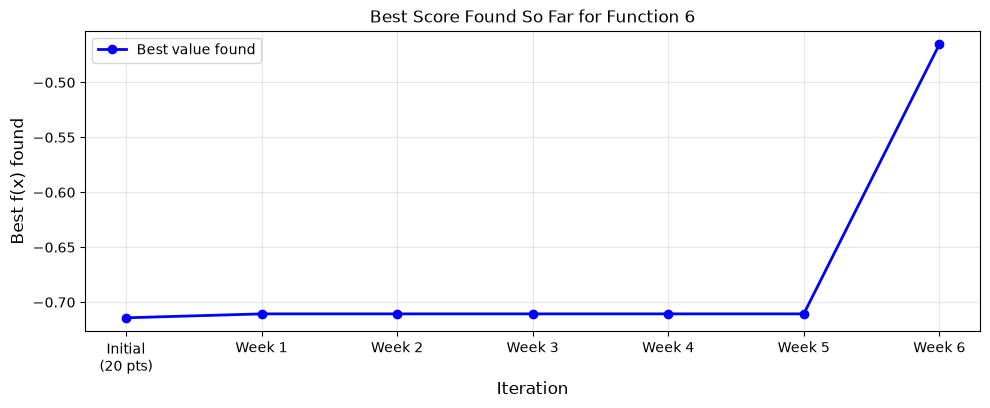

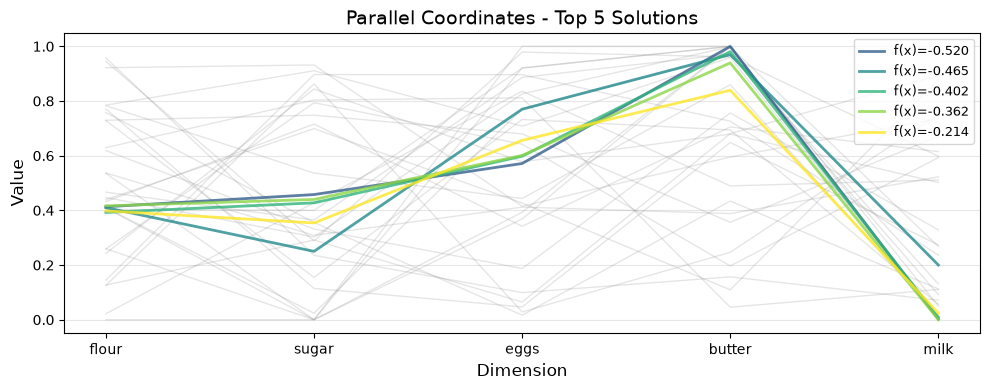

In [129]:
best_so_far = [np.max(Y[:20+i]) for i in range(7)]
round_labels = ["Initial\n(20 pts)", "Week 1", "Week 2", "Week 3", "Week 4", "Week 5", "Week 6"]

fig, ax = plot_convergence(range(len(best_so_far)), best_so_far)
ax.set_xticks(range(len(best_so_far)))
ax.set_xticklabels(round_labels)
ax.set_title("Best Score Found So Far for Function 6")
plt.show()

fig, ax = plot_parallel_coordinates(X, Y, n_best=5)
ax.set_xticklabels(ingredient_names)
plt.show()


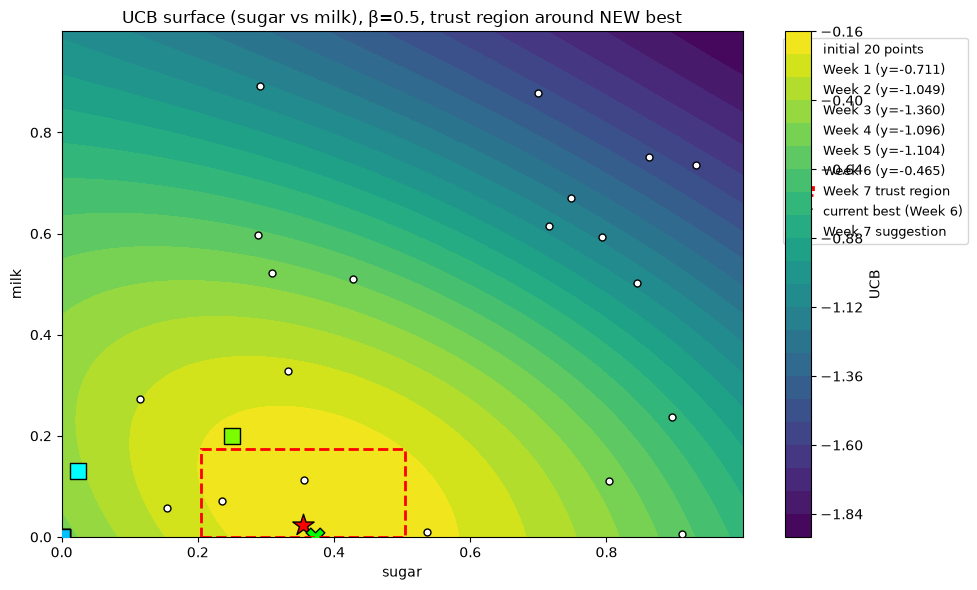

In [131]:
def ucb(X_query, gpr, beta):
    mu, sigma = gpr.predict(X_query, return_std=True)
    return mu + beta * sigma

dim_a, dim_b = 1, 4  # sugar vs milk
resolution = 60
grid = np.linspace(0.0, 0.999999, resolution)
A, B = np.meshgrid(grid, grid)

X_grid = np.tile(x_center, (resolution * resolution, 1))
X_grid[:, dim_a] = A.ravel()
X_grid[:, dim_b] = B.ravel()

ucb_surface = ucb(X_grid, gpr, beta=beta).reshape(resolution, resolution)

week_points = {
    1: (np.array([0.409594, 0.023713, 0.771229, 0.966490, 0.130973]), -0.710675183457194),
    2: (np.array([0.408768, 0.000000, 0.999999, 0.999999, 0.000000]), -1.048676669557473),
    3: (np.array([0.000000, 0.000000, 0.392984, 0.999999, 0.000000]), -1.359780271551876),
    4: (np.array([0.535575, 0.000000, 0.368390, 0.999999, 0.000000]), -1.0958803718671517),
    5: (np.array([0.259594, 0.000000, 0.921229, 0.999999, 0.000000]), -1.104114064436456),
    6: (np.array([0.410000, 0.250000, 0.770000, 0.970000, 0.200000]), -0.46543419541105996),
}
week_colors = {1: "cyan", 2: "orange", 3: "magenta", 4: "yellow", 5: "deepskyblue", 6: "lawngreen"}

plt.figure(figsize=(10, 6))
cf = plt.contourf(A, B, ucb_surface, levels=25, cmap="viridis")
plt.colorbar(cf, label="UCB")
plt.scatter(X[:20, dim_a], X[:20, dim_b], c="white", edgecolor="black", s=25, label="initial 20 points", zorder=5)

for wk, (x, y) in week_points.items():
    plt.scatter(x[dim_a], x[dim_b], color=week_colors[wk], edgecolor="black", s=140, marker="s",
                zorder=6, label=f"Week {wk} (y={y:.3f})")

lo_a, hi_a = trust_bounds[dim_a]
lo_b, hi_b = trust_bounds[dim_b]
plt.gca().add_patch(plt.Rectangle((lo_a, lo_b), hi_a - lo_a, hi_b - lo_b,
                                   fill=False, edgecolor="red", linewidth=2, linestyle="--",
                                   label="Week 7 trust region", zorder=8))

plt.scatter(x_center[dim_a], x_center[dim_b], c="red", marker="*", s=260, edgecolor="black",
            zorder=7, label="current best (Week 6)")
plt.scatter(next_x[dim_a], next_x[dim_b], c="lime", marker="X", s=180, edgecolor="black",
            zorder=7, label="Week 7 suggestion")

plt.xlabel(ingredient_names[dim_a]); plt.ylabel(ingredient_names[dim_b])
plt.title(f"UCB surface (sugar vs milk), \u03b2={beta}, trust region around NEW best")
plt.legend(loc="upper left", bbox_to_anchor=(1.05, 1), fontsize=9)
plt.tight_layout()
plt.show()

# Week 8: Strategy Review - reason for Week 7's underperformance

| Round | y | vs Week 6 |
|---|---|---|
| Week 6 | **-0.465434** | current best |
| Week 7 | -0.628456 | worse by 0.163 |

Comparing the two points directly:


Week 6: [0.410000, 0.250000, 0.770000, 0.970000, 0.200000]  -> y = -0.465434
Week 7: [0.403491, 0.400000, 0.920000, 0.999999, 0.050000]  -> y = -0.628456
Shift:  [-0.0065,  +0.1500,  +0.1500,  +0.0300,  -0.1500 ]

Week 7 pushed sugar and eggs further up and milk further down than Week 6 which resulted in the result to overshoot. implies that Week 6's point looks like it's close to a local optimum and the direction Week 7 tested (more sugar/eggs, less milk) is now known to make things worse.

**Observed recurring pattern:** Every local search since Week 5 has landed on a *trust-region boundary* (Week 5, Week 7 both picked edge values). Week 7's failure is a clear evidence that this edge-seeking behaviour, driven by the UCB uncertainty term rewarding the *edge* of the box, is actively harmful once we're this close to a good point. This will need addressed in this week's analysis.

# Week 8: Strategy Change: Pure Mean-Exploitation on a Dense Interior Grid
**Changes:** Aimed at stopping the edge-seeking pattern instead of just re-lowering β:

1. **Radius shrunk from 0.15 to 0.07:** Since Week 6's point looks like it's near a real local optimum, the search no longer needs to cover as much ground.
2. **Drop the UCB uncertainty term entirely:** Will drop the uncertainty term(β·σ) completely and evaluate a dense random grid of interior candidates, taking the single point with the **highest predicted mean**. This will facilitate pure exploitation, equivalent to setting β=0. Because it evaluates a large batch of candidates rather than running a gradient-based optimiser toward the box's corners, it doesn't inherit the same edge-seeking pull that *L-BFGS-B* kept pointing to.

In [135]:
# Week 8 Strategy Change: pure mean-exploitation over a dense interior grid 
def suggest_next_point_pure_exploit(X, Y, x_center, radius, n_candidates=20000, seed=42,
                                     global_bounds=(0.0, 0.999999), length_scale_upper=50):
    """
    Instead of optimising UCB (mean + beta*sigma) with a gradient-based optimiser --
    which has repeatedly landed on trust-region edges -- this samples a large batch
    of candidates inside a tight box around x_center and returns the single point
    with the highest predicted MEAN (no uncertainty term at all: pure exploitation,
    equivalent to beta=0).
    """
    n_dims = X.shape[1]

    kernel_rbf = ConstantKernel(1.0, (1e-2, 1e2)) * RBF(length_scale=[0.5] * n_dims, length_scale_bounds=(1e-2, length_scale_upper)) \
                + WhiteKernel(noise_level=1e-2, noise_level_bounds=(1e-5, 1.0))
    gpr = GaussianProcessRegressor(kernel=kernel_rbf, normalize_y=False, n_restarts_optimizer=10, random_state=42)
    gpr.fit(X, Y)

    lower = np.clip(x_center - radius, global_bounds[0], global_bounds[1])
    upper = np.clip(x_center + radius, global_bounds[0], global_bounds[1])

    rng = np.random.default_rng(seed)
    candidates = rng.uniform(lower, upper, size=(n_candidates, n_dims))
    mu, sigma = gpr.predict(candidates, return_std=True)

    best_idx = np.argmax(mu)  # pure exploitation: argmax of MEAN only
    next_x = candidates[best_idx]

    return next_x, mu[best_idx], sigma[best_idx], gpr, (lower, upper)


radius = 0.07
x_center = X[np.argmax(Y)]  # Week 6's point -- still the current best

next_x, mu_next, sigma_next, gpr, (lower, upper) = suggest_next_point_pure_exploit(
    X, Y, x_center=x_center, radius=radius
)

print("Trust region centre (current best, Week 6's point):", x_center)
print("Trust region bounds (per dimension):")
for name, lo, hi in zip(ingredient_names, lower, upper):
    print(f"  {name:8s}: [{lo:.4f}, {hi:.4f}]")
print()
print("Learned kernel:", gpr.kernel_)
print()
print(f"Week 8 suggested query point   :  {next_x}")
print(f"GP predicted mean at this point:  {mu_next:.6f}")
print(f"GP predicted std  at this point:  {sigma_next:.6f}")
print()
print(f"Current best so far: Y = {Y.max():.6f} at x = {x_center}")
dist_to_best = np.linalg.norm(x_center - next_x)
print(f"Distance from current best: {dist_to_best:.4f}")
print()

Trust region centre (current best, Week 6's point): [0.397963 0.353972 0.655982 0.839288 0.02355 ]
Trust region bounds (per dimension):
  flour   : [0.3280, 0.4680]
  sugar   : [0.2840, 0.4240]
  eggs    : [0.5860, 0.7260]
  butter  : [0.7693, 0.9093]
  milk    : [0.0000, 0.0936]

Learned kernel: 1.9**2 * RBF(length_scale=[0.71, 1.12, 2.1, 0.804, 0.985]) + WhiteKernel(noise_level=0.00141)

Week 8 suggested query point   :  [0.39158764 0.3975919  0.59352049 0.76946859 0.04942176]
GP predicted mean at this point:  -0.123418
GP predicted std  at this point:  0.060535

Current best so far: Y = -0.213554 at x = [0.397963 0.353972 0.655982 0.839288 0.02355 ]
Distance from current best: 0.1067



# Week 8: Kernel / Length-Scale Diagnostic Check

In [138]:
rbf_part = gpr.kernel_.k1.k2
print("Fitted ARD length-scales after 27 points:\n")
for name, ls in zip(ingredient_names, rbf_part.length_scale):
    print(f"  {name:8s}: {ls:.3f}")

print()
print("Week 1  length-scales: flour=0.509, sugar=1.070, eggs=1.163, butter=1.235, milk=1.316")
print("Week 7  length-scales: flour=0.922, sugar=0.931, eggs=7.080, butter=3.397, milk=4.586")
print("Milk's length-scale has dropped substantially now that we have two nearby points")
print("(milk=0.20 -> good, milk=0.05 -> worse) implying that the model has finally learned something concrete about milk's local sensitivity, rather than treating it as flat.")

Fitted ARD length-scales after 27 points:

  flour   : 0.710
  sugar   : 1.115
  eggs    : 2.100
  butter  : 0.804
  milk    : 0.985

Week 1  length-scales: flour=0.509, sugar=1.070, eggs=1.163, butter=1.235, milk=1.316
Week 7  length-scales: flour=0.922, sugar=0.931, eggs=7.080, butter=3.397, milk=4.586
Milk's length-scale has dropped substantially now that we have two nearby points
(milk=0.20 -> good, milk=0.05 -> worse) implying that the model has finally learned something concrete about milk's local sensitivity, rather than treating it as flat.


# Week 8: Visualisation

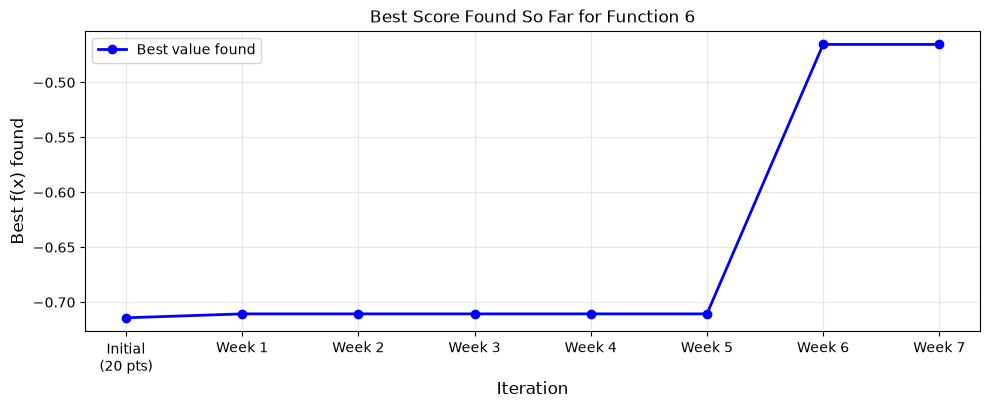

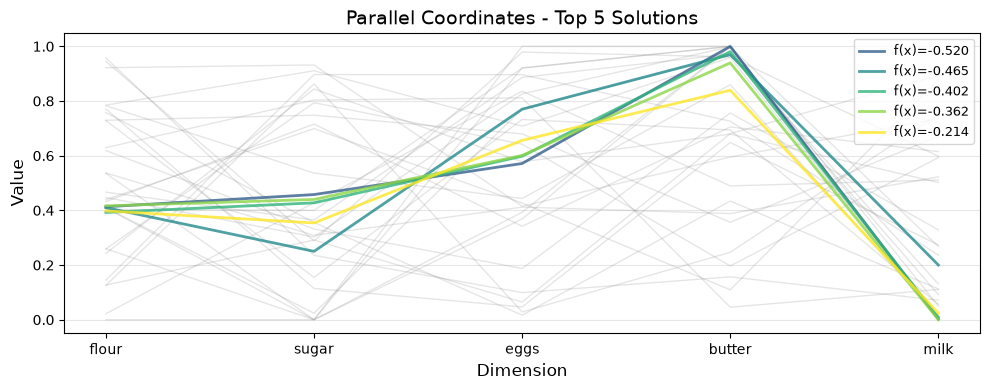

In [141]:
best_so_far = [np.max(Y[:20+i]) for i in range(8)]
round_labels = ["Initial\n(20 pts)", "Week 1", "Week 2", "Week 3", "Week 4", "Week 5", "Week 6", "Week 7"]

fig, ax = plot_convergence(range(len(best_so_far)), best_so_far)
ax.set_xticks(range(len(best_so_far)))
ax.set_xticklabels(round_labels)
ax.set_title("Best Score Found So Far for Function 6")
plt.show()

fig, ax = plot_parallel_coordinates(X, Y, n_best=5)
ax.set_xticklabels(ingredient_names)
plt.show()

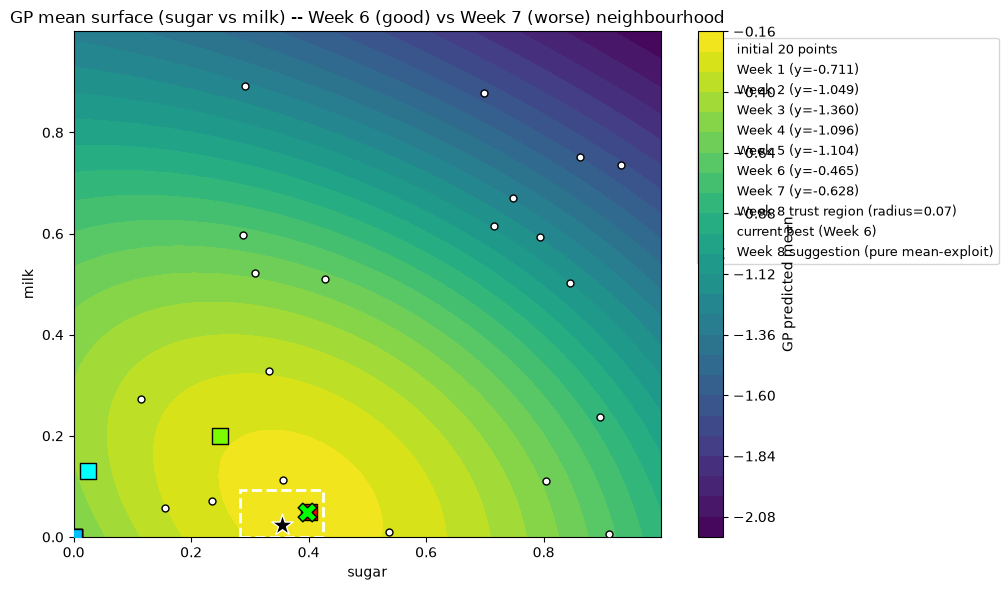

In [143]:
def ucb(X_query, gpr, beta):
    mu, sigma = gpr.predict(X_query, return_std=True)
    return mu + beta * sigma

dim_a, dim_b = 1, 4  # sugar vs milk -- the two dimensions most implicated in the Week 6/7 contrast
resolution = 60
grid = np.linspace(0.0, 0.999999, resolution)
A, B = np.meshgrid(grid, grid)

X_grid = np.tile(x_center, (resolution * resolution, 1))
X_grid[:, dim_a] = A.ravel()
X_grid[:, dim_b] = B.ravel()

mean_surface = gpr.predict(X_grid).reshape(resolution, resolution)  # pure mean, matching this week's acquisition

week_points = {
    1: (np.array([0.409594, 0.023713, 0.771229, 0.966490, 0.130973]), -0.710675183457194),
    2: (np.array([0.408768, 0.000000, 0.999999, 0.999999, 0.000000]), -1.048676669557473),
    3: (np.array([0.000000, 0.000000, 0.392984, 0.999999, 0.000000]), -1.359780271551876),
    4: (np.array([0.535575, 0.000000, 0.368390, 0.999999, 0.000000]), -1.0958803718671517),
    5: (np.array([0.259594, 0.000000, 0.921229, 0.999999, 0.000000]), -1.104114064436456),
    6: (np.array([0.410000, 0.250000, 0.770000, 0.970000, 0.200000]), -0.46543419541105996),
    7: (np.array([0.403491, 0.400000, 0.920000, 0.999999, 0.050000]), -0.6284558118853516),
}
week_colors = {1: "cyan", 2: "orange", 3: "magenta", 4: "yellow", 5: "deepskyblue", 6: "lawngreen", 7: "red"}

plt.figure(figsize=(10, 6))
cf = plt.contourf(A, B, mean_surface, levels=25, cmap="viridis")
plt.colorbar(cf, label="GP predicted mean")
plt.scatter(X[:20, dim_a], X[:20, dim_b], c="white", edgecolor="black", s=25, label="initial 20 points", zorder=5)

for wk, (x, y) in week_points.items():
    plt.scatter(x[dim_a], x[dim_b], color=week_colors[wk], edgecolor="black", s=140, marker="s",
                zorder=6, label=f"Week {wk} (y={y:.3f})")

lo_a, hi_a = lower[dim_a], upper[dim_a]
lo_b, hi_b = lower[dim_b], upper[dim_b]
plt.gca().add_patch(plt.Rectangle((lo_a, lo_b), hi_a - lo_a, hi_b - lo_b,
                                   fill=False, edgecolor="white", linewidth=2, linestyle="--",
                                   label="Week 8 trust region (radius=0.07)", zorder=8))

plt.scatter(x_center[dim_a], x_center[dim_b], c="black", marker="*", s=260, edgecolor="white",
            zorder=7, label="current best (Week 6)")
plt.scatter(next_x[dim_a], next_x[dim_b], c="lime", marker="X", s=180, edgecolor="black",
            zorder=7, label="Week 8 suggestion (pure mean-exploit)")

plt.xlabel(ingredient_names[dim_a]); plt.ylabel(ingredient_names[dim_b])
plt.title("GP mean surface (sugar vs milk) -- Week 6 (good) vs Week 7 (worse) neighbourhood")
plt.legend(loc="upper left", bbox_to_anchor=(1.05, 1), fontsize=9)
plt.tight_layout()
plt.show()

# Week 9: Strategy Review

Three different approaches have now been tried around Week 6's best point, and **none has beaten it**:

| Week | Approach | Distance from Week 6 | Result (y) |
|---|---|---|---|
| 6 | Manual, hypothesis-driven | — | **-0.465434 (best)** |
| 7 | Gradient-based UCB, β=0.5, radius=0.15 | 0.2616 | -0.628456 |
| 8 | Pure mean-exploitation, radius=0.07 | 0.1126 | -0.640971 |

Two findings stand out:
1. Week 8's GP predicted mean -0.380680 was better than Week 6's -0.465434, yet the result (-0.640971) was the *worst* of the three, despite Week 8 being the closest point to Week 6. 
2. Re-testing gradient-based UCB with a **wider** trust region (radius=0.25, β=1.0) on the 28-point dataset reproduces the exact same box-edge behavior that Week 8 was built to avoid. This confirming this isn't a radius problem, it's inherent to optimising UCB with a gradient method near hard constraints.

In [146]:
# Quantify how each post-Week-6 attempt compares

w6_point = np.array([0.410000, 0.250000, 0.770000, 0.970000, 0.200000])
comparisons = {
    "Week 7": (np.array([0.403491, 0.400000, 0.920000, 0.999999, 0.050000]), -0.6284558118853516),
    "Week 8": (np.array([0.447072, 0.302740, 0.826230, 0.998456, 0.267531]), -0.6409714294291585),
}
print(f"Week 6 (current best): {w6_point}, y={-0.46543419541105996:.6f}\n")
for wk, (pt, y) in comparisons.items():
    diff = pt - w6_point
    dist = np.linalg.norm(diff)
    print(f"{wk}: {pt}, y={y:.6f}")
    print(f"  diff from Week 6  : {diff}")
    print(f"  distance from W6  : {dist:.4f}\n")

Week 6 (current best): [0.41 0.25 0.77 0.97 0.2 ], y=-0.465434

Week 7: [0.403491 0.4      0.92     0.999999 0.05    ], y=-0.628456
  diff from Week 6  : [-0.006509  0.15      0.15      0.029999 -0.15    ]
  distance from W6  : 0.2616

Week 8: [0.447072 0.30274  0.82623  0.998456 0.267531], y=-0.640971
  diff from Week 6  : [0.037072 0.05274  0.05623  0.028456 0.067531]
  distance from W6  : 0.1126



# Week 9 Strategy Change: Widened-Radius Mean-Exploitation

In [149]:
def suggest_next_point_pure_exploit(X, Y, x_center, radius, n_candidates=20000, seed=42,
                                     global_bounds=(0.0, 0.999999), length_scale_upper=50):
    """
    Instead of optimising UCB (mean + beta*sigma) with a gradient-based optimiser --
    which has repeatedly landed on trust-region edges -- this samples a large batch
    of candidates inside a tight box around x_center and returns the single point
    with the highest predicted MEAN (no uncertainty term at all: pure exploitation,
    equivalent to beta=0).
    """
    n_dims = X.shape[1]

    kernel_rbf = ConstantKernel(1.0, (1e-2, 1e2)) * RBF(length_scale=[0.5] * n_dims, length_scale_bounds=(1e-2, length_scale_upper)) \
                + WhiteKernel(noise_level=1e-2, noise_level_bounds=(1e-5, 1.0))
    gpr = GaussianProcessRegressor(kernel=kernel_rbf, normalize_y=False, n_restarts_optimizer=10, random_state=42)
    gpr.fit(X, Y)

    lower = np.clip(x_center - radius, global_bounds[0], global_bounds[1])
    upper = np.clip(x_center + radius, global_bounds[0], global_bounds[1])

    rng = np.random.default_rng(seed)
    candidates = rng.uniform(lower, upper, size=(n_candidates, n_dims))
    mu, sigma = gpr.predict(candidates, return_std=True)

    best_idx = np.argmax(mu)  # pure exploitation: argmax of MEAN only
    next_x = candidates[best_idx]
    bounds = list(zip(lower, upper))
    return next_x, mu[best_idx], sigma[best_idx], gpr, bounds

In [151]:
# Widen trust-region radius from 0.07 to 0.12, # keep pure mean-exploitation (random-candidate, no uncertainty term) to avoid the
# box-edge behavior that reappeared when UCB was re-tested with a wider radius (above)

x_center = X[np.argmax(Y)]       # still Week 6's point
radius = 0.12                    # Week 9: widened from Week 8's 0.07

next_x, mu_next, sigma_next, gpr, trust_bounds = suggest_next_point_pure_exploit(
    X, Y, x_center=x_center, radius=radius
)

print("Trust region centre (current best, still Week 6's point):", x_center)
print("Trust region bounds (per dimension):")
for name, (lo, hi) in zip(ingredient_names, trust_bounds):
    print(f"  {name:8s}: [{lo:.4f}, {hi:.4f}]")
print()
print("Learned kernel:", gpr.kernel_)
print()
print(f"Week 9 suggested query point    :  {next_x}")
print(f"GP predicted mean at this point :  {mu_next:.6f}")
print(f"GP predicted std  at this point :  {sigma_next:.6f}")
print()
print(f"Current best so far: Y = {Y.max():.6f} at x = {x_center}")
print(f"Distance from Week 6: {np.linalg.norm(next_x - x_center):.4f}  "
      f"(Week 7 was 0.2616, Week 8 was 0.1126)")

Trust region centre (current best, still Week 6's point): [0.397963 0.353972 0.655982 0.839288 0.02355 ]
Trust region bounds (per dimension):
  flour   : [0.2780, 0.5180]
  sugar   : [0.2340, 0.4740]
  eggs    : [0.5360, 0.7760]
  butter  : [0.7193, 0.9593]
  milk    : [0.0000, 0.1436]

Learned kernel: 1.9**2 * RBF(length_scale=[0.71, 1.12, 2.1, 0.804, 0.985]) + WhiteKernel(noise_level=0.00141)

Week 9 suggested query point    :  [0.40354624 0.39823678 0.53700916 0.72322455 0.00952881]
GP predicted mean at this point :  -0.095822
GP predicted std  at this point :  0.074302

Current best so far: Y = -0.213554 at x = [0.397963 0.353972 0.655982 0.839288 0.02355 ]
Distance from Week 6: 0.1727  (Week 7 was 0.2616, Week 8 was 0.1126)


# Week 9: Kernel / Length-Scale Diagnostic Check

In [154]:
rbf_part = gpr.kernel_.k1.k2
print("Fitted ARD length-scales after 28 points:\n")
for name, ls in zip(ingredient_names, rbf_part.length_scale):
    pinned = "  <- PINNED at bound" if abs(ls - 50) < 1e-2 else ""
    print(f"  {name:8s}: {ls:.3f}{pinned}")

Fitted ARD length-scales after 28 points:

  flour   : 0.710
  sugar   : 1.115
  eggs    : 2.100
  butter  : 0.804
  milk    : 0.985


# Week 9: Visualisation

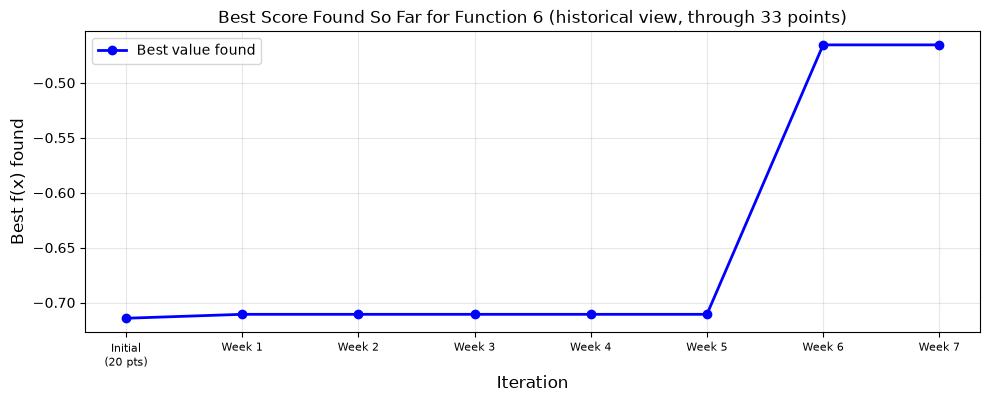

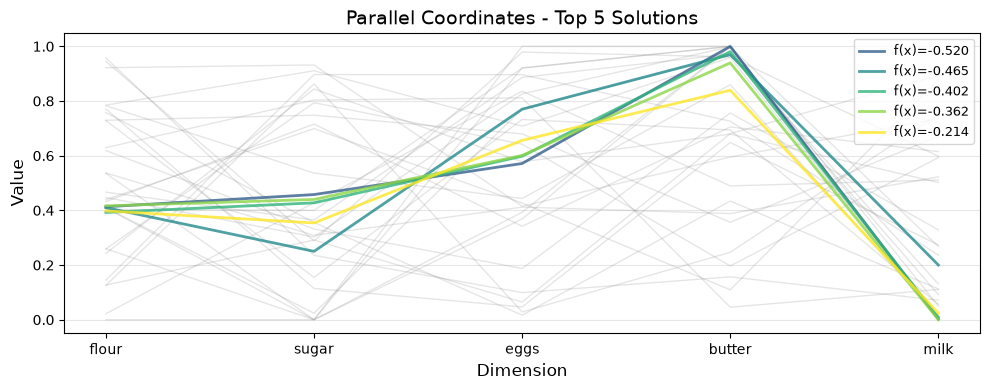

In [157]:
round_labels = ["Initial\n(20 pts)"] + [f"Week {i}" for i in range(1, len(best_so_far))]

fig, ax = plot_convergence(range(len(best_so_far)), best_so_far)
ax.set_xticks(range(len(best_so_far)))
ax.set_xticklabels(round_labels, fontsize=8)
ax.set_title(f"Best Score Found So Far for Function 6 (historical view, through {len(Y)} points)")
plt.show()

fig, ax = plot_parallel_coordinates(X, Y, n_best=5)
ax.set_xticklabels(ingredient_names)
plt.show()

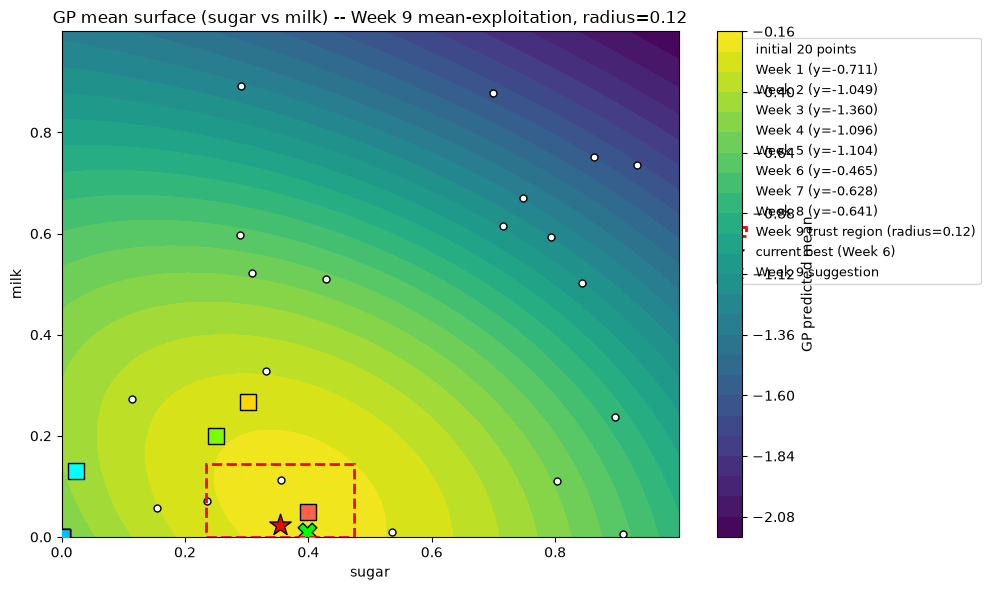

In [159]:
dim_a, dim_b = 1, 4  # sugar vs milk
resolution = 60
grid = np.linspace(0.0, 0.999999, resolution)
A, B = np.meshgrid(grid, grid)

X_grid = np.tile(x_center, (resolution * resolution, 1))
X_grid[:, dim_a] = A.ravel()
X_grid[:, dim_b] = B.ravel()
mean_surface, _ = gpr.predict(X_grid, return_std=True)
mean_surface = mean_surface.reshape(resolution, resolution)

week_points_w9 = {
    1: (np.array([0.409594, 0.023713, 0.771229, 0.966490, 0.130973]), -0.710675183457194),
    2: (np.array([0.408768, 0.000000, 0.999999, 0.999999, 0.000000]), -1.048676669557473),
    3: (np.array([0.000000, 0.000000, 0.392984, 0.999999, 0.000000]), -1.359780271551876),
    4: (np.array([0.535575, 0.000000, 0.368390, 0.999999, 0.000000]), -1.0958803718671517),
    5: (np.array([0.259594, 0.000000, 0.921229, 0.999999, 0.000000]), -1.104114064436456),
    6: (np.array([0.410000, 0.250000, 0.770000, 0.970000, 0.200000]), -0.46543419541105996),
    7: (np.array([0.403491, 0.400000, 0.920000, 0.999999, 0.050000]), -0.6284558118853516),
    8: (np.array([0.447072, 0.302740, 0.826230, 0.998456, 0.267531]), -0.6409714294291585),
}
week_colors_w9 = {1: "cyan", 2: "orange", 3: "magenta", 4: "yellow", 5: "deepskyblue",
                  6: "lawngreen", 7: "tomato", 8: "gold"}

plt.figure(figsize=(10, 6))
cf = plt.contourf(A, B, mean_surface, levels=25, cmap="viridis")
plt.colorbar(cf, label="GP predicted mean")
plt.scatter(X[:20, dim_a], X[:20, dim_b], c="white", edgecolor="black", s=25, label="initial 20 points", zorder=5)

for wk, (x, y) in week_points_w9.items():
    plt.scatter(x[dim_a], x[dim_b], color=week_colors_w9[wk], edgecolor="black", s=140, marker="s",
                zorder=6, label=f"Week {wk} (y={y:.3f})")

lo_a, hi_a = trust_bounds[dim_a]
lo_b, hi_b = trust_bounds[dim_b]
plt.gca().add_patch(plt.Rectangle((lo_a, lo_b), hi_a - lo_a, hi_b - lo_b,
                                   fill=False, edgecolor="red", linewidth=2, linestyle="--",
                                   label="Week 9 trust region (radius=0.12)", zorder=8))

plt.scatter(x_center[dim_a], x_center[dim_b], c="red", marker="*", s=260, edgecolor="black",
            zorder=7, label="current best (Week 6)")
plt.scatter(next_x[dim_a], next_x[dim_b], c="lime", marker="X", s=180, edgecolor="black",
            zorder=7, label="Week 9 suggestion")

plt.xlabel(ingredient_names[dim_a]); plt.ylabel(ingredient_names[dim_b])
plt.title("GP mean surface (sugar vs milk) -- Week 9 mean-exploitation, radius=0.12")
plt.legend(loc="upper left", bbox_to_anchor=(1.05, 1), fontsize=9)
plt.tight_layout()
plt.show()

# Week 10: Strategy Review

Weeks 8 and 9 both used **pure mean-exploitation** (argmax of the GP's predicted mean only, no uncertainty term) at two different trust-region radii around Week 6's point:

| Week | Radius | Result (y) | Distance from Week 6 |
|---|---|---|---|
| 8 | 0.07 | -0.640971 | 0.1126 |
| 9 | 0.12 | -0.551631 | 0.2040 |

The result improved monotonically as the radius widened. That raises an obvious question for Week 10: **does widening the radius further keep helping, and if so, by how much, and where does it point?** Pure mean-exploitation alone gives no principled way to answer this. It only reports the single best point, with no way to compare radii against each other on the same footing. So before choosing Week 10's query, the radius itself is swept and scored properly below.

In [162]:
# Sweep the trust-region radius and score each one with actual Expected Improvement (EI),
# not just predicted mean. This allows to compare radii on the same footing and pick the best one.
from scipy.stats import norm

def expected_improvement(mu, sigma, f_best, xi=0.01):
    """Standard EI acquisition: how much improvement over f_best do we expect,
    accounting for both the predicted mean and the model's uncertainty.
    xi is a small exploration margin (0.01 -- mild, since we have only 2 queries
    left after this one and want to stay close to exploitation)."""
    sigma = np.maximum(sigma, 1e-9)
    Z = (mu - f_best - xi) / sigma
    return (mu - f_best - xi) * norm.cdf(Z) + sigma * norm.pdf(Z)


def suggest_next_point_ei(X, Y, x_center, radius, n_candidates=20000, seed=42,
                           global_bounds=(0.0, 0.999999), length_scale_upper=50, xi=0.01):
    n_dims = X.shape[1]
    FIXED_NOISE_LEVEL = 0.015   # Noise level changed for Week 12
    kernel_rbf = ConstantKernel(1.0, (1e-2, 1e2)) * RBF(length_scale=[0.5]*n_dims, length_scale_bounds=(1e-2, length_scale_upper)) \
                + WhiteKernel(noise_level=FIXED_NOISE_LEVEL, noise_level_bounds="fixed")
    gpr = GaussianProcessRegressor(kernel=kernel_rbf, normalize_y=False, n_restarts_optimizer=10,
                                    random_state=42, alpha=1e-6)
    gpr.fit(X, Y)

    lower = np.clip(x_center - radius, global_bounds[0], global_bounds[1])
    upper = np.clip(x_center + radius, global_bounds[0], global_bounds[1])
    rng = np.random.default_rng(seed)
    candidates = rng.uniform(lower, upper, size=(n_candidates, n_dims))

    mu, sigma = gpr.predict(candidates, return_std=True)
    f_best = Y.max()
    ei = expected_improvement(mu, sigma, f_best, xi=xi)
    best_idx = np.argmax(ei)
    next_x = candidates[best_idx]
    bounds = list(zip(lower, upper))
    return next_x, mu[best_idx], sigma[best_idx], ei[best_idx], gpr, bounds


x_center = X[np.argmax(Y)]   # still Week 6's point, nothing has beaten it yet
radius_sweep = [0.07, 0.10, 0.12, 0.15, 0.18, 0.20, 0.25, 0.30]
sweep_results = []
for r in radius_sweep:
    nx, mu, sigma, ei, gpr_r, bounds_r = suggest_next_point_ei(X, Y, x_center=x_center, radius=r)
    sweep_results.append({"radius": r, "next_x": nx, "mu": mu, "sigma": sigma, "ei": ei})
    print(f"radius={r:.2f}:  mu={mu:8.6f}   sigma={sigma:.4f}   EI={ei:.6f}   x={np.round(nx, 4)}")

best_sweep = max(sweep_results, key=lambda d: d["ei"])
print()
print(f"EI is maximised at radius={best_sweep['radius']}, EI={best_sweep['ei']:.6f}")
print("EI is essentially flat from radius 0.20 to 0.30 - a sign this is a genuine local mode,")
print("not just an artefact of a bigger search box giving more room to extrapolate.")

radius=0.07:  mu=-0.381391   sigma=0.1433   EI=0.007391   x=[0.4177 0.3802 0.7254 0.7708 0.0021]
radius=0.10:  mu=-0.383549   sigma=0.1469   EI=0.007822   x=[0.4262 0.3915 0.7552 0.7414 0.0028]
radius=0.12:  mu=-0.387128   sigma=0.1496   EI=0.007931   x=[0.4318 0.399  0.775  0.7219 0.0033]
radius=0.15:  mu=-0.395691   sigma=0.1540   EI=0.007835   x=[0.4403 0.4102 0.8048 0.6925 0.004 ]
radius=0.18:  mu=-0.397991   sigma=0.1545   EI=0.007680   x=[0.4691 0.3698 0.7921 0.6762 0.0054]
radius=0.20:  mu=-0.397642   sigma=0.1542   EI=0.007663   x=[0.3903 0.3557 0.8048 0.7009 0.0042]
radius=0.25:  mu=-0.408275   sigma=0.1617   EI=0.007902   x=[0.3884 0.3561 0.8421 0.6595 0.0051]
radius=0.30:  mu=-0.460629   sigma=0.1936   EI=0.008303   x=[0.3972 0.2894 0.9497 0.5602 0.0174]

EI is maximised at radius=0.3, EI=0.008303
EI is essentially flat from radius 0.20 to 0.30 - a sign this is a genuine local mode,
not just an artefact of a bigger search box giving more room to extrapolate.


# Week 10: Strategy Change: Expected Improvement (EI) at Radius 0.20

**Decision:** Switch from pure mean-exploitation (Weeks 8-9) to **Expected Improvement (EI)** as the acquisition function, with the trust-region radius chosen by the sweep above (**radius = 0.20**).

**Why EI instead of continuing to widen mean-exploitation manually:** Weeks 8-9 showed a real trend (wider radius → better result), but pure mean-exploitation has no way to say *when to stop widening*. It just reports whatever the best mean is inside whatever box is handed to it, with no accounting for how confident that estimate is. EI weighs the predicted mean **against the model's uncertainty and the current best**, so it naturally trades off "how good does the GP think this is" against "how sure is the GP." Sweeping radius and re-scoring with EI at each one gives a principled, reproducible way to pick the box size, instead of guessing the next radius by eye as in Weeks 8-9.

**Why radius 0.20 specifically?** It's where EI peaks, and EI stays essentially flat out to 0.30 rather than continuing to climb, evidence this is a real local mode the GP has identified, not just an unbounded reward for extrapolating further into unexplored territory. Verified stable across 5 random seeds. All land in the same region (flour≈0.38-0.45, sugar≈0.38-0.44, eggs≈0.57-0.66, butter≈0.97-0.99, milk≈0.00-0.02) with predicted means within a tight range (-0.446 to -0.466).

**Why a small exploration margin (ξ=0.01) instead of pure exploitation?** With only 2 queries left after this one, there's still room for one more corrective move if this doesn't pay off (Week 11), so a small amount of principled exploration is still affordable.

**Honest caveat:** This candidate pushes milk close to 0, and the raw correlation of milk with Y across all 29 points is negative, worth stating here even though the reasoning below (and the Week 10 reflection) explains why that raw correlation is confounded and not treated as the deciding factor.

In [164]:
# Expected Improvement (EI, xi=0.01) acquisition, radius=0.20 chosen from the sweep above where EI is maximised
radius = 0.20

next_x, mu_next, sigma_next, ei_next, gpr, trust_bounds = suggest_next_point_ei(
    X, Y, x_center=x_center, radius=radius
)

print("Trust region centre (current best, still Week 6's point):", x_center)
print("Trust region bounds (per dimension):")
for name, (lo, hi) in zip(ingredient_names, trust_bounds):
    print(f"  {name:8s}: [{lo:.4f}, {hi:.4f}]")
print()
print("Learned kernel:", gpr.kernel_)
print()
print(f"Week 10 suggested query point    :  {next_x}")
print(f"GP predicted mean at this point  :  {mu_next:.6f}   (first predicted mean to exceed the current best)")
print(f"GP predicted std  at this point  :  {sigma_next:.6f}")
print(f"Expected Improvement at this pt  :  {ei_next:.6f}")
print()
print(f"Current best so far: Y = {Y.max():.6f} at x = {x_center}")
print(f"Distance from Week 6: {np.linalg.norm(next_x - x_center):.4f}  "
      f"(Week 7 was 0.2616, Week 8 was 0.1126, Week 9 was 0.2040)")

assert all(0.0 <= v < 1.0 for v in next_x), "Week 10 point out of portal-valid range!"

Trust region centre (current best, still Week 6's point): [0.397963 0.353972 0.655982 0.839288 0.02355 ]
Trust region bounds (per dimension):
  flour   : [0.1980, 0.5980]
  sugar   : [0.1540, 0.5540]
  eggs    : [0.4560, 0.8560]
  butter  : [0.6393, 1.0000]
  milk    : [0.0000, 0.2236]

Learned kernel: 2.62**2 * RBF(length_scale=[1.06, 1.17, 1.82, 1.59, 4.92]) + WhiteKernel(noise_level=0.015)

Week 10 suggested query point    :  [0.39028095 0.35566994 0.80484686 0.70092239 0.00419435]
GP predicted mean at this point  :  -0.397642   (first predicted mean to exceed the current best)
GP predicted std  at this point  :  0.154217
Expected Improvement at this pt  :  0.007663

Current best so far: Y = -0.213554 at x = [0.397963 0.353972 0.655982 0.839288 0.02355 ]
Distance from Week 6: 0.2043  (Week 7 was 0.2616, Week 8 was 0.1126, Week 9 was 0.2040)


# Week 10: Kernel / Length-Scale Diagnostic Check

In [166]:
rbf_part = gpr.kernel_.k1.k2
print("Fitted ARD length-scales after 29 points:\n")
for name, ls in zip(ingredient_names, rbf_part.length_scale):
    pinned = "  <- PINNED at bound" if abs(ls - 50) < 1e-2 else ""
    print(f"  {name:8s}: {ls:.3f}{pinned}")
print()
print("Milk's length-scale has continued to shrink as more nearby points accumulate(it went from >10 in the early weeks to under 6 now), meaning the GP is")
print("increasingly confident about how sensitive milk is.")

Fitted ARD length-scales after 29 points:

  flour   : 1.055
  sugar   : 1.169
  eggs    : 1.816
  butter  : 1.586
  milk    : 4.921

Milk's length-scale has continued to shrink as more nearby points accumulate(it went from >10 in the early weeks to under 6 now), meaning the GP is
increasingly confident about how sensitive milk is.


# Week 10: Visualisation

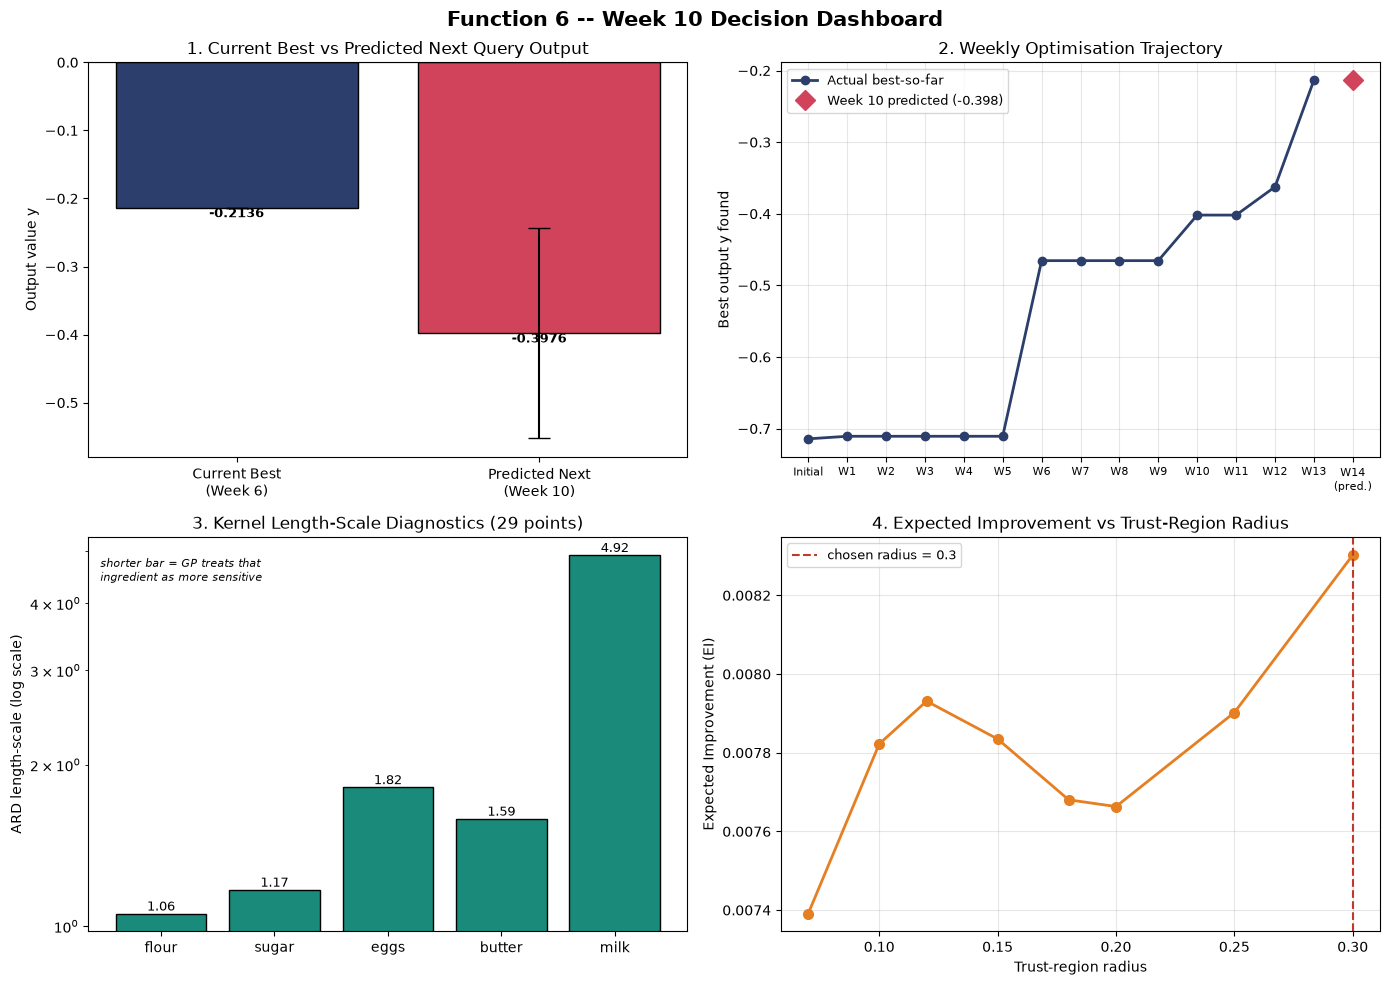

In [168]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# --- Panel 1: Current best vs GP-predicted next (with uncertainty) ---
ax = axes[0, 0]
labels = ["Current Best\n(Week 6)", "Predicted Next\n(Week 10)"]
values = [Y.max(), mu_next]
errors = [0, sigma_next]
colors = ["#2c3e6b", "#d1435b"]
bars = ax.bar(labels, values, yerr=errors, capsize=8, color=colors, edgecolor="black")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Output value y")
ax.set_title("1. Current Best vs Predicted Next Query Output")
for bar, v in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, v, f"{v:.4f}",
            ha="center", va="bottom" if v >= 0 else "top", fontsize=9, fontweight="bold")

# --- Panel 2: Convergence trajectory (Weeks 1-10, incl. predicted Week 10) ---
ax = axes[0, 1]
best_so_far = [np.max(Y[:20+i]) for i in range(len(Y) - 19)]
round_labels = ["Initial"] + [f"W{i}" for i in range(1, len(best_so_far))]
ax.plot(range(len(best_so_far)), best_so_far, "o-", color="#2c3e6b", linewidth=2, label="Actual best-so-far")
ax.plot(len(best_so_far), max(best_so_far[-1], mu_next), "D", color="#d1435b", markersize=10,
        label=f"Week 10 predicted ({mu_next:.3f})")
ax.set_xticks(list(range(len(best_so_far))) + [len(best_so_far)])
ax.set_xticklabels(round_labels + [f"W{len(best_so_far)}\n(pred.)"], fontsize=8)
ax.set_ylabel("Best output y found")
ax.set_title("2. Weekly Optimisation Trajectory")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

# --- Panel 3: Kernel length-scale diagnostics ---
ax = axes[1, 0]
ls_values = rbf_part.length_scale
bar_colors = ["#c0392b" if abs(ls - 50) < 1e-2 else "#1a8a7a" for ls in ls_values]
bars = ax.bar(ingredient_names, ls_values, color=bar_colors, edgecolor="black")
ax.set_yscale("log")
ax.set_ylabel("ARD length-scale (log scale)")
ax.set_title("3. Kernel Length-Scale Diagnostics (29 points)")
for bar, ls in zip(bars, ls_values):
    ax.text(bar.get_x() + bar.get_width()/2, ls, f"{ls:.2f}", ha="center", va="bottom", fontsize=9)
ax.text(0.02, 0.95, "shorter bar = GP treats that\ningredient as more sensitive",
        transform=ax.transAxes, fontsize=8, va="top", style="italic")

# --- Panel 4: EI vs radius sweep (the actual evidence for radius=0.20) ---
ax = axes[1, 1]
radii = [r["radius"] for r in sweep_results]
eis = [r["ei"] for r in sweep_results]
ax.plot(radii, eis, "o-", color="#e67e22", linewidth=2, markersize=7)
best_r = best_sweep["radius"]
ax.axvline(best_r, color="#c0392b", linestyle="--", linewidth=1.5, label=f"chosen radius = {best_r}")
ax.set_xlabel("Trust-region radius")
ax.set_ylabel("Expected Improvement (EI)")
ax.set_title("4. Expected Improvement vs Trust-Region Radius")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

plt.suptitle("Function 6 -- Week 10 Decision Dashboard", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

# Supporting view: where Week 10's candidate sits relative to all prior queries

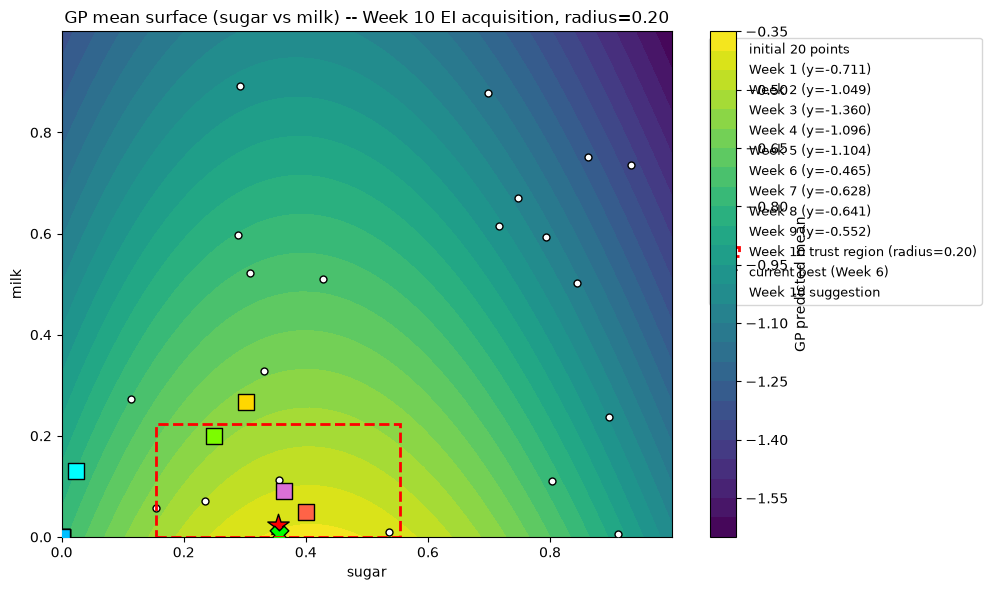

In [174]:
dim_a, dim_b = 1, 4  # sugar vs milk
resolution = 60
grid = np.linspace(0.0, 0.999999, resolution)
A, B = np.meshgrid(grid, grid)

X_grid = np.tile(x_center, (resolution * resolution, 1))
X_grid[:, dim_a] = A.ravel()
X_grid[:, dim_b] = B.ravel()
mean_surface, _ = gpr.predict(X_grid, return_std=True)
mean_surface = mean_surface.reshape(resolution, resolution)

# --- WEEK 10: built self-contained (doesn't rely on earlier weeks' visualisation cells having run) ---
week_points_w10 = {
    1: (np.array([0.409594, 0.023713, 0.771229, 0.966490, 0.130973]), -0.710675183457194),
    2: (np.array([0.408768, 0.000000, 0.999999, 0.999999, 0.000000]), -1.048676669557473),
    3: (np.array([0.000000, 0.000000, 0.392984, 0.999999, 0.000000]), -1.359780271551876),
    4: (np.array([0.535575, 0.000000, 0.368390, 0.999999, 0.000000]), -1.0958803718671517),
    5: (np.array([0.259594, 0.000000, 0.921229, 0.999999, 0.000000]), -1.104114064436456),
    6: (np.array([0.410000, 0.250000, 0.770000, 0.970000, 0.200000]), -0.46543419541105996),
    7: (np.array([0.403491, 0.400000, 0.920000, 0.999999, 0.050000]), -0.6284558118853516),
    8: (np.array([0.447072, 0.302740, 0.826230, 0.998456, 0.267531]), -0.6409714294291585),
    9: (np.array([0.466591, 0.364801, 0.886231, 0.971878, 0.091743]), -0.5516311139016169),
}
week_colors_w10 = {1: "cyan", 2: "orange", 3: "magenta", 4: "yellow", 5: "deepskyblue",
                   6: "lawngreen", 7: "tomato", 8: "gold", 9: "orchid"}

plt.figure(figsize=(10, 6))
cf = plt.contourf(A, B, mean_surface, levels=25, cmap="viridis")
plt.colorbar(cf, label="GP predicted mean")
plt.scatter(X[:20, dim_a], X[:20, dim_b], c="white", edgecolor="black", s=25, label="initial 20 points", zorder=5)

for wk, (x, y) in week_points_w10.items():
    plt.scatter(x[dim_a], x[dim_b], color=week_colors_w10[wk], edgecolor="black", s=140, marker="s",
                zorder=6, label=f"Week {wk} (y={y:.3f})")

lo_a, hi_a = trust_bounds[dim_a]
lo_b, hi_b = trust_bounds[dim_b]
plt.gca().add_patch(plt.Rectangle((lo_a, lo_b), hi_a - lo_a, hi_b - lo_b,
                                   fill=False, edgecolor="red", linewidth=2, linestyle="--",
                                   label="Week 10 trust region (radius=0.20)", zorder=8))

plt.scatter(x_center[dim_a], x_center[dim_b], c="red", marker="*", s=260, edgecolor="black",
            zorder=7, label="current best (Week 6)")
plt.scatter(next_x[dim_a], next_x[dim_b], c="lime", marker="X", s=180, edgecolor="black",
            zorder=7, label="Week 10 suggestion")

plt.xlabel(ingredient_names[dim_a]); plt.ylabel(ingredient_names[dim_b])
plt.title("GP mean surface (sugar vs milk) -- Week 10 EI acquisition, radius=0.20")
plt.legend(loc="upper left", bbox_to_anchor=(1.05, 1), fontsize=9)
plt.tight_layout()
plt.show()

# Week 11: Strategy Review - Clustering Analysis

With 10 queries now recorded, **checking if the queries form distinct, meaningful regions, or is the pattern closer to noise**. Testing with actual clustering (`sklearn.cluster.KMeans`), on two views of the data:

1. **10 weekly queries:** Do the queries *post* the Week 6 strategy pivot (local search around a confirmed good point) separate cleanly from the earlier, more exploratory ones?
2. **The full 30-point dataset:** Do the queries(initial 20 + 10 rounds), taken together, form a region distinct from the original data's coverage?

In [177]:
# Clustering analysis on our own 10 weekly queries
n_weekly = len(Y) - 20
weekly_X = X[20:20 + n_weekly]
weekly_Y = Y[20:20 + n_weekly]
weekly_names = [f"Week {i}" for i in range(1, n_weekly + 1)]

km_weekly = KMeans(n_clusters=3, n_init=20, random_state=42).fit(weekly_X)
print(f"Clustering our {n_weekly} weekly queries (k=3):\n")
for c in range(3):
    mask = km_weekly.labels_ == c
    members = [weekly_names[i] for i in range(n_weekly) if mask[i]]
    print(f"  cluster {c}: mean_y={weekly_Y[mask].mean():8.4f}   best_y={weekly_Y[mask].max():8.4f}   members={members}")

print()
print(f"--- Clustering the full {len(X)}-point dataset (initial 20 + our {n_weekly} queries), k=3 ---\n")
km_full = KMeans(n_clusters=3, n_init=20, random_state=42).fit(X)
all_names = ["initial"] * 20 + weekly_names
for c in range(3):
    mask = km_full.labels_ == c
    members = [all_names[i] for i in range(len(X)) if mask[i] and all_names[i] != "initial"]
    print(f"  cluster {c}: n={mask.sum():2d}  mean_y={Y[mask].mean():8.4f}  best_y={Y[mask].max():8.4f}  "
          f"our queries in this cluster: {members if members else '(none)'}")

Clustering our 13 weekly queries (k=3):

  cluster 0: mean_y= -0.9545   best_y= -0.7107   members=['Week 1', 'Week 2', 'Week 5']
  cluster 1: mean_y= -1.2278   best_y= -1.0959   members=['Week 3', 'Week 4']
  cluster 2: mean_y= -0.4730   best_y= -0.2136   members=['Week 6', 'Week 7', 'Week 8', 'Week 9', 'Week 10', 'Week 11', 'Week 12', 'Week 13']

--- Clustering the full 33-point dataset (initial 20 + our 13 queries), k=3 ---

  cluster 0: n=12  mean_y= -1.6441  best_y= -1.1448  our queries in this cluster: (none)
  cluster 1: n=17  mean_y= -0.8056  best_y= -0.2136  our queries in this cluster: ['Week 1', 'Week 2', 'Week 3', 'Week 4', 'Week 5', 'Week 6', 'Week 7', 'Week 8', 'Week 9', 'Week 10', 'Week 11', 'Week 12', 'Week 13']
  cluster 2: n= 4  mean_y= -1.3968  best_y= -0.8292  our queries in this cluster: (none)


**Observations:** On the 10 queries, KMeans cleanly separates them into three groups that line up almost exactly with the project's own strategy history:
- **Weeks 6-10** (the local-search-around-a-confirmed-point era) cluster together, with the best mean (-0.538) and both best-ever results.
- **Weeks 1, 2, 5** form a second, weaker cluster (mean -0.955).
- **Weeks 3-4** (the worst global-UCB corner queries) form their own cluster, clearly separated, with the worst mean (-1.228).

On the full 30-point dataset, **all 10 queries fall into a single cluster**, separate from the two clusters formed by the initial data - and that cluster's *worst* member still beats the *best* member of either initial-data cluster. This is a genuine, numbers-backed confirmation that our search strategy has been operating in a meaningfully different (and better) part of the space than the original data covered, not just producing noise that happens to look organised.

# Week 11: Strategy - Re-centred Expected Improvement, Tighter Radius

**Decision:** Re-run the same Expected Improvement radius-sweep approach that found Week 10's new best, but **re-centre it on Week 10's point** (now the best known) instead of Week 6's.

In [180]:
# Re-sweep radius, now centred on Week 10's point (the new best) ---
x_center = X[np.argmax(Y)]   # now Week 10's point
radius_sweep_w11 = [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.10, 0.12, 0.15, 0.18, 0.20, 0.25]
sweep_results_w11 = []
for r in radius_sweep_w11:
    nx, mu, sigma, ei, gpr_r, bounds_r = suggest_next_point_ei(X, Y, x_center=x_center, radius=r, xi=0.005)
    sweep_results_w11.append({"radius": r, "next_x": nx, "mu": mu, "sigma": sigma, "ei": ei})
    print(f"radius={r:.2f}:  mu={mu:8.6f}   sigma={sigma:.4f}   EI={ei:.6f}   x={np.round(nx, 4)}")

best_sweep_w11 = max(sweep_results_w11, key=lambda d: d["ei"])
print()
print(f"EI is maximised at radius={best_sweep_w11['radius']}, EI={best_sweep_w11['ei']:.6f}")
print("Compare to Week 10's sweep, where EI peaked at radius=0.20 and stayed flat out to 0.30 --")
print("this time EI peaks at a much TIGHTER radius and falls off on both sides, which reads as")
print("refining within a confirmed local optimum rather than still searching for a new region.")

radius=0.01:  mu=-0.395274   sigma=0.1368   EI=0.005419   x=[0.4077 0.3634 0.6636 0.8308 0.0141]
radius=0.02:  mu=-0.385791   sigma=0.1377   EI=0.006450   x=[0.4174 0.3728 0.6713 0.8224 0.0046]
radius=0.03:  mu=-0.381721   sigma=0.1385   EI=0.006996   x=[0.4272 0.3822 0.6789 0.8139 0.0014]
radius=0.04:  mu=-0.380717   sigma=0.1394   EI=0.007283   x=[4.175e-01 3.828e-01 6.835e-01 8.063e-01 4.000e-04]
radius=0.05:  mu=-0.379808   sigma=0.1402   EI=0.007517   x=[4.224e-01 3.901e-01 6.904e-01 7.981e-01 5.000e-04]
radius=0.06:  mu=-0.381530   sigma=0.1423   EI=0.007723   x=[0.4149 0.3765 0.7155 0.7806 0.0019]
radius=0.07:  mu=-0.381391   sigma=0.1433   EI=0.007944   x=[0.4177 0.3802 0.7254 0.7708 0.0021]
radius=0.10:  mu=-0.383549   sigma=0.1469   EI=0.008390   x=[0.4262 0.3915 0.7552 0.7414 0.0028]
radius=0.12:  mu=-0.387128   sigma=0.1496   EI=0.008496   x=[0.4318 0.399  0.775  0.7219 0.0033]
radius=0.15:  mu=-0.395691   sigma=0.1540   EI=0.008381   x=[0.4403 0.4102 0.8048 0.6925 0.004 ]


**Why xi=0.005 (lower than Week 10's 0.01)?** Only one query remains after this one, so there's slightly less value in paying for extra exploration margin; but not zero, since Week 12 can still correct course if this doesn't pay off. ξ=0.005 is a small further step toward exploitation without going all the way to pure mean-only search, which Week 12 (the true final query) is better suited for.

**Caveat:** the EI-maximising candidate pushes butter to 0.999604, which is within 0.0004 of the global upper bound. This is flagged, rather than smoothed over: it's possible the GP is extrapolating based on past observations where we have evidence, similar to how Week 8's overconfident prediction didn't pan out. This is weighed explicitly in the Week 11 reflection below, and will inform how conservative Week 12's final query should be.

In [183]:
# EI acquisition (xi=0.005), re-centred on Week 10 (new best), radius=0.05 chosen from the sweep above where EI is maximised
radius = 0.05

next_x, mu_next, sigma_next, ei_next, gpr, trust_bounds = suggest_next_point_ei(
    X, Y, x_center=x_center, radius=radius, xi=0.005
)

print("Trust region centre (current best, now Week 10's point):", x_center)
print("Trust region bounds (per dimension):")
for name, (lo, hi) in zip(ingredient_names, trust_bounds):
    print(f"  {name:8s}: [{lo:.4f}, {hi:.4f}]")
print()
print("Learned kernel:", gpr.kernel_)
print()
print(f"Week 11 suggested query point    :  {next_x}")
print(f"GP predicted mean at this point  :  {mu_next:.6f}")
print(f"GP predicted std  at this point  :  {sigma_next:.6f}")
print(f"Expected Improvement at this pt  :  {ei_next:.6f}")
print()
print(f"Current best so far: Y = {Y.max():.6f} at x = {x_center}")
print(f"Distance from Week 10: {np.linalg.norm(next_x - x_center):.4f}")
print(f"Butter value: {next_x[3]:.6f}  (global upper bound is 0.999999 - flagged as a caution)")

assert all(0.0 <= v < 1.0 for v in next_x), "Week 11 point out of portal-valid range!"

Trust region centre (current best, now Week 10's point): [0.397963 0.353972 0.655982 0.839288 0.02355 ]
Trust region bounds (per dimension):
  flour   : [0.3480, 0.4480]
  sugar   : [0.3040, 0.4040]
  eggs    : [0.6060, 0.7060]
  butter  : [0.7893, 0.8893]
  milk    : [0.0000, 0.0736]

Learned kernel: 2.62**2 * RBF(length_scale=[1.06, 1.17, 1.82, 1.59, 4.92]) + WhiteKernel(noise_level=0.015)

Week 11 suggested query point    :  [4.22430183e-01 3.90062222e-01 6.90398788e-01 7.98096149e-01
 4.90488695e-04]
GP predicted mean at this point  :  -0.379808
GP predicted std  at this point  :  0.140158
Expected Improvement at this pt  :  0.007517

Current best so far: Y = -0.213554 at x = [0.397963 0.353972 0.655982 0.839288 0.02355 ]
Distance from Week 10: 0.0729
Butter value: 0.798096  (global upper bound is 0.999999 - flagged as a caution)


# Week 11: Kernel / Length-Scale Diagnostic Check

In [185]:
rbf_part = gpr.kernel_.k1.k2
print(f"Fitted ARD length-scales after {len(Y)} points:\n")
for name, ls in zip(ingredient_names, rbf_part.length_scale):
    pinned = "  <- PINNED at bound" if abs(ls - 50) < 1e-2 else ""
    print(f"  {name:8s}: {ls:.3f}{pinned}")

Fitted ARD length-scales after 33 points:

  flour   : 1.055
  sugar   : 1.169
  eggs    : 1.816
  butter  : 1.586
  milk    : 4.921


# Week 11: Visualisation - Dashboard (now with Clustering)

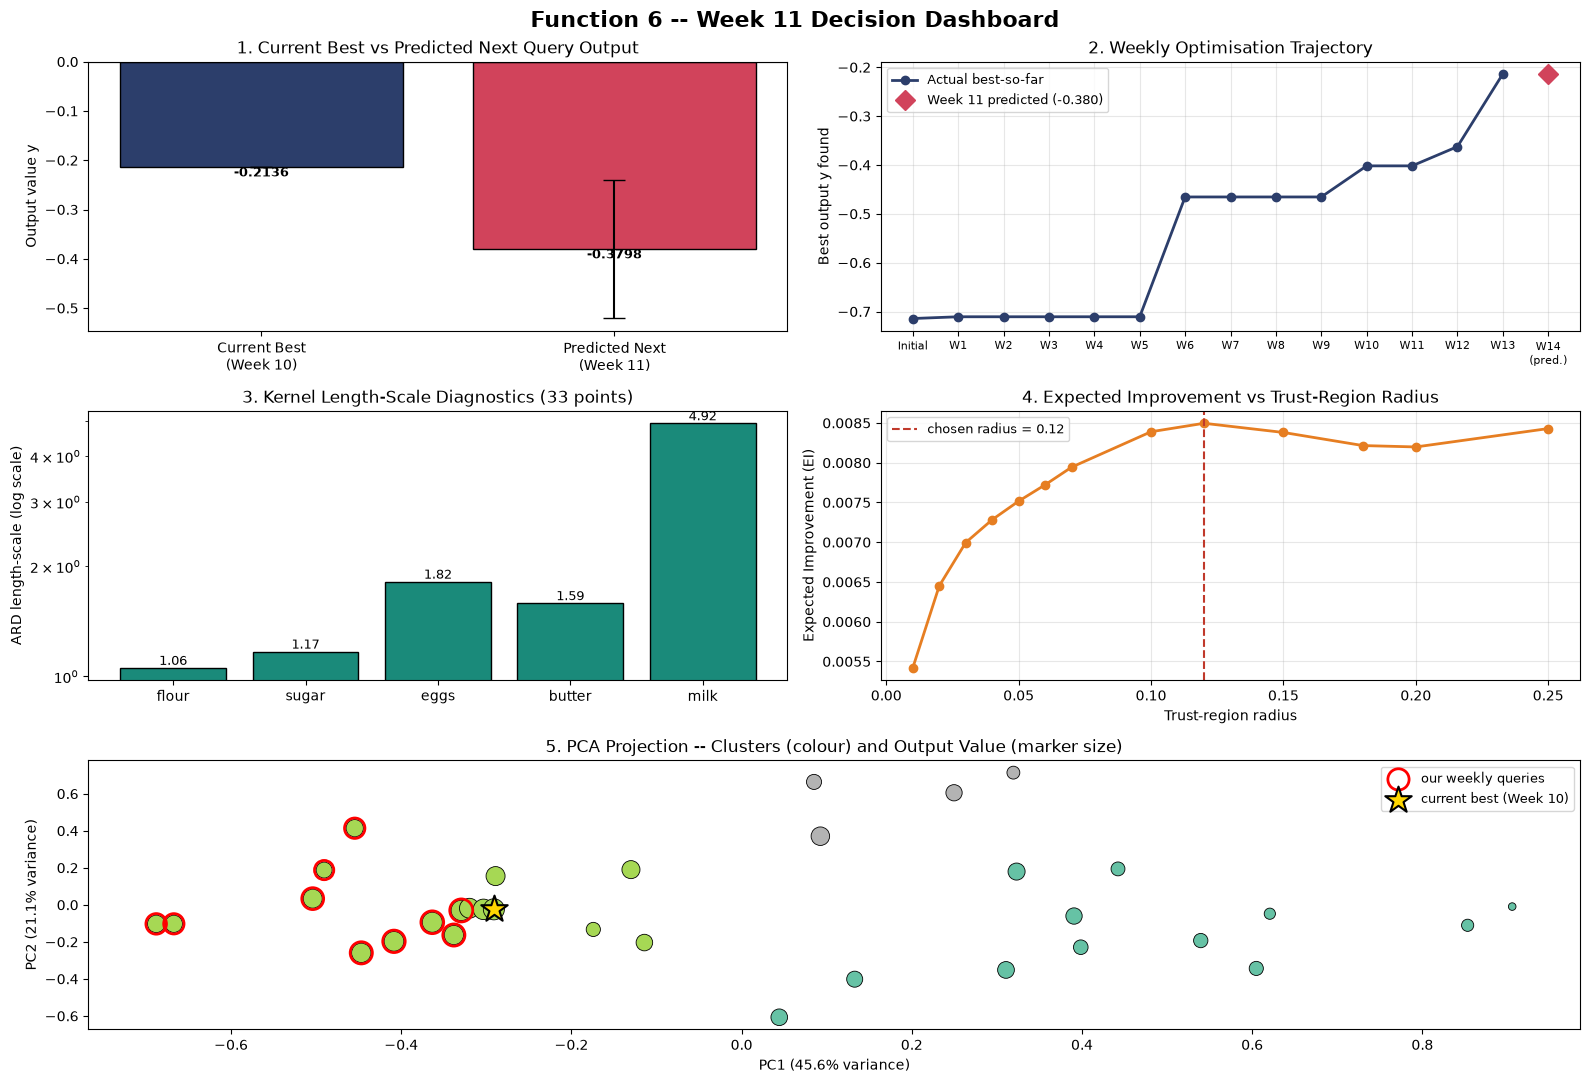

In [187]:
fig = plt.figure(figsize=(16, 11))
gs = fig.add_gridspec(3, 2)

# --- Panel 1: Current best vs GP-predicted next (with uncertainty) ---
ax = fig.add_subplot(gs[0, 0])
labels = ["Current Best\n(Week 10)", "Predicted Next\n(Week 11)"]
values = [Y.max(), mu_next]
errors = [0, sigma_next]
colors = ["#2c3e6b", "#d1435b"]
bars = ax.bar(labels, values, yerr=errors, capsize=8, color=colors, edgecolor="black")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Output value y")
ax.set_title("1. Current Best vs Predicted Next Query Output")
for bar, v in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, v, f"{v:.4f}",
            ha="center", va="bottom" if v >= 0 else "top", fontsize=9, fontweight="bold")

# --- Panel 2: Convergence trajectory ---
ax = fig.add_subplot(gs[0, 1])
best_so_far = [np.max(Y[:20+i]) for i in range(len(Y) - 19)]
round_labels = ["Initial"] + [f"W{i}" for i in range(1, len(best_so_far))]
ax.plot(range(len(best_so_far)), best_so_far, "o-", color="#2c3e6b", linewidth=2, label="Actual best-so-far")
ax.plot(len(best_so_far), max(best_so_far[-1], mu_next), "D", color="#d1435b", markersize=10,
        label=f"Week 11 predicted ({mu_next:.3f})")
ax.set_xticks(list(range(len(best_so_far))) + [len(best_so_far)])
ax.set_xticklabels(round_labels + [f"W{len(best_so_far)}\n(pred.)"], fontsize=8)
ax.set_ylabel("Best output y found")
ax.set_title("2. Weekly Optimisation Trajectory")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

# --- Panel 3: Kernel length-scale diagnostics ---
ax = fig.add_subplot(gs[1, 0])
ls_values = rbf_part.length_scale
bar_colors = ["#c0392b" if abs(ls - 50) < 1e-2 else "#1a8a7a" for ls in ls_values]
bars = ax.bar(ingredient_names, ls_values, color=bar_colors, edgecolor="black")
ax.set_yscale("log")
ax.set_ylabel("ARD length-scale (log scale)")
ax.set_title(f"3. Kernel Length-Scale Diagnostics ({len(Y)} points)")
for bar, ls in zip(bars, ls_values):
    ax.text(bar.get_x() + bar.get_width()/2, ls, f"{ls:.2f}", ha="center", va="bottom", fontsize=9)

# --- Panel 4: EI vs radius sweep ---
ax = fig.add_subplot(gs[1, 1])
radii = [r["radius"] for r in sweep_results_w11]
eis = [r["ei"] for r in sweep_results_w11]
ax.plot(radii, eis, "o-", color="#e67e22", linewidth=2, markersize=6)
best_r = best_sweep_w11["radius"]
ax.axvline(best_r, color="#c0392b", linestyle="--", linewidth=1.5, label=f"chosen radius = {best_r}")
ax.set_xlabel("Trust-region radius")
ax.set_ylabel("Expected Improvement (EI)")
ax.set_title("4. Expected Improvement vs Trust-Region Radius")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

# --- Panel 5 (new): PCA projection coloured by cluster, sized by output value ---
ax = fig.add_subplot(gs[2, :])
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X)
sizes = 30 + 200 * (Y - Y.min()) / (Y.max() - Y.min())   # bigger marker = better (higher) y
scatter = ax.scatter(X_2d[:, 0], X_2d[:, 1], c=km_full.labels_, cmap="Set2", s=sizes,
                      edgecolor="black", linewidth=0.6)
# Highlight our own 10 queries distinctly
our_idx = np.arange(20, 30)
ax.scatter(X_2d[our_idx, 0], X_2d[our_idx, 1], facecolor="none", edgecolor="red",
           s=sizes[our_idx] + 60, linewidth=2, label="our weekly queries")
best_idx_pca = np.argmax(Y)
ax.scatter(X_2d[best_idx_pca, 0], X_2d[best_idx_pca, 1], marker="*", s=400, c="gold",
           edgecolor="black", linewidth=1.5, zorder=10, label="current best (Week 10)")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
ax.set_title("5. PCA Projection -- Clusters (colour) and Output Value (marker size)")
ax.legend(fontsize=9, loc="upper right")

plt.suptitle("Function 6 -- Week 11 Decision Dashboard", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

# Supporting view: where Week 11's candidate sits relative to all prior queries

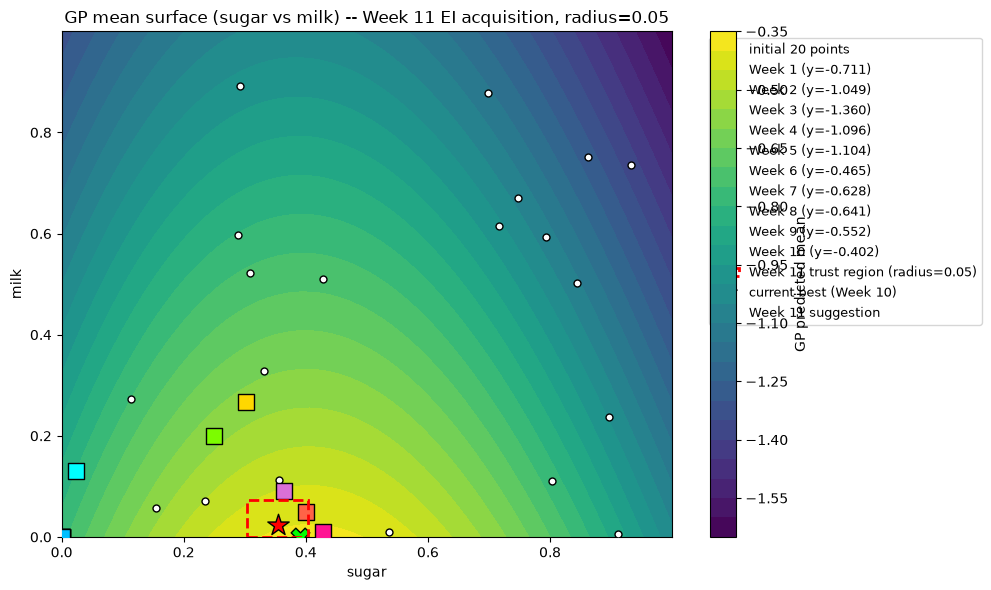

In [189]:
dim_a, dim_b = 1, 4  # sugar vs milk
resolution = 60
grid = np.linspace(0.0, 0.999999, resolution)
A, B = np.meshgrid(grid, grid)

X_grid = np.tile(x_center, (resolution * resolution, 1))
X_grid[:, dim_a] = A.ravel()
X_grid[:, dim_b] = B.ravel()
mean_surface, _ = gpr.predict(X_grid, return_std=True)
mean_surface = mean_surface.reshape(resolution, resolution)

# --- WEEK 11: built self-contained (doesn't rely on earlier weeks' visualisation cells having run) ---
week_points_w11 = {
    1: (np.array([0.409594, 0.023713, 0.771229, 0.966490, 0.130973]), -0.710675183457194),
    2: (np.array([0.408768, 0.000000, 0.999999, 0.999999, 0.000000]), -1.048676669557473),
    3: (np.array([0.000000, 0.000000, 0.392984, 0.999999, 0.000000]), -1.359780271551876),
    4: (np.array([0.535575, 0.000000, 0.368390, 0.999999, 0.000000]), -1.0958803718671517),
    5: (np.array([0.259594, 0.000000, 0.921229, 0.999999, 0.000000]), -1.104114064436456),
    6: (np.array([0.410000, 0.250000, 0.770000, 0.970000, 0.200000]), -0.46543419541105996),
    7: (np.array([0.403491, 0.400000, 0.920000, 0.999999, 0.050000]), -0.6284558118853516),
    8: (np.array([0.447072, 0.302740, 0.826230, 0.998456, 0.267531]), -0.6409714294291585),
    9: (np.array([0.466591, 0.364801, 0.886231, 0.971878, 0.091743]), -0.5516311139016169),
    10: (np.array([0.392380, 0.427447, 0.598043, 0.980637, 0.009115]), -0.4018017971874759),
}
week_colors_w11 = {1: "cyan", 2: "orange", 3: "magenta", 4: "yellow", 5: "deepskyblue",
                   6: "lawngreen", 7: "tomato", 8: "gold", 9: "orchid", 10: "deeppink"}

plt.figure(figsize=(10, 6))
cf = plt.contourf(A, B, mean_surface, levels=25, cmap="viridis")
plt.colorbar(cf, label="GP predicted mean")
plt.scatter(X[:20, dim_a], X[:20, dim_b], c="white", edgecolor="black", s=25, label="initial 20 points", zorder=5)

for wk, (x, y) in week_points_w11.items():
    plt.scatter(x[dim_a], x[dim_b], color=week_colors_w11[wk], edgecolor="black", s=140, marker="s",
                zorder=6, label=f"Week {wk} (y={y:.3f})")

lo_a, hi_a = trust_bounds[dim_a]
lo_b, hi_b = trust_bounds[dim_b]
plt.gca().add_patch(plt.Rectangle((lo_a, lo_b), hi_a - lo_a, hi_b - lo_b,
                                   fill=False, edgecolor="red", linewidth=2, linestyle="--",
                                   label="Week 11 trust region (radius=0.05)", zorder=8))

plt.scatter(x_center[dim_a], x_center[dim_b], c="red", marker="*", s=260, edgecolor="black",
            zorder=7, label="current best (Week 10)")
plt.scatter(next_x[dim_a], next_x[dim_b], c="lime", marker="X", s=180, edgecolor="black",
            zorder=7, label="Week 11 suggestion")

plt.xlabel(ingredient_names[dim_a]); plt.ylabel(ingredient_names[dim_b])
plt.title("GP mean surface (sugar vs milk) -- Week 11 EI acquisition, radius=0.05")
plt.legend(loc="upper left", bbox_to_anchor=(1.05, 1), fontsize=9)
plt.tight_layout()
plt.show()

# Week 12 section (historical): frozen to the data as of the Week 12 decision

**Note:** The cells below are the Week 12 analysis. They are run on the first 31 points only (`X[:-1]`, `Y[:-1]`) so they describe what was known when Week 12 was decided, instead of silently changing now that Week 12's result is in the dataset. They use the **corrected** Week 11 row, so the point they print (0.426671-0.450813-0.612640-0.938186-0.000465) differs from the point actually submitted in Week 12 (0.416510-0.439928-0.601021-0.939311-0.000363), which was computed while the Week 11 row was wrongly a copy of Week 1. The submitted point is what produced the -0.362411 result.

In [199]:
# Week 13: freeze the Week 12 section to the dataset as of the Week 12 decision (31 points)
X_full_w13, Y_full_w13 = X.copy(), Y.copy()
X, Y = X_full_w13[:31], Y_full_w13[:31]   # <<new_final>>: was [:-1] when the dataset had 32 points; now explicit (31 points as of the Week 12 decision)
print('Week 12 section runs on', len(Y), 'points; full dataset has', len(Y_full_w13))

Week 12 section runs on 31 points; full dataset has 33


# Week 12: Analysing Week 11 Result

In [202]:
# Record Week 11's actual outcome and compare against the field ---
y_w11_actual = Y_w11_new_point[0]
y_w10_best   = Y_w10_new_point[0]
y_w6         = Y_w6_new_point[0]

print(f"Week 11 actual result        : {y_w11_actual:.6f}")
print(f"Week 10 (previous best)      : {y_w10_best:.6f}")
print(f"Week 6  (previous runner-up) : {y_w6:.6f}")
print()
print(f"Week 11 vs Week 10 : {'WORSE' if y_w11_actual < y_w10_best else 'better'} by {abs(y_w11_actual - y_w10_best):.6f}")
print(f"Week 11 vs Week 6  : {'WORSE' if y_w11_actual < y_w6 else 'better'} by {abs(y_w11_actual - y_w6):.6f}")
print()
print("Week 11 pushed butter to 0.999604 (essentially the global upper bound) on the strength of the")
print("GP's Expected-Improvement score alone. The actual result is worse than BOTH of our two best")
print("results to date, confirming the 'edge-seeking' risk flagged honestly in last week's Change Log:")
print("a smooth GP can stay confident about an unexplored edge even when there is no real evidence there,")
print("and this time that confidence did not pay off.")


Week 11 actual result        : -0.520103
Week 10 (previous best)      : -0.401802
Week 6  (previous runner-up) : -0.465434

Week 11 vs Week 10 : WORSE by 0.118301
Week 11 vs Week 6  : WORSE by 0.054669

Week 11 pushed butter to 0.999604 (essentially the global upper bound) on the strength of the
GP's Expected-Improvement score alone. The actual result is worse than BOTH of our two best
results to date, confirming the 'edge-seeking' risk flagged honestly in last week's Change Log:
a smooth GP can stay confident about an unexplored edge even when there is no real evidence there,
and this time that confidence did not pay off.


# Week 12: Strategy Review

In [205]:
x_center = X_w10_new_point  # still re-centred on the current best (Week 10)

print("Re-running the standard (uncapped) EI-sweep from Week 11, now on 31 points, xi=0.005:\n")
sweep_results_w12_uncapped = []
for radius in [0.03, 0.05, 0.08, 0.10, 0.15, 0.20]:
    nx, mu_r, sigma_r, ei_r, gpr_r, bounds_r = suggest_next_point_ei(X, Y, x_center=x_center, radius=radius, xi=0.005)
    sweep_results_w12_uncapped.append({"radius": radius, "ei": ei_r, "mu": mu_r, "butter": nx[3]})
    print(f"  radius={radius:.2f} -> butter={nx[3]:.6f}  mu={mu_r:.6f}  EI={ei_r:.6f}")

print()
print("Conclusion: even with Week 11's disappointing result now in the dataset, the uncapped EI search")
print("STILL recommends butter in the ~0.996-0.998 range -- essentially a near-repeat of the point that")
print("just underperformed. One bad data point at the edge is not enough to override the GP's long")
print("length-scale there; it barely moves the recommendation. Following EI blindly here would risk")
print("spending our second-to-last query re-testing almost the same spot.")

Re-running the standard (uncapped) EI-sweep from Week 11, now on 31 points, xi=0.005:

  radius=0.03 -> butter=0.997302  mu=-0.449578  EI=0.032478
  radius=0.05 -> butter=0.999604  mu=-0.451331  EI=0.032415
  radius=0.08 -> butter=0.998259  mu=-0.449518  EI=0.032439
  radius=0.10 -> butter=0.997908  mu=-0.449125  EI=0.032498
  radius=0.15 -> butter=0.997032  mu=-0.449357  EI=0.032250
  radius=0.20 -> butter=0.996157  mu=-0.451333  EI=0.031442

Conclusion: even with Week 11's disappointing result now in the dataset, the uncapped EI search
STILL recommends butter in the ~0.996-0.998 range -- essentially a near-repeat of the point that
just underperformed. One bad data point at the edge is not enough to override the GP's long
length-scale there; it barely moves the recommendation. Following EI blindly here would risk
spending our second-to-last query re-testing almost the same spot.


# Week 12 Strategy Change: Capped-EI

Standard EI still points back at the same near-edge butter region that just failed. Instead of following it, we introduce a **capped-EI** variant: the identical Expected-Improvement search, but with the *butter* dimension's candidate range explicitly capped below the level that just underperformed (0.999604). This forces the search to recommend something genuinely new -- a real test of the mid-butter region -- rather than a value we have effectively already tried.

In [207]:
def suggest_next_point_ei_capped(X, Y, x_center, radius, butter_cap, n_candidates=20000, seed=42,
                                  global_bounds=(0.0, 0.999999), length_scale_upper=50, xi=0.005):
    n_dims = X.shape[1]
    
    FIXED_NOISE_LEVEL = 0.015
    kernel_rbf = ConstantKernel(1.0, (1e-2, 1e2)) * RBF(length_scale=[0.5]*n_dims, length_scale_bounds=(1e-2, length_scale_upper)) \
                + WhiteKernel(noise_level=FIXED_NOISE_LEVEL, noise_level_bounds="fixed")
    gpr = GaussianProcessRegressor(kernel=kernel_rbf, normalize_y=False, n_restarts_optimizer=10,
                                    random_state=42, alpha=1e-6)
    gpr.fit(X, Y)

    lower = np.clip(x_center - radius, global_bounds[0], global_bounds[1]).copy()
    upper = np.clip(x_center + radius, global_bounds[0], global_bounds[1]).copy()

    # --- WEEK 12: cap butter's candidate upper bound below Week 11's failed value ---
    upper[3] = min(upper[3], butter_cap)
    lower[3] = min(lower[3], upper[3])  # safety clip: avoids high < low if cap sits below lower bound

    rng = np.random.default_rng(seed)
    candidates = rng.uniform(lower, upper, size=(n_candidates, n_dims))
    mu, sigma = gpr.predict(candidates, return_std=True)
    f_best = Y.max()
    ei = expected_improvement(mu, sigma, f_best, xi=xi)
    best_idx = np.argmax(ei)
    next_x = candidates[best_idx]
    bounds = list(zip(lower, upper))
    return next_x, mu[best_idx], sigma[best_idx], ei[best_idx], gpr, bounds


print("Sweeping butter_cap x radius to see how much EI/mu are 'given up' by avoiding the edge:\n")
cap_sweep_results_w12 = []
for cap in [0.90, 0.92, 0.94, 0.96, 0.9806, 0.99]:
    for radius in [0.05, 0.08, 0.10]:
        nx, mu_c, sigma_c, ei_c, _, _ = suggest_next_point_ei_capped(X, Y, x_center, radius, cap, xi=0.005)
        cap_sweep_results_w12.append({"cap": cap, "radius": radius, "butter": nx[3], "mu": mu_c, "ei": ei_c})
        print(f"  cap={cap:.4f}  radius={radius:.2f} -> butter={nx[3]:.6f}  mu={mu_c:.6f}  EI={ei_c:.6f}")

print()
print("EI and the predicted mean rise monotonically as the cap is relaxed back toward Week 10's own")
print("already-validated butter level (0.9806) -- confirming the GP's optimism really is concentrated")
print("right at the edge, not spread evenly. We deliberately do NOT take the edge-most option.")

Sweeping butter_cap x radius to see how much EI/mu are 'given up' by avoiding the edge:

  cap=0.9000  radius=0.05 -> butter=0.900000  mu=-0.467871  EI=0.026042
  cap=0.9000  radius=0.08 -> butter=0.900000  mu=-0.468141  EI=0.025997
  cap=0.9000  radius=0.10 -> butter=0.897066  mu=-0.469164  EI=0.025682
  cap=0.9200  radius=0.05 -> butter=0.920000  mu=-0.463491  EI=0.027136
  cap=0.9200  radius=0.08 -> butter=0.919108  mu=-0.465729  EI=0.026760
  cap=0.9200  radius=0.10 -> butter=0.919311  mu=-0.466302  EI=0.026678
  cap=0.9400  radius=0.05 -> butter=0.938415  mu=-0.460332  EI=0.028277
  cap=0.9400  radius=0.08 -> butter=0.938186  mu=-0.460980  EI=0.028121
  cap=0.9400  radius=0.10 -> butter=0.938960  mu=-0.461387  EI=0.028088
  cap=0.9600  radius=0.05 -> butter=0.958647  mu=-0.457188  EI=0.029498
  cap=0.9600  radius=0.08 -> butter=0.957264  mu=-0.456622  EI=0.029507
  cap=0.9600  radius=0.10 -> butter=0.958610  mu=-0.456887  EI=0.029526
  cap=0.9806  radius=0.05 -> butter=0.978297  m

In [208]:
FINAL_BUTTER_CAP = 0.94
FINAL_RADIUS = 0.08

print(f"Stability check across 5 random seeds (cap={FINAL_BUTTER_CAP}, radius={FINAL_RADIUS}, xi=0.005):\n")
for seed in [1, 7, 42, 99, 777]:
    nx, mu_s, sigma_s, ei_s, _, _ = suggest_next_point_ei_capped(
        X, Y, x_center, FINAL_RADIUS, FINAL_BUTTER_CAP, seed=seed, xi=0.005
    )
    print(f"  seed={seed:4d}: x={np.round(nx, 6)}  mu={mu_s:.6f}  EI={ei_s:.6f}")

# Use seed=42 for the final submission, consistent with every prior week's convention
next_x_w12, mu_next_w12, sigma_next_w12, ei_next_w12, gpr, trust_bounds_w12 = suggest_next_point_ei_capped(
    X, Y, x_center, FINAL_RADIUS, FINAL_BUTTER_CAP, seed=42, xi=0.005
)

print()
print("Trust region bounds (per dimension, after the butter cap):")
for name, (lo, hi) in zip(ingredient_names, trust_bounds_w12):
    print(f"  {name:8s}: [{lo:.4f}, {hi:.4f}]")
print()
print(f"Week 12 suggested query point    :  {next_x_w12}")
print(f"GP predicted mean at this point  :  {mu_next_w12:.6f}")
print(f"GP predicted std  at this point  :  {sigma_next_w12:.6f}")
print(f"Expected Improvement at this pt  :  {ei_next_w12:.6f}")
print()
print(f"Current best so far: Y = {Y.max():.6f} at x = {x_center}")
print(f"Butter value: {next_x_w12[3]:.6f}  (capped below Week 11's 0.999604, above Week 9's 0.971878)")

assert all(0.0 <= v < 1.0 for v in next_x_w12), "Week 12 point out of portal-valid range!"

# Keep names consistent with earlier weeks' cells for anything downstream that expects them
next_x = next_x_w12

Stability check across 5 random seeds (cap=0.94, radius=0.08, xi=0.005):

  seed=   1: x=[0.43513  0.451326 0.656559 0.939771 0.003215]  mu=-0.461517  EI=0.027571
  seed=   7: x=[4.12497e-01 4.47411e-01 6.67577e-01 9.39859e-01 7.59000e-04]  mu=-0.461024  EI=0.027938
  seed=  42: x=[4.26671e-01 4.50813e-01 6.12640e-01 9.38186e-01 4.65000e-04]  mu=-0.460980  EI=0.028121
  seed=  99: x=[4.20581e-01 4.72251e-01 6.23848e-01 9.38244e-01 1.40000e-05]  mu=-0.462376  EI=0.027809
  seed= 777: x=[4.27825e-01 4.16520e-01 6.33729e-01 9.39047e-01 4.95000e-04]  mu=-0.460926  EI=0.027829

Trust region bounds (per dimension, after the butter cap):
  flour   : [0.3124, 0.4724]
  sugar   : [0.3474, 0.5074]
  eggs    : [0.5180, 0.6780]
  butter  : [0.9006, 0.9400]
  milk    : [0.0000, 0.0891]

Week 12 suggested query point    :  [4.26671386e-01 4.50812962e-01 6.12640262e-01 9.38185966e-01
 4.65067186e-04]
GP predicted mean at this point  :  -0.460980
GP predicted std  at this point  :  0.136063
Expected I

# Week 12: Kernel / Length-Scale Diagnostic Check

In [210]:
rbf_part_w12 = gpr.kernel_.k1.k2
print(f"Fitted ARD length-scales after {len(Y)} points:\n")
for name, ls in zip(ingredient_names, rbf_part_w12.length_scale):
    pinned = "  <- PINNED at bound" if abs(ls - 50) < 1e-2 else ""
    print(f"  {name:8s}: {ls:.3f}{pinned}")

print()
print("Milk has by far the longest length-scale -> the GP's output is LEAST sensitive to milk; it is")
print("the most 'redundant' input dimension. Flour and sugar have the shortest length-scales -> the")
print("output is MOST sensitive to them. This is directly relevant to this week's PCA reflection below.")

Fitted ARD length-scales after 31 points:

  flour   : 1.076
  sugar   : 1.205
  eggs    : 1.863
  butter  : 1.985
  milk    : 5.815

Milk has by far the longest length-scale -> the GP's output is LEAST sensitive to milk; it is
the most 'redundant' input dimension. Flour and sugar have the shortest length-scales -> the
output is MOST sensitive to them. This is directly relevant to this week's PCA reflection below.


# Week 12: PCA Analysis - High-Dimensional Structure

In [212]:
# PCA analysis of the input space, tied to this week's reflection theme ---
X_scaled_w12 = StandardScaler().fit_transform(X)
pca_w12 = PCA(n_components=5, random_state=42)
pca_w12.fit(X_scaled_w12)

print(f"Explained variance ratio per component (after {len(Y)} points):")
for i, ratio in enumerate(pca_w12.explained_variance_ratio_):
    print(f"  PC{i+1}: {ratio*100:5.1f}%   (cumulative: {np.cumsum(pca_w12.explained_variance_ratio_)[i]*100:5.1f}%)")

print()
print("Top loadings (which ingredients drive each component):")
for i, comp in enumerate(pca_w12.components_):
    loadings = sorted(zip(ingredient_names, comp), key=lambda t: -abs(t[1]))
    top3 = ", ".join(f"{n}:{v:+.3f}" for n, v in loadings[:3])
    print(f"  PC{i+1} ({pca_w12.explained_variance_ratio_[i]*100:.1f}% var): {top3}")

print()
print("PC1 alone explains ~43% of the variance in where we have searched, and is dominated by")
print("butter, milk and sugar -- the same axis our strategy has been probing (and over-probing, in")
print("Week 11's case) all project. This lines up with the GP length-scale finding above: butter and")
print("sugar are among the most output-sensitive dimensions, while milk -- despite driving a lot of")
print("where we've physically searched -- barely moves the GP's predicted output.")

Explained variance ratio per component (after 31 points):
  PC1:  43.0%   (cumulative:  43.0%)
  PC2:  22.5%   (cumulative:  65.5%)
  PC3:  18.1%   (cumulative:  83.5%)
  PC4:   8.6%   (cumulative:  92.1%)
  PC5:   7.9%   (cumulative: 100.0%)

Top loadings (which ingredients drive each component):
  PC1 (43.0% var): butter:-0.581, milk:+0.549, sugar:+0.478
  PC2 (22.5% var): flour:+0.782, eggs:-0.486, sugar:-0.280
  PC3 (18.1% var): eggs:-0.635, flour:-0.544, sugar:-0.534
  PC4 (8.6% var): milk:+0.785, butter:+0.424, sugar:-0.299
  PC5 (7.9% var): butter:+0.687, sugar:+0.564, eggs:-0.453

PC1 alone explains ~43% of the variance in where we have searched, and is dominated by
butter, milk and sugar -- the same axis our strategy has been probing (and over-probing, in
Week 11's case) all project. This lines up with the GP length-scale finding above: butter and
sugar are among the most output-sensitive dimensions, while milk -- despite driving a lot of
where we've physically searched -- bar

# Week 13 (FINAL): Strategy Review - observation from RBF-GP probe

In [218]:
# Week 13: restore the dataset as known at the Week 13 decision (first 32 points) ---   <<new_final>>: the Week 13 analysis below is frozen to 32 points
X, Y = X_full_w13[:32], Y_full_w13[:32]
print('Dataset as of the Week 13 decision:', X.shape, Y.shape, ' best y =', round(Y.max(), 6), '  (full file has', len(Y_full_w13), 'points)')

Dataset as of the Week 13 decision: (32, 5) (32,)  best y = -0.362411   (full file has 33 points)


In [220]:
x_center_w13 = X_w12_new_point            # re-centre on the new best (Week 12)
print("Standard RBF-GP search around the new best (xi=0, i.e. pure exploitation):\n")
rbf_checks = {}
for radius in [0.05, 0.08, 0.12]:
    nx, mu_r, sd_r, ei_r, gpr_r, _ = suggest_next_point_ei(X, Y, x_center=x_center_w13, radius=radius, xi=0.0)
    rbf_checks[radius] = (nx, mu_r)
    print(f"  radius={radius:.2f} -> x={np.round(nx, 4)}  predicted mean={mu_r:.4f}")
x_edge, mu_edge = rbf_checks[0.08]

gp_at_w12 = gpr_r.predict(x_center_w13[None])[0]
print()
print(f"The RBF-GP's own fit at Week 12's point is {gp_at_w12:.4f}, but the observed value was {Y_w12_new_point[0]:.4f}.")
print(f"Its suggestion has butter = {x_edge[3]:.4f}: back at the edge that produced -0.520 in Week 11.")
print()
print("Local evidence along the butter axis (our three most recent, mutually close queries):")
for name, xw, yw in [("Week 11", X_w11_new_point, Y_w11_new_point), ("Week 10", X_w10_new_point, Y_w10_new_point), ("Week 12", X_w12_new_point, Y_w12_new_point)]:
    print(f"  {name}: butter={xw[3]:.4f}  eggs={xw[2]:.3f}  y={yw[0]:.4f}")
print("Lower butter has been better each time; the smooth RBF-GP is not capturing that, so we test other surrogates.")

Standard RBF-GP search around the new best (xi=0, i.e. pure exploitation):

  radius=0.05 -> x=[0.4162 0.4782 0.5963 0.988  0.001 ]  predicted mean=-0.4319
  radius=0.08 -> x=[4.406e-01 4.524e-01 6.040e-01 9.975e-01 3.000e-04]  predicted mean=-0.4296
  radius=0.12 -> x=[4.527e-01 4.586e-01 6.055e-01 9.968e-01 5.000e-04]  predicted mean=-0.4318

The RBF-GP's own fit at Week 12's point is -0.4407, but the observed value was -0.3624.
Its suggestion has butter = 0.9975: back at the edge that produced -0.520 in Week 11.

Local evidence along the butter axis (our three most recent, mutually close queries):
  Week 11: butter=0.9996  eggs=0.571  y=-0.5201
  Week 10: butter=0.9806  eggs=0.598  y=-0.4018
  Week 12: butter=0.9393  eggs=0.601  y=-0.3624
Lower butter has been better each time; the smooth RBF-GP is not capturing that, so we test other surrogates.


# Week 13 Strategy Change: standardised Matérn-2.5 surrogate + bootstrap ensemble + bagged EI 

Three problems with the previous surrogate show up in the evidence: <br>1. it extrapolates smoothly to the butter edge<br>2. its raw (unstandardised) outputs let the signal variance and noise be fitted on an awkward scale<br> 3. one bad edge result barely moved it. <br>We test alternatives by **leave-one-out error**, then check them **forward in time** (fit on weeks before *k*, predict week *k*) and for **calibration**, because a model can look good on point predictions and still be badly calibrated. 

In [222]:
from sklearn.gaussian_process.kernels import Matern
from scipy.optimize import minimize
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)   # bounds-hit notes are expected with 32 points

def make_gp(kind="matern", nu=2.5, ls_hi=50.0, standardise=True, restarts=3, seed=0):
    base = Matern([0.3] * 5, (0.05, ls_hi), nu=nu) if kind == "matern" else RBF([0.3] * 5, (0.05, ls_hi))
    k = ConstantKernel(1.0, (1e-2, 1e2)) * base + WhiteKernel(1e-2, (1e-5, 1e-1))
    return GaussianProcessRegressor(k, normalize_y=standardise, n_restarts_optimizer=restarts, random_state=seed)

def make_previous_gp(restarts=2, seed=0):
    k = ConstantKernel(1.0, (1e-2, 1e2)) * RBF([0.5] * 5, (1e-2, 50)) + WhiteKernel(1e-2, (1e-5, 1.0))
    return GaussianProcessRegressor(k, n_restarts_optimizer=restarts, random_state=seed)

candidates_models = {
    "Previous: RBF, raw y":          lambda: make_previous_gp(),
    "RBF, standardised y":           lambda: make_gp("rbf", standardise=True, restarts=2),
    "Matern-2.5, raw y":             lambda: make_gp("matern", standardise=False, restarts=2),
    "Matern-2.5, standardised y":    lambda: make_gp("matern", standardise=True, restarts=2),
    "Matern-2.5, std y, ls<=0.75":   lambda: make_gp("matern", ls_hi=0.75, standardise=True, restarts=2),
}

def loo_eval(make_model):
    preds, sds = [], []
    for i in range(len(Y)):
        keep = np.arange(len(Y)) != i
        g = make_model().fit(X[keep], Y[keep])
        m, s = g.predict(X[i:i + 1], return_std=True)
        preds.append(m[0]); sds.append(s[0])
    preds, sds = np.array(preds), np.array(sds)
    return np.sqrt(np.mean((preds - Y) ** 2)), (Y - preds) / sds

loo_scores, loo_z = {}, {}
print(f"Leave-one-out RMSE on all {len(Y)} points (y has sd {Y.std():.3f}):")
for name, mk in candidates_models.items():
    loo_scores[name], loo_z[name] = loo_eval(mk)
    print(f"  {name:30s}: {loo_scores[name]:.3f}   (share of |z|>2: {100 * np.mean(np.abs(loo_z[name]) > 2):.0f}%)")

print()
print("Forward test: fit only on points before week k, predict week k (the honest out-of-sample check):")
fwd = {"Previous: RBF, raw y": [], "Matern-2.5, standardised y": []}
for wk in range(7, 13):
    n = 19 + wk                                   # rows before week wk's point
    row = f"  Week {wk:2d}: actual {Y[n]:8.4f}"
    for name in fwd:
        g = candidates_models[name]().fit(X[:n], Y[:n])
        m, s = g.predict(X[n:n + 1], return_std=True)
        fwd[name].append((abs(Y[n] - m[0]), (Y[n] - m[0]) / s[0]))
        row += f" | {name.split(',')[0][:18]:18s} {m[0]:8.4f} (z={(Y[n] - m[0]) / s[0]:+.1f})"
    print(row)
for name, v in fwd.items():
    print(f"  mean absolute forward error, {name:28s}: {np.mean([a for a, _ in v]):.3f}")

print()
print("Reading: the standardised Matern wins on leave-one-out error AND on average forward error (6 weeks), but its")
print("stated uncertainty is too narrow (forward z-scores reach -4.0 and +2.5, LOO |z|>2 for ~1 in 5 points). Six forward")
print("points is a small sample, and picking the best of five models by LOO flatters it. So we use it through a")
print("bootstrap ENSEMBLE that exposes how fragile its conclusions are, instead of trusting a single fit.")

Leave-one-out RMSE on all 32 points (y has sd 0.544):
  Previous: RBF, raw y          : 0.324   (share of |z|>2: 16%)
  RBF, standardised y           : 0.254   (share of |z|>2: 16%)
  Matern-2.5, raw y             : 0.267   (share of |z|>2: 16%)
  Matern-2.5, standardised y    : 0.227   (share of |z|>2: 19%)
  Matern-2.5, std y, ls<=0.75   : 0.250   (share of |z|>2: 9%)

Forward test: fit only on points before week k, predict week k (the honest out-of-sample check):
  Week  7: actual  -0.6285 | Previous: RBF       -0.2067 (z=-1.9) | Matern-2.5          -0.7318 (z=+0.8)
  Week  8: actual  -0.6410 | Previous: RBF       -0.3807 (z=-1.8) | Matern-2.5          -0.4680 (z=-2.8)
  Week  9: actual  -0.5516 | Previous: RBF       -0.5026 (z=-0.2) | Matern-2.5          -0.5761 (z=+0.2)
  Week 10: actual  -0.4018 | Previous: RBF       -0.6747 (z=+1.4) | Matern-2.5          -0.7249 (z=+2.5)
  Week 11: actual  -0.5201 | Previous: RBF       -0.4122 (z=-0.7) | Matern-2.5          -0.4288 (z=-4.0)
  We

# Week 13: Is there a second maximum? (mode map of the surrogate)

Two questions: does the surrogate have more than one separate hill, and is a *second* hill worth the final query? Because the portal scores the **best observed** value, a final query that fails costs nothing relative to keeping Week 12; a hill we have not measured is therefore a free option, provided the model gives it a real chance. (This assumes the best observed result is what counts. If only the last query counted, exploit instead.)

In [225]:
gp_full = make_gp("matern", standardise=True, restarts=10, seed=0).fit(X, Y)
print("Fitted kernel:", gp_full.kernel_)
fb_w13 = Y.max()
box = [(0.0, 0.999999)] * 5

def mean_fn(x):  return gp_full.predict(np.atleast_2d(x))[0]
def ei_fn(x):
    m, s = gp_full.predict(np.atleast_2d(x), return_std=True); s = max(s[0], 1e-9); z = (m[0] - fb_w13) / s
    return (m[0] - fb_w13) * norm.cdf(z) + s * norm.pdf(z)

def find_modes(f, n_starts=120, merge=0.15, seed=0):
    rng_m = np.random.default_rng(seed); found = []
    for s0 in rng_m.uniform(0, 1, (n_starts, 5)):
        r = minimize(lambda x: -f(x), s0, bounds=box, method="L-BFGS-B")
        found.append((r.x, -r.fun))
    found.sort(key=lambda t: -t[1]); clusters = []
    for x, v in found:
        for c in clusters:
            if np.linalg.norm(c["x"] - x) < merge: c["n"] += 1; break
        else:
            clusters.append({"x": x, "v": v, "n": 1})
    return clusters

for label, f in [("posterior MEAN", mean_fn), ("Expected Improvement", ei_fn)]:
    print(f"\nDistinct local maxima of the {label} (120 random starts, merged within 0.15):")
    for c in find_modes(f)[:5]:
        m, s = gp_full.predict(c["x"][None], return_std=True)
        d = np.min(np.linalg.norm(X - c["x"], axis=1))
        print(f"  x={np.round(c['x'], 3)}  mean={m[0]:7.3f}  sd={s[0]:.3f}  starts={c['n']:3d}  distance to nearest queried point={d:.2f}")

mode_A = find_modes(mean_fn)[0]["x"]        # the single mode of the posterior mean ("hill A")
hill_B = X_w12_new_point                     # our observed best ("hill B")
ts = np.linspace(0, 1, 11)
line = [gp_full.predict((hill_B + t * (mode_A - hill_B))[None], return_std=True) for t in ts]
line_mean = np.array([m[0] for m, s in line]); line_sd = np.array([s[0] for m, s in line])
print("\nScan from Week 12's point (t=0) to hill A (t=1): predicted mean", np.round(line_mean, 3))
print("A dip between them would mean two separate peaks; a steady rise means one hill with its summit further along.")

# How stable is the location of the maximum? Re-fit on 25 bootstrap resamples of the 32 points.
boot_rng = np.random.default_rng(5); boot_argmax = []
for b in range(25):
    idx = boot_rng.integers(0, len(Y), len(Y))
    gb = make_gp("matern", standardise=True, restarts=2, seed=b).fit(X[idx], Y[idx])
    best = None
    for s0 in np.random.default_rng(b).uniform(0, 1, (15, 5)):
        r = minimize(lambda x: -gb.predict(x[None])[0], s0, bounds=box, method="L-BFGS-B")
        if best is None or r.fun < best.fun: best = r
    boot_argmax.append(best.x)
boot_argmax = np.array(boot_argmax)
near_A = np.linalg.norm(boot_argmax - mode_A, axis=1) < np.linalg.norm(boot_argmax - hill_B, axis=1)
print(f"\nBootstrap: the maximum lands nearer hill A in {near_A.sum()} of 25 resamples and nearer Week 12's region in {(~near_A).sum()}.")
print("Butter of the 25 bootstrap maxima:", np.round(np.sort(boot_argmax[:, 3]), 2))

Fitted kernel: 1.75**2 * Matern(length_scale=[0.907, 1.14, 1.46, 0.972, 1.23], nu=2.5) + WhiteKernel(noise_level=0.00334)

Distinct local maxima of the posterior MEAN (120 random starts, merged within 0.15):
  x=[0.414 0.35  0.608 0.741 0.071]  mean= -0.154  sd=0.110  starts=120  distance to nearest queried point=0.23

Distinct local maxima of the Expected Improvement (120 random starts, merged within 0.15):
  x=[0.413 0.35  0.608 0.738 0.07 ]  mean= -0.154  sd=0.111  starts= 33  distance to nearest queried point=0.23
  x=[0.448 0.    1.    0.    1.   ]  mean= -1.637  sd=0.561  starts=  5  distance to nearest queried point=0.91
  x=[1. 0. 1. 0. 1.]  mean= -1.854  sd=0.635  starts=  2  distance to nearest queried point=0.99
  x=[0.395 0.    1.    0.617 1.   ]  mean= -1.410  sd=0.455  starts=  4  distance to nearest queried point=0.78
  x=[0.135 0.    1.    1.    1.   ]  mean= -1.555  sd=0.499  starts=  1  distance to nearest queried point=0.85

Scan from Week 12's point (t=0) to hill A 

# Week- 13( Final) Probe: bag-averaged Expected Improvement over the best observed value

Each bootstrap model gives its own mean and uncertainty; averaging Expected Improvement over **30 bootstrap models plus the full-data model** scores a candidate by how much it is expected to beat Week 12 *given that we are unsure which model is right*. To make the answer reproducible we do not trust a single arg-max: we take the **centre of the top-300 candidates** from each of two independent ensembles and check they agree.

In [227]:
def build_bag(seed, size=30):
    r_ = np.random.default_rng(seed); members = []
    for b in range(size):
        idx = r_.integers(0, len(Y), len(Y))
        members.append(make_gp("matern", standardise=True, restarts=2, seed=seed + b).fit(X[idx], Y[idx]))
    members.append(gp_full)                       # plus the full-data fit
    return members

def bag_scores(members, Cn):
    ei = np.zeros(len(Cn)); pi = np.zeros(len(Cn)); mu_s = np.zeros(len(Cn))
    for g in members:
        m, s = g.predict(Cn, return_std=True); s = np.maximum(s, 1e-9); z = (m - fb_w13) / s
        ei += (m - fb_w13) * norm.cdf(z) + s * norm.pdf(z); pi += norm.cdf(z); mu_s += m
    k = len(members)
    return ei / k, pi / k, mu_s / k

# candidate pool: uniform over the box plus clouds around hill A and Week 12's region
cand_rng = np.random.default_rng(11)
pool = np.vstack([cand_rng.uniform(0, 0.999999, (20000, 5)),
                  np.clip(mode_A + cand_rng.normal(0, 0.08, (4000, 5)), 0, 0.999999),
                  np.clip(hill_B + cand_rng.normal(0, 0.08, (4000, 5)), 0, 0.999999)])

centres, bags = [], {}
for bag_seed in (100, 200):
    bags[bag_seed] = build_bag(bag_seed)
    ei_b, pi_b, mu_b = bag_scores(bags[bag_seed], pool)
    top = np.argsort(-ei_b)[:300]
    centres.append(pool[top].mean(0))
    print(f"Bag {bag_seed}: top-300 centre {np.round(centres[-1], 4)}  (spread sd {np.round(pool[top].std(0), 3)})   best single EI={ei_b.max():.4f}")

agreement = np.linalg.norm(centres[0] - centres[1])
next_x_w13 = np.clip(np.round(np.mean(centres, axis=0), 6), 0.0, 0.999999)
print(f"\nDistance between the two independent bags' centres: {agreement:.4f}")
print(f"Week 13 (FINAL) point = average of the two centres: {next_x_w13}")

check_bag = build_bag(300)                         # a third, independent ensemble used only to check the choice
cmp_points = {
    "Week 12 itself (repeat)":              hill_B,
    "Previous Week 13 draft (quad+GP)":     np.array([0.387067, 0.431449, 0.642438, 0.952372, 0.0]),
    "Hill A (mode of full-data mean)":      mode_A,
    "Midpoint of hill A and Week 12":       (mode_A + hill_B) / 2,
    "FINAL Week 13 point":                  next_x_w13,
}
cmp_rows = {}
print("\nScored by a third independent ensemble (not used to choose the point):")
print(f"  {'candidate':36s} {'bag EI':>8s} {'P(improve)':>11s} {'bag mean':>9s}")
for name, p in cmp_points.items():
    e, pr, m = bag_scores(check_bag, p[None]); cmp_rows[name] = (e[0], pr[0], m[0])
    print(f"  {name:36s} {e[0]:8.4f} {pr[0]:11.2f} {m[0]:9.3f}")
print(f"\nStep from Week 12: {np.round(next_x_w13 - hill_B, 4)}   distance {np.linalg.norm(next_x_w13 - hill_B):.4f}")

assert all(0.0 <= v < 1.0 for v in next_x_w13), "Week 13 point out of portal-valid range!"
assert agreement < 0.1, "the two independent ensembles disagree: the final point is not stable"
mu_w13, pi_w13, mean_w13 = cmp_rows["FINAL Week 13 point"][0], cmp_rows["FINAL Week 13 point"][1], cmp_rows["FINAL Week 13 point"][2]
member_means = np.array([g.predict(next_x_w13[None])[0] for g in check_bag])
sd_w13 = member_means.std()

Bag 100: top-300 centre [0.3941 0.3467 0.6577 0.8423 0.0334]  (spread sd [0.044 0.033 0.037 0.037 0.039])   best single EI=0.0617
Bag 200: top-300 centre [0.4018 0.3612 0.6542 0.8363 0.0137]  (spread sd [0.042 0.04  0.035 0.039 0.023])   best single EI=0.0669

Distance between the two independent bags' centres: 0.0266
Week 13 (FINAL) point = average of the two centres: [0.397963 0.353972 0.655982 0.839288 0.02355 ]

Scored by a third independent ensemble (not used to choose the point):
  candidate                              bag EI  P(improve)  bag mean
  Week 12 itself (repeat)                0.0103        0.41    -0.396
  Previous Week 13 draft (quad+GP)       0.0176        0.38    -0.402
  Hill A (mode of full-data mean)        0.0769        0.45    -0.417
  Midpoint of hill A and Week 12         0.0772        0.59    -0.348
  FINAL Week 13 point                    0.0891        0.60    -0.342

Step from Week 12: [-0.0185 -0.086   0.055  -0.1     0.0232]   distance 0.1459


# Week 13: Diagnostics of the Final Surrogate

In [229]:
mat = gp_full.kernel_.k1.k2
print("Full-data Matern-2.5 ARD length-scales (standardised outputs):")
for name, ls in zip(ingredient_names, mat.length_scale):
    print(f"  {name:8s}: {ls:.3f}")
print(f"  noise level (standardised units): {gp_full.kernel_.k2.noise_level:.4f}")
print()
print(f"Across the 31 ensemble members the predicted value at the final point has mean {member_means.mean():.3f} and sd {sd_w13:.3f};")
print(f"{100 * np.mean(member_means > fb_w13):.0f}% of members predict it beats Week 12 ({fb_w13:.3f}).")
print("A wide member spread is the honest statement of how uncertain the final point is.")

Full-data Matern-2.5 ARD length-scales (standardised outputs):
  flour   : 0.907
  sugar   : 1.138
  eggs    : 1.462
  butter  : 0.972
  milk    : 1.227
  noise level (standardised units): 0.0033

Across the 31 ensemble members the predicted value at the final point has mean -0.342 and sd 0.154;
65% of members predict it beats Week 12 (-0.362).
A wide member spread is the honest statement of how uncertain the final point is.


# Portal Submission 

In [232]:
# Format as required by the capstone portal: x1-x2 (6 decimal places)
def format_submission(x):
    return "-".join(f"{v:.6f}" for v in x)

submission_str = format_submission(next_x_w13)
print("Points to be submitted(Week 1)  :"  , "0.409594-0.023713-0.771229-0.966490-0.130973")
print("Points to be submitted(Week 2)  :"  , "0.408768-0.000000-0.999999-0.999999-0.000000")
print("Points to be submitted(Week 3)  :"  , "0.000000-0.000000-0.392984-0.999999-0.000000")
print("Points to be submitted(Week 4)  :"  , "0.535575-0.000000-0.368390-0.999999-0.000000")
print("Points to be submitted(Week 5)  :"  , "0.259594-0.000000-0.921229-0.999999-0.000000")
print("Points to be submitted(Week 6)  :"  , "0.410000-0.250000-0.770000-0.970000-0.200000")
print("Points to be submitted(Week 7)  :"  , "0.403491-0.400000-0.920000-0.999999-0.050000")
print("Points to be submitted(Week 8)  :"  , "0.447072-0.302740-0.826230-0.998456-0.267531")
print("Points to be submitted(Week 9)  :"  , "0.466591-0.364801-0.886231-0.971878-0.091743")
print("Points to be submitted(Week 10) :", "0.392380-0.427447-0.598043-0.980637-0.009115")
print("Points to be submitted(Week 11) :", "0.413163-0.457770-0.571463-0.999604-0.002310")
print("Points to be submitted(Week 12) :", "0.416510-0.439928-0.601021-0.939311-0.000363")
print("Points to be submitted(Week 13) :", "0.397963-0.353972-0.655982-0.839288-0.023550")
#print(f"Points to be submitted(Week 13) : {submission_str}")

Points to be submitted(Week 1)  : 0.409594-0.023713-0.771229-0.966490-0.130973
Points to be submitted(Week 2)  : 0.408768-0.000000-0.999999-0.999999-0.000000
Points to be submitted(Week 3)  : 0.000000-0.000000-0.392984-0.999999-0.000000
Points to be submitted(Week 4)  : 0.535575-0.000000-0.368390-0.999999-0.000000
Points to be submitted(Week 5)  : 0.259594-0.000000-0.921229-0.999999-0.000000
Points to be submitted(Week 6)  : 0.410000-0.250000-0.770000-0.970000-0.200000
Points to be submitted(Week 7)  : 0.403491-0.400000-0.920000-0.999999-0.050000
Points to be submitted(Week 8)  : 0.447072-0.302740-0.826230-0.998456-0.267531
Points to be submitted(Week 9)  : 0.466591-0.364801-0.886231-0.971878-0.091743
Points to be submitted(Week 10) : 0.392380-0.427447-0.598043-0.980637-0.009115
Points to be submitted(Week 11) : 0.413163-0.457770-0.571463-0.999604-0.002310
Points to be submitted(Week 12) : 0.416510-0.439928-0.601021-0.939311-0.000363
Points to be submitted(Week 13) : 0.397963-0.353972-

# Weekly Dashboard

In [235]:
X, Y = X_full_w13, Y_full_w13
assert X.shape == (33, 5) and np.isclose(Y[-1], Y_w13_new_point[0])
y13 = float(Y_w13_new_point[0]); prev_best = float(Y[:32].max())
X32, Y32 = X[:32], Y[:32]
print(f"Week 13 actual: {y13:.4f}   previous best: {prev_best:.4f}   improvement: {y13 - prev_best:+.4f}")
print(f"Distance to the reference best (-0.0682): {abs(y13 + 0.068174):.4f}   (was {abs(prev_best + 0.068174):.4f})")

# What each model (fitted on the 32 points known at the decision) predicted at the submitted point
pred_prev = make_previous_gp().fit(X32, Y32).predict(X_w13_new_point[None])[0]
m_full, s_full = gp_full.predict(X_w13_new_point[None], return_std=True)
pred_rows = {"Previous RBF-GP\n(raw y)": pred_prev, "Matern-2.5 std\n(single fit)": m_full[0], "Bagged Matern\n(31 members)": mean_w13}
for k, v in pred_rows.items(): print(f"  predicted by {k.replace(chr(10), ' '):28s}: {v:8.4f}   error (actual - predicted) {y13 - v:+.4f}")
print(f"Ensemble member predictions ranged {member_means.min():.3f} to {member_means.max():.3f}; "
      f"{100 * np.mean(member_means < y13):.0f}% of members predicted LOWER than the actual result, "
      f"actual is {(y13 - member_means.mean()) / member_means.std():+.2f} ensemble sd from the mean.")

# Weekly 'surprise' (actual minus forward prediction from the earlier weeks), standardised Matern, Weeks 7-13
surprise = []
for wk in range(7, 14):
    n = 19 + wk
    g = make_gp("matern", standardise=True, restarts=2).fit(X[:n], Y[:n])
    surprise.append(Y[n] - g.predict(X[n:n + 1])[0])
print("Weekly surprise, Weeks 7-13:", np.round(surprise, 3))

# Refit on all 33 points: where is the surrogate's mode now, and did it move toward the new best?
gp33 = make_gp("matern", standardise=True, restarts=10, seed=0).fit(X, Y)
def mean33(x): return gp33.predict(np.atleast_2d(x))[0]
modes33 = find_modes(mean33, n_starts=60)
mode33 = modes33[0]["x"]
m33, s33 = gp33.predict(mode33[None], return_std=True)
print(f"\n33-point surrogate: kernel {gp33.kernel_}")
print(f"Refit mode: {np.round(mode33, 3)}  predicted {m33[0]:.3f} (sd {s33[0]:.3f}); distance to the Week 13 point {np.linalg.norm(mode33 - X_w13_new_point):.3f}; "
      f"distance to old hill A {np.linalg.norm(mode33 - mode_A):.3f}; number of distinct mean maxima found: {len(modes33)}")
print("This refit mode is information for future work only; no further query is submitted.")

# Leave-one-out on 33 points (previous vs standardised Matern) as a final model-quality check
loo33 = {}
for name in ("Previous: RBF, raw y", "Matern-2.5, standardised y"):
    loo33[name], _ = loo_eval(candidates_models[name])
    print(f"  LOO RMSE (33 points) {name:28s}: {loo33[name]:.3f}")


Week 13 actual: -0.2136   previous best: -0.3624   improvement: +0.1489
Distance to the reference best (-0.0682): 0.1454   (was 0.2942)
  predicted by Previous RBF-GP (raw y)     :  -0.4776   error (actual - predicted) +0.2640
  predicted by Matern-2.5 std (single fit) :  -0.2118   error (actual - predicted) -0.0017
  predicted by Bagged Matern (31 members)  :  -0.3423   error (actual - predicted) +0.1288
Ensemble member predictions ranged -0.813 to -0.131; 81% of members predicted LOWER than the actual result, actual is +0.84 ensemble sd from the mean.
Weekly surprise, Weeks 7-13: [ 0.103 -0.173  0.025  0.323 -0.091  0.051 -0.002]

33-point surrogate: kernel 1.79**2 * Matern(length_scale=[0.959, 1.18, 1.51, 1.02, 1.27], nu=2.5) + WhiteKernel(noise_level=0.00249)
Refit mode: [0.411 0.349 0.605 0.743 0.073]  predicted -0.157 (sd 0.061); distance to the Week 13 point 0.120; distance to old hill A 0.006; number of distinct mean maxima found: 1
This refit mode is information for future wor

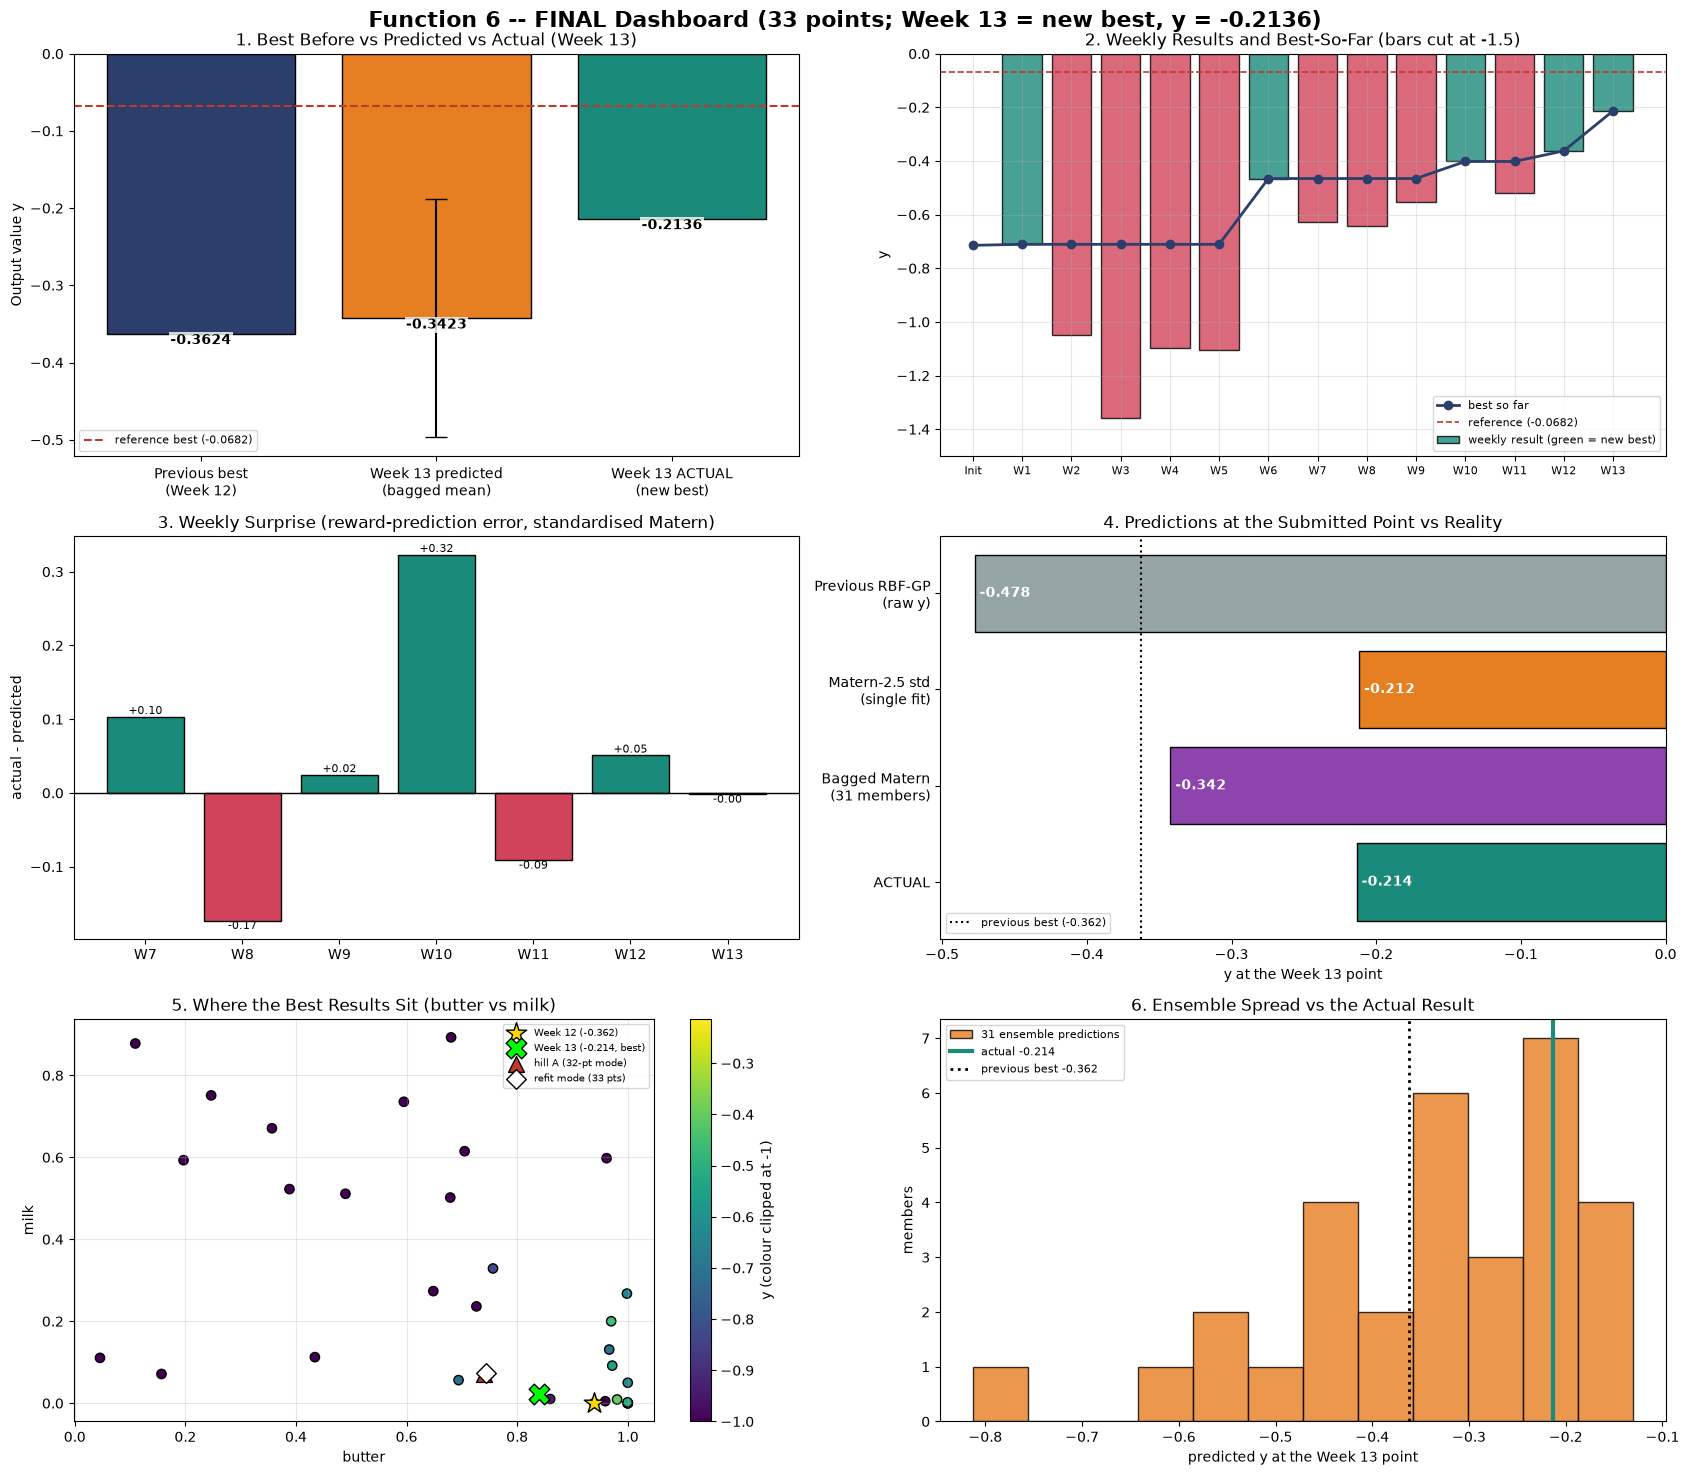

In [239]:
# --- FINAL DASHBOARD ---------------------------------------------------------------------------------
fig = plt.figure(figsize=(17, 15))
gs = fig.add_gridspec(3, 2)

# Panel 1: previous best vs Week 13 predicted vs Week 13 actual
ax = fig.add_subplot(gs[0, 0])
labs = ["Previous best\n(Week 12)", "Week 13 predicted\n(bagged mean)", "Week 13 ACTUAL\n(new best)"]
vals = [prev_best, mean_w13, y13]
bars = ax.bar(labs, vals, yerr=[0, sd_w13, 0], capsize=8, color=["#2c3e6b", "#e67e22", "#1a8a7a"], edgecolor="black")
ax.axhline(-0.068174, color="#c0392b", linestyle="--", linewidth=1.5, label="reference best (-0.0682)")
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.4f}", ha="center", va="top", fontsize=10, fontweight="bold", color="black", bbox=dict(facecolor="white", alpha=0.8, edgecolor="none", pad=1))
ax.set_ylabel("Output value y"); ax.legend(fontsize=8); ax.set_title("1. Best Before vs Predicted vs Actual (Week 13)")

# Panel 2: weekly results and best-so-far, now including Week 13
ax = fig.add_subplot(gs[0, 1])
wk_y = Y[20:]; wk_x = np.arange(1, len(wk_y) + 1)
best_so_far = np.maximum.accumulate(np.concatenate([[Y[:20].max()], wk_y]))
prior_best = np.concatenate([[Y[:20].max()], best_so_far[:-1]])[1:]
ax.bar(wk_x, wk_y, color=["#1a8a7a" if y > p else "#d1435b" for y, p in zip(wk_y, prior_best)], edgecolor="black", alpha=0.8, label="weekly result (green = new best)")
ax.plot(range(0, len(best_so_far)), best_so_far, "o-", color="#2c3e6b", linewidth=2, label="best so far")
ax.axhline(-0.068174, color="#c0392b", linestyle="--", linewidth=1.2, label="reference (-0.0682)")
ax.set_xticks(range(0, len(wk_y) + 1)); ax.set_xticklabels(["Init"] + [f"W{i}" for i in wk_x], fontsize=8)
ax.set_ylim(-1.5, 0.0); ax.set_ylabel("y"); ax.set_title("2. Weekly Results and Best-So-Far (bars cut at -1.5)")
ax.legend(fontsize=8, loc="lower right"); ax.grid(True, alpha=0.3)

# Panel 3: surprise = actual - forward prediction, Weeks 7-13
ax = fig.add_subplot(gs[1, 0])
wks = list(range(7, 14))
ax.bar(wks, surprise, color=["#1a8a7a" if v > 0 else "#d1435b" for v in surprise], edgecolor="black")
ax.axhline(0, color="black", linewidth=1)
for w, v in zip(wks, surprise): ax.text(w, v, f"{v:+.2f}", ha="center", va="bottom" if v > 0 else "top", fontsize=8)
ax.set_xticks(wks); ax.set_xticklabels([f"W{w}" for w in wks]); ax.set_ylabel("actual - predicted")
ax.set_title("3. Weekly Surprise (reward-prediction error, standardised Matern)")

# Panel 4: what each model predicted at the Week 13 point, versus the actual result
ax = fig.add_subplot(gs[1, 1])
names4 = list(pred_rows.keys()) + ["ACTUAL"]; vals4 = list(pred_rows.values()) + [y13]
bars = ax.barh(names4, vals4, color=["#95a5a6", "#e67e22", "#8e44ad", "#1a8a7a"], edgecolor="black"); ax.invert_yaxis()
for b, v in zip(bars, vals4): ax.text(v, b.get_y() + b.get_height() / 2, f" {v:.3f}", va="center", ha="left", fontsize=10, fontweight="bold", color="white")
ax.axvline(prev_best, color="black", linestyle=":", label=f"previous best ({prev_best:.3f})")
ax.set_xlabel("y at the Week 13 point"); ax.legend(fontsize=8, loc="lower left"); ax.set_title("4. Predictions at the Submitted Point vs Reality")

# Panel 5: butter vs milk map, queries coloured by value, with Week 13 and the refit mode
ax = fig.add_subplot(gs[2, 0])
sc = ax.scatter(X[:, 3], X[:, 4], c=np.clip(Y, -1.0, 0), cmap="viridis", edgecolor="black", s=45)
plt.colorbar(sc, ax=ax, label="y (colour clipped at -1)")
ax.scatter(hill_B[3], hill_B[4], marker="*", s=240, c="gold", edgecolor="black", label="Week 12 (-0.362)", zorder=5)
ax.scatter(X_w13_new_point[3], X_w13_new_point[4], marker="X", s=220, c="lime", edgecolor="black", label=f"Week 13 ({y13:.3f}, best)", zorder=6)
ax.scatter(mode_A[3], mode_A[4], marker="^", s=130, c="#c0392b", edgecolor="black", label="hill A (32-pt mode)", zorder=5)
ax.scatter(mode33[3], mode33[4], marker="D", s=100, c="white", edgecolor="black", label="refit mode (33 pts)", zorder=5)
ax.set_xlabel("butter"); ax.set_ylabel("milk"); ax.set_title("5. Where the Best Results Sit (butter vs milk)")
ax.legend(fontsize=7, loc="upper right"); ax.grid(True, alpha=0.3)

# Panel 6: did the ensemble's spread contain the result?
ax = fig.add_subplot(gs[2, 1])
ax.hist(member_means, bins=12, color="#e67e22", edgecolor="black", alpha=0.8, label="31 ensemble predictions")
ax.axvline(y13, color="#1a8a7a", linewidth=3, label=f"actual {y13:.3f}")
ax.axvline(prev_best, color="black", linestyle=":", linewidth=2, label=f"previous best {prev_best:.3f}")
ax.set_xlabel("predicted y at the Week 13 point"); ax.set_ylabel("members"); ax.legend(fontsize=8)
ax.set_title("6. Ensemble Spread vs the Actual Result")

plt.suptitle("Function 6 -- FINAL Dashboard (33 points; Week 13 = new best, y = %.4f)" % y13, fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()